
<br>
<font>
<div dir=ltr align=center>
<font color=0F5298 size=7>
    System 2 - Homework 1<br>
<font color=2565AE size=5>
    Spring 2025<br>
<font color=3C99D size=5>
    Symbolic Regression <br>


---

### Student Number = 403210725

### Full Name = Farzan Rahmani

---

# Introduction

This notebook explores two methods for performing symbolic regression, focusing on both traditional and modern AI-driven approaches:

## 1. EQL-Based Symbolic Regression  
The first approach we implement is based on **Equation Learner (EQL)**, a neural network-based symbolic regression technique. EQL leverages neural networks with activation functions that encourage the discovery of symbolic expressions, making it a differentiable and trainable approach for learning equations directly from data. This method helps in bridging the gap between deep learning and symbolic reasoning.

## 2. Seq2Seq-Based Symbolic Regression with Transformers
A more recent and powerful approach to symbolic regression leverages Sequence-to-Sequence (Seq2Seq) models using Transformers. In this method, we frame symbolic regression as a translation problem, where the input consists of numerical data points and the output is a corresponding mathematical expression. By training a Transformer model on pairs of input data and symbolic expressions, we can enable it to generalize and infer underlying symbolic patterns. This approach benefits from the self-attention mechanism, allowing it to capture long-range dependencies in mathematical structures effectively.


# Datasets

We use two datasets to evaluate our methods:

- **Dataset 1:** This dataset is provided in the notebook, and its underlying mathematical formula is explicitly given. It serves as a reference to assess the performance of different symbolic regression approaches. The expression we consider is: `2 * x + np.sin(x) + x * np.sin(x)`.
  
- **Dataset 2:** This dataset is also provided with the notebook, but its underlying mathematical relationship is hidden. Throughout different parts of the notebook, you will attempt to uncover the equation governing this dataset. Your responses will be evaluated based on how accurately you recover the true formula.

By working through both datasets, we aim to test the robustness and accuracy of various symbolic regression techniques while providing an engaging and exploratory learning experience.

# Import Libraries

In [1]:
import pickle
import numpy as np
import sympy as sp
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from inspect import signature
import time
from tqdm.auto import tqdm
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import sympy
import glob
import time
import signal
import random
import warnings
import json
import re

warnings.filterwarnings('ignore')

# Generate Dataset

In [2]:
def generate_data(func, N, range_min=-2, range_max=2, noise_std=0.1):
    """
    Generates a dataset by evaluating the given function on random input values with added noise.

    Parameters:
    func (callable): A function that takes numerical inputs and returns a scalar output.
    N (int): The number of data points to generate.
    range_min (float, optional): The minimum value of the input range. Default is -2.
    range_max (float, optional): The maximum value of the input range. Default is 2.
    noise_std (float, optional): Standard deviation of Gaussian noise added to function outputs. Default is 0.1.

    Returns:
    tuple: A tuple (x, y) where:
        - x (torch.Tensor): A tensor of shape (N, x_dim), where x_dim is the number of inputs to func.
        - y (torch.Tensor): A tensor of shape (N, 1) containing the noisy function outputs.
    """

    x_dim = len(signature(func).parameters)  # Number of inputs to the function
    x = (range_max - range_min) * torch.rand([N, x_dim]) + range_min
    y = torch.tensor([[func(*x_i)] for x_i in x], dtype=torch.float32)

    # Adding Gaussian noise
    noise = torch.randn(y.shape) * noise_std
    y_noisy = y + noise

    return x, y_noisy

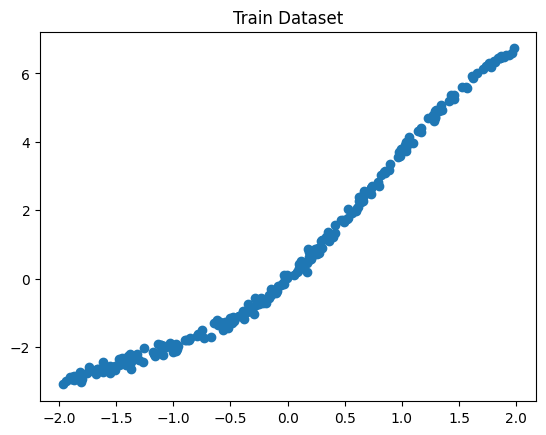

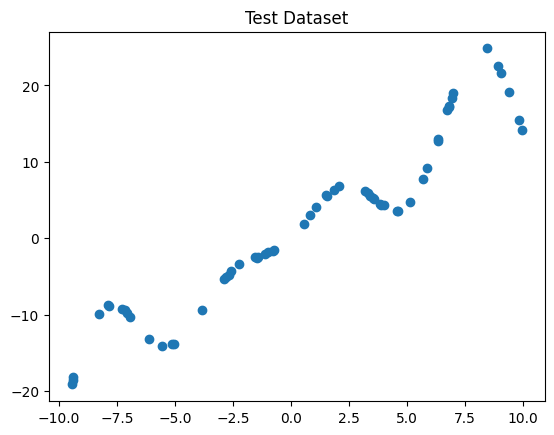

In [3]:
# Define train and test first dataset
x_train, y_train = generate_data(lambda x: 2 * x + np.sin(x) + x * np.sin(x), 240, -2, 2)
plt.scatter(x_train, y_train)
plt.title('Train Dataset')
plt.show()

# We change range_min and range_max here to test its OOD (out-of-distribution) performance
x_test, y_test = generate_data(lambda x: 2 * x + np.sin(x) + x * np.sin(x), 60, -10, 10)
plt.scatter(x_test, y_test)
plt.title('Test Dataset')
plt.show()

# EQL

Equation Learner (EQL) is a neural network-based approach to symbolic regression that discovers mathematical expressions directly from data. Unlike traditional deep learning models that treat regression as a black-box approximation, EQL is designed to output interpretable symbolic expressions. EQL uses a special type of neural network where activation functions are not just standard non-linearities (like ReLU or sigmoid) but include mathematical operations such as addition, multiplication, and trigonometric functions (e.g., sin(x), cos(x)).

<p align="center">
  <img style="margin-top: 30px" src="https://camo.githubusercontent.com/f4722b552bd6d4bd3909ff054ebef8bc4a973d9dd93e2ccacd6c77f4e03e3443/68747470733a2f2f692e696d6775722e636f6d2f485a58776656492e706e67" width="1000">
</p>

### Retrieve expressions

This cell is used to retrieve expressions from the network. Do not modify this cell.

In [ ]:
# DON'T CHNAGE THIS CELL

"""
Generate a mathematical expression for the symbolic regression get_expression (also known as the EQL network) using SymPy.
This expression can be utilized for pretty-printing in various formats, including human-readable text and LaTeX.
Additionally, SymPy enables algebraic manipulation of the expression.
"""

def apply_activation(W, funcs, n_double=0):
    """Given an (n, m) matrix W and (m) vector of funcs, apply funcs to W.

    Arguments:
        W:  (n, m) matrix
        funcs: list of activation functions (SymPy functions)
        n_double:   Number of activation functions that take in 2 inputs

    Returns:
        SymPy matrix with 1 column that represents the output of applying the activation functions.
    """
    W = sp.Matrix(W)
    if n_double == 0:
        for i in range(W.shape[0]):
            for j in range(W.shape[1]):
                W[i, j] = funcs[j](W[i, j])
    else:
        W_new = W.copy()
        out_size = len(funcs)
        for i in range(W.shape[0]):
            in_j = 0
            out_j = 0
            while out_j < out_size - n_double:
                W_new[i, out_j] = funcs[out_j](W[i, in_j])
                in_j += 1
                out_j += 1
            while out_j < out_size:
                W_new[i, out_j] = funcs[out_j](W[i, in_j], W[i, in_j+1])
                in_j += 2
                out_j += 1
        for i in range(n_double):
            W_new.col_del(-1)
        W = W_new
    return W

def sym_pp(W_list, funcs, var_names, threshold=0.01, n_double=0):
    """Pretty print the hidden layers (not the last layer) of the symbolic regression network

    Arguments:
        W_list: list of weight matrices for the hidden layers
        funcs:  list of lambda functions using sympy. has the same size as W_list[i][j, :]
        var_names: list of strings for names of variables
        threshold: threshold for filtering expression. set to 0 for no filtering.
        n_double:   Number of activation functions that take in 2 inputs

    Returns:
        Simplified sympy expression.
    """
    vars = []
    for var in var_names:
        if isinstance(var, str):
            vars.append(sp.Symbol(var))
        else:
            vars.append(var)
    expr = sp.Matrix(vars).T
    # W_list = np.asarray(W_list)
    for W in W_list:
        W = filter_mat(sp.Matrix(W), threshold=threshold)
        expr = expr * W
        expr = apply_activation(expr, funcs, n_double=n_double)
    # expr = expr * W_list[-1]
    return expr

def last_pp(eq, W):
    """Pretty print the last layer."""
    return eq * filter_mat(sp.Matrix(W))

def count_inputs(funcs):
    i = 0
    for func in funcs:
        if isinstance(func, BaseFunction):
            i += 1
        elif isinstance(func, BaseFunction2):
            i += 2
    return i

def count_double(funcs):
    i = 0
    for func in funcs:
        if isinstance(func, BaseFunction2):
            i += 1
    return i

def get_expression(weights, funcs, var_names, threshold=0.01):
    """Pretty print the entire symbolic regression network.

    Arguments:
        weights: list of weight matrices for the entire network
        funcs:  list of lambda functions using sympy. has the same size as W_list[i][j, :]
        var_names: list of strings for names of variables
        threshold: threshold for filtering expression. set to 0 for no filtering.

    Returns:
        Simplified sympy expression."""
    n_double = count_double(funcs)
    funcs = [func.sp for func in funcs]

    expr = sym_pp(weights[:-1], funcs, var_names, threshold=threshold, n_double=n_double)
    expr = last_pp(expr, weights[-1])
    expr = expr[0, 0]
    return expr

def filter_mat(mat, threshold=0.01):
    """Remove elements of a matrix below a threshold."""
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            if abs(mat[i, j]) < threshold:
                mat[i, j] = 0
    return mat

def filter_expr(expr, threshold=0.01):
    expr_new = sp.Integer(0)
    for arg in expr.args:
        if arg.is_constant() and abs(arg) > threshold:   # hack way to check if it's a number
            expr_new = expr_new + arg
        elif not arg.is_constant() and abs(arg.args[0]) > threshold:
            expr_new = expr_new + arg
    return expr_new

def filter_expr2(expr, threshold=0.01):
    for a in sp.preorder_traversal(expr):
        if isinstance(a, sp.Float) and a < threshold:
            expr = expr.subs(a, 0)
    return expr

### Base Functions
These cells contain functions for use in symbolic regression. Each function encapsulates multiple implementations (SymPy, Torch) of a particular operation, allowing them to be used in different contexts. You need to complete the Torch sections.

In [ ]:
# Complete TODO parts

"""Functions for use with symbolic regression.

These functions encapsulate multiple implementations (sympy, torch) of a particular function so that the
functions can be used in multiple contexts."""

class BaseFunction:
    """Abstract class for primitive functions"""
    def __init__(self, norm=1):
        self.norm = norm

    def sp(self, x):
        """Sympy implementation"""
        return None

    def torch(self, x):
        """No need for base function"""
        return None

    def name(self, x):
        return str(self.sp)

class Constant(BaseFunction):
    def torch(self, x):
        return torch.ones_like(x)

    def sp(self, x):
        return 1

class Identity(BaseFunction):
    """
    A function class that applies an identity transformation with normalization.

    Attributes:
    norm (float): A normalization factor that scales the input.

    Methods:
    torch(x: torch.Tensor) -> torch.Tensor:
        Applies the identity transformation by dividing the input by the normalization factor.
    """

    def torch(self, x: torch.Tensor) -> torch.Tensor:
        """
        Applies the identity function with normalization.

        Parameters:
        x (torch.Tensor): The input tensor.

        Returns:
        torch.Tensor: The normalized output tensor.

        """
        # ================ TODO ================
        return x / self.norm
        # ======================================
    def sp(self, x):
        return x / self.norm

class Square(BaseFunction):
    """
    A function class that applies a squared transformation with normalization.

    Methods:
    torch(x: torch.Tensor) -> torch.Tensor:
        Returns the squared value of the input, divided by the normalization factor.
    """

    def torch(self, x: torch.Tensor) -> torch.Tensor:
        """
        Applies the squared function with normalization.

        Parameters:
        x (torch.Tensor): The input tensor.

        Returns:
        torch.Tensor: The squared output tensor divided by the normalization factor.
        """
        # ================ TODO ================
        return torch.square(x) / self.norm
        # return torch.pow(x, 2) / self.norm
        # return (x ** 2) / self.norm
        # ======================================


    def sp(self, x):
        return x ** 2 / self.norm

class Pow(BaseFunction):
    """
    A function class that raises the input to a given power and normalizes the result.

    Attributes:
    power (float): The exponent to which the input is raised.

    Methods:
    torch(x: torch.Tensor) -> torch.Tensor:
        Raises the input to the specified power and divides by the normalization factor.
    """

    def __init__(self, power: float, norm: float = 1):
        """
        Initializes the Pow function with a given exponent and normalization factor.

        Parameters:
        power (float): The exponent for the power function.
        norm (float, optional): The normalization factor. Default is 1.
        """

        BaseFunction.__init__(self, norm=norm)
        self.power = power

    def torch(self, x: torch.Tensor) -> torch.Tensor:
        """
        Applies the power function with normalization.

        Parameters:
        x (torch.Tensor): The input tensor.

        Returns:
        torch.Tensor: The output tensor, where each element is raised to the given power and normalized.
        """
        # ================ TODO ================
        return torch.pow(x, self.power) / self.norm
        # return (x ** self.power) / self.norm
        # ======================================


    def sp(self, x):
        return x ** self.power / self.norm

class Sin(BaseFunction):
    """
    A function class that applies a sine transformation with frequency scaling and normalization.

    Methods:
    torch(x: torch.Tensor) -> torch.Tensor:
        Applies a sine transformation to the input and divides by the normalization factor.
    """

    def torch(self, x: torch.Tensor) -> torch.Tensor:
        """
        Applies the sine function with frequency scaling and normalization.

        Parameters:
        x (torch.Tensor): The input tensor.

        Returns:
        torch.Tensor: The sine-transformed tensor divided by the normalization factor.
        """

        # ================ TODO ================
        return torch.sin(x * 2 * 2 * np.pi) / self.norm
        # ======================================


    def sp(self, x):
        return sp.sin(x * 2*2*np.pi) / self.norm

class Sigmoid(BaseFunction):
    """
    A function class that applies the sigmoid function with normalization.

    Methods:
    torch(x: torch.Tensor) -> torch.Tensor:
        Applies the sigmoid function and divides by the normalization factor.
    """

    def torch(self, x: torch.Tensor) -> torch.Tensor:
        """
        Applies the sigmoid function with normalization.

        Parameters:
        x (torch.Tensor): The input tensor.

        Returns:
        torch.Tensor: The sigmoid-transformed tensor divided by the normalization factor.
        """

        # ================ TODO ================
        # return torch.sigmoid(x) / self.norm
        return torch.sigmoid(20*x) / self.norm # according to sp implementation
        # ======================================


    def sp(self, x):
        return 1 / (1 + sp.exp(-20*x)) / self.norm

    def name(self, x):
        return "sigmoid(x)"

class Exp(BaseFunction):
    """
    A function class that applies an exponential transformation with normalization.

    Methods:
    torch(x: torch.Tensor) -> torch.Tensor:
        Applies the exponential function (subtracting 1) and divides by the normalization factor.
    """

    def __init__(self, norm: float = np.e):
        """
        Initializes the Exp function with a normalization factor.

        Parameters:
        norm (float, optional): The normalization factor. Default is Euler's number (e).
        """
        super().__init__(norm)

    def torch(self, x: torch.Tensor) -> torch.Tensor:
        """
        Applies the modified exponential function with normalization.

        Parameters:
        x (torch.Tensor): The input tensor.

        Returns:
        torch.Tensor: The transformed tensor, where exp(x) - 1 is computed and divided by the normalization factor.
        """

        # ================ TODO ================
        return (torch.exp(x) - 1) / self.norm
        # ======================================

    def sp(self, x):
        return (sp.exp(x) - 1) / self.norm

class Log(BaseFunction):
    """
    A function class that applies the logarithm function with normalization.

    Methods:
    torch(x: torch.Tensor) -> torch.Tensor:
        Applies the logarithm function (on the absolute value of input) and divides by the normalization factor.
    """

    def torch(self, x: torch.Tensor) -> torch.Tensor:
        """
        Applies the logarithm function with normalization.

        Parameters:
        x (torch.Tensor): The input tensor.

        Returns:
        torch.Tensor: The log-transformed tensor divided by the normalization factor.
        """

        # ================ TODO ================
        return torch.log(torch.abs(x)) / self.norm
        # return torch.log(torch.abs(x) + 1e-7) / self.norm  # Add epsilon for stability
        # ======================================

    def sp(self, x):
        return sp.log(sp.Abs(x)) / self.norm

class BaseFunction2:
    """Abstract class for primitive functions with 2 inputs"""
    def __init__(self, norm=1.):
        self.norm = norm

    def sp(self, x, y):
        """Sympy implementation"""
        return None

    def torch(self, x, y):
        return None

    def name(self, x, y):
        return str(self.sp)

class Product(BaseFunction2):
    """
    A function class that computes the product of two inputs with normalization.

    Methods:
    torch(x: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
        Computes the product of two input tensors and divides by the normalization factor.
    """

    def __init__(self, norm: float = 0.1):
        """
        Initializes the Product function with a normalization factor.

        Parameters:
        norm (float, optional): The normalization factor. Default is 0.1.
        """
        super().__init__(norm=norm)

    def torch(self, x: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
        """
        Computes the product of two input tensors with normalization.

        Parameters:
        x (torch.Tensor): The first input tensor.
        y (torch.Tensor): The second input tensor.

        Returns:
        torch.Tensor: The element-wise product of x and y, divided by the normalization factor.
        """

        # ================ TODO ================
        return (x * y) / self.norm
        # ======================================

    def sp(self, x, y):
        return x * y / self.norm


### Model Architecture

In this section, we define the architecture of the symbolic regression neural network using the Equation Learner (EQL) approach. The model is designed to learn mathematical expressions by incorporating activation functions that correspond to primitive mathematical operations.

1. SymbolicLayer: Each layer applies a set of predefined functions (e.g., sin(x), cos(x), x^2, etc.). The weight matrix determines how input features are transformed and combined. Functions are applied either as single-input (f(x)) or double-input (f(x, y)) operations.

2. SymbolicNet: Composed of multiple SymbolicLayer instances. Uses trainable weight matrices to learn meaningful expressions. The final layer outputs a weighted sum without an activation function.

In [ ]:
"""Contains the symbolic regression neural network architecture."""
import numpy as np
import torch
import torch.nn as nn

class SymbolicLayer(nn.Module):
    """Neural network layer for symbolic regression where activation functions correspond to primitive functions.
    Can take multi-input activation functions (like multiplication)"""

    def __init__(self, funcs, initial_weight=None, init_stddev=0.1, in_dim=None):
        """
        funcs: List of activation functions, using utils.functions
        initial_weight: (Optional) Initial value for weight matrix
        variable: Boolean of whether initial_weight is a variable or not
        init_stddev: (Optional) if initial_weight isn't passed in, this is standard deviation of initial weight

        Parameters need to define:

        - self.W: The weight matrix of the layer. It maps the input features to the output functions. If an `initial_weight` is provided, it is used as the initial weight matrix.
                  Otherwise, it is initialized from a normal distribution with mean 0 and standard deviation `init_stddev`.
        """

        # This structure of this network is just a suggested. If you want you can make a different network but it should implement EQL.

        super().__init__()


        self.output = None  # tensor for layer output

        self.n_funcs = len(funcs)                       # Number of activation functions (and number of layer outputs)
        self.funcs = [func.torch for func in funcs]     # Convert functions to list of PyTorch functions

        self.n_double = count_double(funcs)   # Number of activation functions that take 2 inputs
        self.n_single = self.n_funcs - self.n_double    # Number of activation functions that take 1 input

        self.out_dim = self.n_funcs + self.n_double


        self.initial_weight = initial_weight


        # Define and initialize the weight matrix `W`.
        # If `initial_weight` is provided, use it; otherwise, initialize with a normal distribution.

        # =================================== TODO ===================================
        # if initial_weight is not None:
        #     self.W = nn.Parameter(torch.tensor(initial_weight, dtype=torch.float32))
        # else:
        #     if in_dim is None:
        #         in_dim = self.n_single + 2*self.n_double
        #     self.W = nn.Parameter(torch.randn(in_dim, self.out_dim) * init_stddev)

        if in_dim is None:
            in_dim = self.n_single + 2*self.n_double  # Single inputs + double inputs

        if initial_weight is not None:
            self.W = nn.Parameter(torch.tensor(initial_weight, dtype=torch.float32))
        else:
            self.W = nn.Parameter(torch.randn(in_dim, self.out_dim) * init_stddev)
        # ============================================================================

    def forward(self, x):

        """
        Computes the forward pass of the layer.

        Args:
            x (torch.Tensor): Input tensor of shape (batch_size, in_dim).

        Returns:
            torch.Tensor: Output tensor after applying the symbolic functions.

        Process:
            1. Multiply input `x` with weight matrix `W` to get weighted sum `g`.
            2. Apply the activation functions:
               - Single-input functions take one element from `g`.
               - Two-input functions take two elements from `g` and produce a single output.
            3. Stack all function outputs into a single tensor.
        """


        # =================================== TODO ===================================
        # Ensure input has correct shape [batch_size, in_dim]
        if x.dim() == 1:
            x = x.unsqueeze(0)
        # if x.size(1) != self.W.size(0):
        #     raise ValueError(f"Input dimension mismatch. Expected {self.W.size(0)}, got {x.size(1)}")


        g = torch.matmul(x, self.W) # g = x @ self.W

        outputs = []
        idx = 0

        # Process single-input functions
        for i in range(self.n_single):
            outputs.append(self.funcs[i](g[:, idx]))
            idx += 1

        # Process double-input functions
        for i in range(self.n_single, self.n_funcs):
            outputs.append(self.funcs[i](g[:, idx], g[:, idx+1]))
            idx += 2

        self.output = torch.stack(outputs, dim=1)
        return self.output

        # ============================================================================

    def get_weight(self):
        # don't change this function
        return self.W.cpu().detach().numpy()

    def get_weight_tensor(self):
        # don't change this function
        return self.W.clone()

class SymbolicNet(nn.Module):
    """Symbolic regression network with multiple layers. Produces one output."""
    def __init__(self, symbolic_depth, in_dim=1, funcs=None, initial_weights=None, init_stddev=0.1):
        super(SymbolicNet, self).__init__()

        """
        Initializes the symbolic regression network.

        Parameters:
        symbolic_depth (int): The number of hidden layers in the network.
        funcs (list): A list of functions to be used in each layer of the network.
        initial_weights (list or None): Predefined initial weights for each layer. If None, the network will initialize weights randomly.
        init_stddev (float or list): Standard deviation for weight initialization. If a list, each layer will have its own stddev for initialization.

        Hints:
        The first layer will have 1 input dimension (the data itself), and subsequent layers will have the same number of functions as the depth.
        If predefined weights are provided, initialize layers with those weights. otherwise Initialize the network randomly if no initial weights are provided.
        Don't foget to Initialize the output weight (no activation function applied there).

        **Parametrs to define** :

        - self.depth: The number of hidden layers in the network. It determines how many `SymbolicLayer` instances are stacked in the model.

        - self.hidden_layers: A sequential container (`nn.Sequential`) that stores the hidden layers of the network.
                              Each layer is an instance of `SymbolicLayer`, and they are initialized with the provided  activation functions and weights.

        - self.output_weight: A parameter representing the weight matrix for the final layer, mapping the last hidden  layer's output to a single output value.
                              This weight is either initialized from  `initial_weights` (if provided) or randomly initialized when `initial_weights` is None.
        """

        # =================================== TODO ===================================
        self.depth = symbolic_depth

        # Initialize hidden layers
        # self.hidden_layers = nn.Sequential()
        # current_in_dim = in_dim

        # for i in range(symbolic_depth):
        #     layer_initial = initial_weights[i] if initial_weights else None
        #     layer = SymbolicLayer(funcs, layer_initial, init_stddev, current_in_dim)
        #     self.hidden_layers.add_module(f'layer_{i}', layer)
        #     current_in_dim = layer.n_funcs

        # layers = []
        # for i in range(symbolic_depth):
        #     if initial_weights is not None:
        #         layer = SymbolicLayer(funcs, initial_weight=initial_weights[i], in_dim=in_dim)
        #     else:
        #         layer = SymbolicLayer(funcs, init_stddev=init_stddev, in_dim=in_dim)
        #     layers.append(layer)
        #     in_dim = len(funcs) + count_double(funcs)  # Update input dim for next layer

        # self.hidden_layers = nn.Sequential(*layers)

        # # Initialize output weight
        # if initial_weights is not None and len(initial_weights) > symbolic_depth:
        #     self.output_weight = nn.Parameter(torch.tensor(initial_weights[-1], dtype=torch.float32))
        # else:
        #     output_dim = len(funcs) + count_double(funcs)
        #     self.output_weight = nn.Parameter(torch.randn(output_dim, 1) * init_stddev)

        layers = []
        current_in_dim = in_dim
        for i in range(symbolic_depth):
            if initial_weights is not None:
                layer = SymbolicLayer(funcs, initial_weight=initial_weights[i], in_dim=current_in_dim)
            else:
                layer = SymbolicLayer(funcs, init_stddev=init_stddev, in_dim=current_in_dim)
            layers.append(layer)
            current_in_dim = len(funcs)  # Output dim becomes input dim for next layer
            # current_in_dim = layer.n_funcs

        self.hidden_layers = nn.Sequential(*layers)

        # Initialize output weight
        output_dim = len(funcs)
        # output_dim = layer.n_funcs
        if initial_weights is not None and len(initial_weights) > symbolic_depth:
            self.output_weight = nn.Parameter(torch.tensor(initial_weights[-1], dtype=torch.float32))
        else:
            self.output_weight = nn.Parameter(torch.randn(output_dim, 1) * init_stddev)
        # ============================================================================


    def forward(self, input):
        """
        Defines the forward pass of the network.

        Parameters:
        input (Tensor): The input tensor to the network.

        Returns:
        Tensor: Final output of the network after passing through all layers
        """
        # =================================== TODO ===================================
        x = input
        for layer in self.hidden_layers:
            x = layer(x)
        output = torch.matmul(x, self.output_weight) # x @ self.output_weight
        return output
        # ============================================================================

    def get_weights(self):
        """Return list of weight matrices"""
        # First part is iterating over hidden weights. Then append the output weight.
        # Don't change this function
        return [self.hidden_layers[i].get_weight() for i in range(self.depth)] + \
               [self.output_weight.cpu().detach().numpy()]

    def get_weights_tensor(self):
        """Return list of weight matrices as tensors"""
        # Don't change this function
        return [self.hidden_layers[i].get_weight_tensor() for i in range(self.depth)] + \
               [self.output_weight.clone()]

### Training phase

In [ ]:
def train(
    x_train,  # Tensor: Input training data
    y_train,  # Tensor: Target training data
    activation_funcs,  # List of activation functions for each layer
    in_dim, # input dimension
    n_layers,  # Integer: Number of layers in the symbolic regression network
    learning_rate,  # Float: Learning rate for optimization
    summary_step,  # Integer: Interval for logging training progress
    epochs,  # Integer: Number of training epochs
    device="cuda"  # String: Device to perform training on ("cuda" for GPU, "cpu" otherwise)
):
    """
    This function trains a symbolic regression network using the provided training data.

    1. Initializes a `SymbolicNet` object, which represents the symbolic regression model.
    2. The training loop continues as long as the loss is not NaN. If NaN loss occurs, the training will restart.
    3. Optionally, logging can be done at every `summary_step` epoch to track the loss.
    4. (Optional) You can train the network with the full batch of training data.


    Returns:
    - net: The trained symbolic regression network.


    Notes:
    - Feel free to modify the structure if needed. However, keep in mind that extracting expressions requires access to the model's (SymbolicNet) weights.
    """

    # ======================================= TODO =======================================
    # net = SymbolicNet(n_layers, in_dim, activation_funcs)
    # net.to(device)
    # optimizer = optim.Adam(net.parameters(), lr=learning_rate)
    # x_train, y_train = x_train.to(device), y_train.to(device)

    # for epoch in range(epochs):
    #     optimizer.zero_grad()
    #     outputs = net(x_train)
    #     mse_loss = F.mse_loss(outputs, y_train)

    #     # L1 regularization
    #     l1_reg = torch.tensor(0., device=device)
    #     for param in net.parameters():
    #         l1_reg += torch.norm(param, 1)

    #     loss = mse_loss + reg_weight * l1_reg
    #     loss.backward()
    #     optimizer.step()

    #     if epoch % summary_step == 0:
    #         print(f'Epoch {epoch}: Loss = {loss.item():.4f}')

    # return net


    # Move data to device
    x_train, y_train = x_train.to(device), y_train.to(device)

    best_loss = float('inf')
    best_net = None

    while True:
        # Initialize network
        net = SymbolicNet(n_layers, in_dim=in_dim, funcs=activation_funcs).to(device)
        optimizer = optim.Adam(net.parameters(), lr=learning_rate)

        try:
            # for epoch in range(epochs):
            for epoch in tqdm(range(epochs), desc="Training..."): # Wrap range(epochs) with tqdm

                optimizer.zero_grad()
                outputs = net(x_train)
                loss = F.mse_loss(outputs, y_train)

                # L1 regularization
                l1_reg = torch.tensor(0., device=device)
                for param in net.parameters():
                    l1_reg += torch.norm(param, 1)
                loss += reg_weight * l1_reg

                loss.backward()
                optimizer.step()

                if np.isnan(loss.item()):
                    raise ValueError("NaN loss encountered")

                if epoch % summary_step == 0:
                    print(f"Epoch {epoch}, Loss: {loss.item()}")

            if loss.item() < best_loss:
                best_loss = loss.item()
                best_net = net

            return best_net

        except ValueError as e:
            print(f"Training failed: {e}. Restarting...")
            continue
    # ====================================================================================


def test(net, x_test, y_test, device="cuda"):
    """
    This function tests a symbolic regression network using the provided test data.

    Parameters:
    - net: The trained symbolic regression network (instance of SymbolicNet).
    - x_test: Tensor, the input test data.
    - y_test: Tensor, the target test data.
    - device: String, the device where the test will occur (default is "cuda" for GPU).

    Returns:
    - test_loss: test loss value.
    """

    x_test, y_test = x_test.to(device), y_test.to(device)
    with torch.no_grad():  # test error
        test_outputs = net(x_test)
        test_loss = F.mse_loss(test_outputs, y_test)

    if np.isnan(test_loss.item()):
        return float('inf')
    return test_loss.item()


In [ ]:
# Don't change this cell

# Define the function that evaluates the expression
def symbolic_function(expr_str, x):
    return eval(expr_str, {"x_1": x, "x1": x, "np": np, "sin": np.sin, "cos": np.cos, "exp": np.exp})

# Function to plot the symbolic regression output and test dataset
def plot_symbolic(x_test, y_test, expr_str):
    x_values = np.linspace(-10, 10, 50)
    y_values = np.array([symbolic_function(expr_str, x) for x in x_values])

    plt.figure(figsize=(10, 5))
    plt.plot(x_values, y_values, label="Symbolic Regression Output", color='b')
    plt.scatter(x_test, y_test, label="Test Dataset", color='r', s=5)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Best results of Symbolic Regression")
    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:
def find_expression(net, x_dim):
  with torch.no_grad():
      weights = net.get_weights()
      expr_str = get_expression(weights, activation_funcs, var_names[:x_dim])
      return expr_str

def run(x_train, x_test, y_train, y_test, activation_funcs, n_layers, learning_rate, summary_step, epochs, trials = 10):
    """
    This function runs the training and testing process for multiple trials.

    The function performs the following steps:
    1. **Training and Testing**: The symbolic regression network is trained and tested for a specified number of trials (default is 10). In each trial:
        - A new model is initialized and trained on the provided training data (`x_train`, `y_train`).
        - The model is then evaluated on the test data (`x_test`, `y_test`) to calculate the test loss (Mean Squared Error).
        - The corresponding symbolic expression is extracted using the `find_expression` function.

    2. **Trial Comparison**: After running all the trials, the best model is selected based on the lowest test loss. This ensures that the model with the best generalization performance is chosen.

    3. **Result Plotting**: The symbolic expression corresponding to the model with the lowest test loss is plotted using the `plot_symbolic` function. The expression is processed to ensure compatibility with NumPy functions (e.g., replacing `exp` with `np.exp` and `sin` with `np.sin`).


    Parameters:
    - No parameters; the function assumes `x_train`, `x_test`, `y_train`, and `y_test` are already defined globally or passed externally.

    Returns:
    - None: The function performs training and testing, logs results, and plots the best model's symbolic expression.
    """

    # ============================================= TODO =============================================
    test_losses = []
    expressions = []
    x_dim = x_train.shape[1]

    for trial in range(trials):
        print(f"\nTrial {trial + 1}/{trials} started")

        # Train the network
        net = train(x_train, y_train, activation_funcs, x_dim, n_layers,
                   learning_rate, summary_step, epochs)

        # Test the network
        current_loss = test(net, x_test, y_test)
        test_losses.append(current_loss)

        # Get the expression
        expr = find_expression(net, x_dim)
        expressions.append(expr)

        print(f"Test Loss: {current_loss}")
        print(f"Expression: {expr}")
    # ================================================================================================


    best_index = np.argmin(np.array(test_losses))
    return str(expressions[best_index])


Trial 1  / 1 Started


  0%|                                                                                 | 7/20000 [00:00<04:52, 68.34it/s]

Epoch: 0, Loss: 9.663416862487793, 


  5%|███▉                                                                          | 1012/20000 [00:13<04:07, 76.61it/s]

Epoch: 1000, Loss: 0.44028356671333313, 


 10%|███████▊                                                                      | 2011/20000 [00:25<04:19, 69.44it/s]

... (33 outputs left out)

 95%|█████████████████████████████████████████████████████████████████████████▏   | 19012/20000 [03:46<00:13, 75.44it/s]

Epoch: 19000, Loss: 0.008784736506640911, 


100%|█████████████████████████████████████████████████████████████████████████████| 20000/20000 [03:58<00:00, 83.71it/s]


Test Loss: 10619.529296875


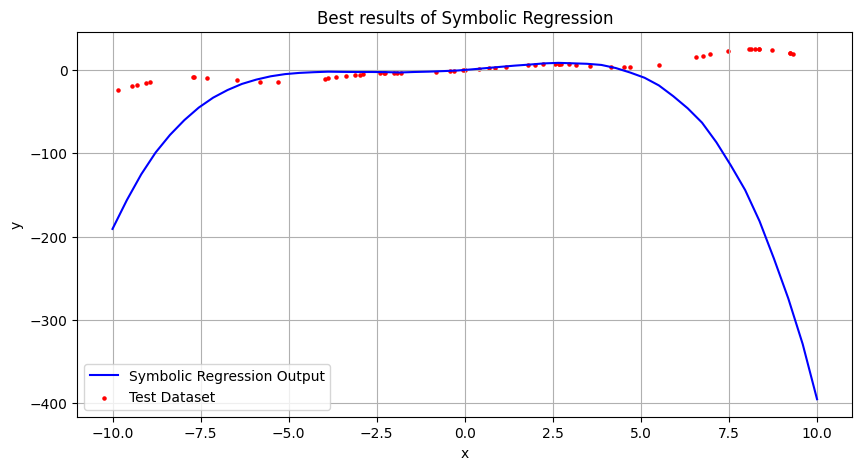

In [ ]:
# activation_funcs = [
#     *[Constant()] * 2,
#     *[Identity()] * 4,
#     *[Square()] * 4,
#     *[Sin()] * 2,
#     *[Exp()] * 2,
#     *[Sigmoid()] * 2,
#     *[Product()] * 2,
# ]


# var_names = ["x_1", "x_2"]      # This is the name of vars to show at the end.


# n_layers = 2                  # TODO: Number of hidden layers
# reg_weight = .01             # TODO: Regularization weight
# learning_rate = .001          # TODO: Learning rate
# summary_step = 1000           # TODO: Number of steps between logging summaries
# epochs = 20000                # TODO: Number of epochs
# trials = 3                    # TODO: Number of trials. note that it should be at least 5.

# best_expr = run(x_train, x_test, y_train, y_test, activation_funcs, n_layers, learning_rate, summary_step, epochs, trials)
# plot_symbolic(x_test, y_test, best_expr.replace("exp", "np.exp").replace("sin", "np.sin"))



Trial 1/5 started


Training...:   0%|          | 0/10000 [00:00<?, ?it/s]

Epoch 0, Loss: 13.033975601196289
Epoch 1000, Loss: 0.19737134873867035
Epoch 2000, Loss: 0.12243203818798065
Epoch 3000, Loss: 0.08019711822271347
Epoch 4000, Loss: 0.06082390993833542
Epoch 5000, Loss: 0.05217593163251877
Epoch 6000, Loss: 0.049818649888038635
Epoch 7000, Loss: 0.04680662974715233
Epoch 8000, Loss: 0.04259597137570381
Epoch 9000, Loss: 0.04179276525974274
Test Loss: 223.9359130859375
Expression: -8.52455794811249*(0.395112*sin(0.677159171974709*x_1) + 0.540745*sin(0.764895588880067*x_1))*(-0.0265848898571275*x_1**2 - 0.22297*sin(0.764895588880067*x_1) - 0.51106)

Trial 2/5 started


Training...:   0%|          | 0/10000 [00:00<?, ?it/s]

Epoch 0, Loss: 12.429794311523438
Epoch 1000, Loss: 0.16730061173439026
Epoch 2000, Loss: 0.11112653464078903
Epoch 3000, Loss: 0.08531447499990463
Epoch 4000, Loss: 0.07049351930618286
Epoch 5000, Loss: 0.060158248990774155
Epoch 6000, Loss: 0.05571143329143524
Epoch 7000, Loss: 0.04740801453590393
Epoch 8000, Loss: 0.04570881277322769
Epoch 9000, Loss: 0.04092836380004883
Test Loss: 233.64572143554688
Expression: -8.43959867954254*(-0.468853*sin(0.663776210132059*x_1) - 0.444761*sin(0.766242082086914*x_1))*(0.025677960820808*x_1**2 + 0.242197*sin(0.766242082086914*x_1) + 0.539806)

Trial 3/5 started


Training...:   0%|          | 0/10000 [00:00<?, ?it/s]

Epoch 0, Loss: 12.506969451904297
Epoch 1000, Loss: 0.17374403774738312
Epoch 2000, Loss: 0.10875412821769714
Epoch 3000, Loss: 0.08172361552715302
Epoch 4000, Loss: 0.06520276516675949
Epoch 5000, Loss: 0.05245087295770645
Epoch 6000, Loss: 0.047691281884908676
Epoch 7000, Loss: 0.04230186715722084
Epoch 8000, Loss: 0.040975358337163925
Epoch 9000, Loss: 0.040961503982543945
Test Loss: 230.79867553710938
Expression: 8.65555763244629*(0.51232*sin(0.679642200385666*x_1) + 0.397032*sin(0.770167758384232*x_1))*(0.0256915487186954*x_1**2 + 0.0232995*sin(0.679642200385666*x_1) + 0.213969*sin(0.770167758384232*x_1) + 0.524564)

Trial 4/5 started


Training...:   0%|          | 0/10000 [00:00<?, ?it/s]

Epoch 0, Loss: 12.024222373962402
Epoch 1000, Loss: 0.149850532412529
Epoch 2000, Loss: 0.10176996886730194
Epoch 3000, Loss: 0.0756063386797905
Epoch 4000, Loss: 0.060386382043361664
Epoch 5000, Loss: 0.048730481415987015
Epoch 6000, Loss: 0.043179951608181
Epoch 7000, Loss: 0.0422745943069458
Epoch 8000, Loss: 0.041791994124650955
Epoch 9000, Loss: 0.04092788323760033
Test Loss: 229.85525512695312
Expression: 8.38041961193085*(0.394769*sin(0.658105471523034*x_1) + 0.532378*sin(0.761807637991661*x_1))*(0.0260894929444255*x_1**2 + 0.240242*sin(0.761807637991661*x_1) + 0.5321)

Trial 5/5 started


Training...:   0%|          | 0/10000 [00:00<?, ?it/s]

Epoch 0, Loss: 11.969932556152344
Epoch 1000, Loss: 0.17557145655155182
Epoch 2000, Loss: 0.11609227955341339
Epoch 3000, Loss: 0.08703599125146866
Epoch 4000, Loss: 0.06811103224754333
Epoch 5000, Loss: 0.060508158057928085
Epoch 6000, Loss: 0.048382218927145004
Epoch 7000, Loss: 0.04375737905502319
Epoch 8000, Loss: 0.04118145629763603
Epoch 9000, Loss: 0.04096526652574539
Test Loss: 231.30224609375
Expression: -8.28504383563995*(0.423448*sin(0.660822800893566*x_1) + 0.505972*sin(0.763055589036688*x_1))*(-0.0261526054689654*x_1**2 - 0.242435*sin(0.763055589036688*x_1) - 0.537958)


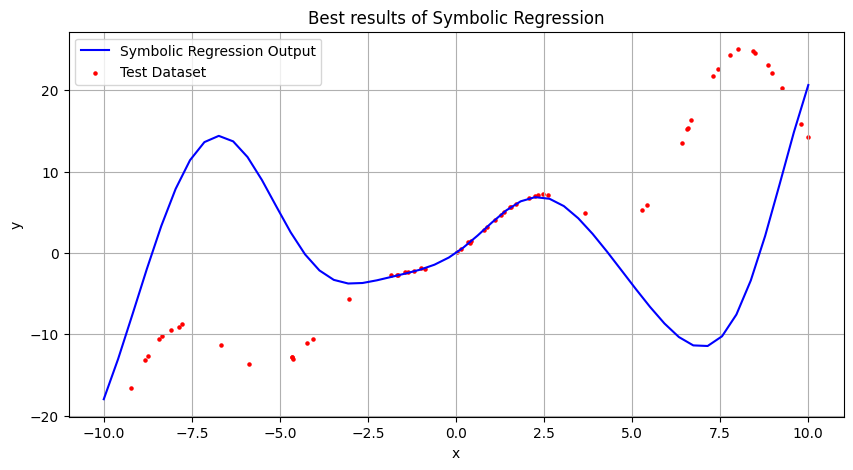

Best expression for Dataset 1: -8.52455794811249*(0.395112*sin(0.677159171974709*x_1) + 0.540745*sin(0.764895588880067*x_1))*(-0.0265848898571275*x_1**2 - 0.22297*sin(0.764895588880067*x_1) - 0.51106)


In [ ]:
activation_funcs = [
    *[Constant()] * 2,
    *[Identity()] * 4,
    *[Square()] * 4,
    *[Sin()] * 2,
    *[Exp()] * 2,
    *[Sigmoid()] * 2,
    *[Product()] * 2,
]

var_names = ["x_1", "x_2"]      # This is the name of vars to show at the end.

n_layers = 2                  # TODO: Number of hidden layers
reg_weight = .01             # TODO: Regularization weight
learning_rate = .0009          # TODO: Learning rate
summary_step = 1000           # TODO: Number of steps between logging summaries
epochs = 10000 # 20000                # TODO: Number of epochs
trials = 5                    # TODO: Number of trials. note that it should be at least 5.

best_expr = run(x_train, x_test, y_train, y_test, activation_funcs, n_layers, learning_rate, summary_step, epochs, trials)
best_expr1 = best_expr # best_expr1 is used in bonus parts
plot_symbolic(x_test, y_test, best_expr.replace("exp", "np.exp").replace("sin", "np.sin"))
print(f"Best expression for Dataset 1: {best_expr}")


Number of layers: 3

Trial 1/5 started


Training...:   0%|          | 0/10000 [00:00<?, ?it/s]

Epoch 0, Loss: 13.643258094787598
Epoch 1000, Loss: 0.21091113984584808
Epoch 2000, Loss: 0.1257568597793579
Epoch 3000, Loss: 0.07680241763591766
Epoch 4000, Loss: 0.056291915476322174
Epoch 5000, Loss: 0.04841645061969757
Epoch 6000, Loss: 0.0461280420422554
Epoch 7000, Loss: 0.04582307115197182
Epoch 8000, Loss: 0.044439949095249176
Epoch 9000, Loss: 0.04396182298660278
Test Loss: 197.72085571289062
Expression: -18.2119316883476*(0.0217329*sin(0.576200035421431*x_1) + 0.583972)*(-0.271193131717307*(0.0217329*sin(0.576200035421431*x_1) + 0.583972)*sin(0.576200035421431*x_1) - 0.124051*sin(0.533016191749577*sin(1.29539340811789*x_1) + 0.525783337512166) - 0.433873)*sin(0.576200035421431*x_1)

Trial 2/5 started


Training...:   0%|          | 0/10000 [00:00<?, ?it/s]

Epoch 0, Loss: 12.2100830078125
Epoch 1000, Loss: 0.22780856490135193
Epoch 2000, Loss: 0.1294892579317093
Epoch 3000, Loss: 0.0865941196680069
Epoch 4000, Loss: 0.06742174178361893
Epoch 5000, Loss: 0.05591685324907303
Epoch 6000, Loss: 0.052589986473321915
Epoch 7000, Loss: 0.051049958914518356
Epoch 8000, Loss: 0.049751851707696915
Epoch 9000, Loss: 0.04867188259959221
Test Loss: 292.7669982910156
Expression: -4.88164961338043*(0.53112944875684*sin(0.711033566750648*x_1) + 0.842884076730321*sin(0.755685009839623*x_1))*(-4.35215055942535*(0.00919740069501383*x_1**2 + 0.375506)*(0.0101321138477113*x_1**2 + 0.367525) - 0.107618243294921*sin(0.711033566750648*x_1) - 0.170786432293094*sin(0.755685009839623*x_1))

Trial 3/5 started


Training...:   0%|          | 0/10000 [00:00<?, ?it/s]

Epoch 0, Loss: 11.759040832519531
Epoch 1000, Loss: 0.24294739961624146
Epoch 2000, Loss: 0.1254287213087082
Epoch 3000, Loss: 0.07949181646108627
Epoch 4000, Loss: 0.05707871541380882
Epoch 5000, Loss: 0.04915681108832359
Epoch 6000, Loss: 0.045005761086940765
Epoch 7000, Loss: 0.0437588095664978
Epoch 8000, Loss: 0.04374149069190025
Epoch 9000, Loss: 0.04376736655831337
Test Loss: 232.7823944091797
Expression: 20.6484689691043*(0.326468*sin(0.601269863588973*x_1) + 0.277529*sin(0.786787490845656*x_1))*(0.0136155830269558*x_1**2 + 0.146448*sin(0.786787490845656*x_1) + 0.346635)

Trial 4/5 started


Training...:   0%|          | 0/10000 [00:00<?, ?it/s]

Epoch 0, Loss: 12.691264152526855
Epoch 1000, Loss: 0.17777803540229797
Epoch 2000, Loss: 0.10220719128847122
Epoch 3000, Loss: 0.06916835904121399
Epoch 4000, Loss: 0.0552595816552639
Epoch 5000, Loss: 0.04790021851658821
Epoch 6000, Loss: 0.04463370516896248
Epoch 7000, Loss: 0.043860238045454025
Epoch 8000, Loss: 0.04375622048974037
Epoch 9000, Loss: 0.043636541813611984
Test Loss: 148.94711303710938
Expression: -5.01033127307892*(-1.22612817701064*sin(0.630294017841498*x_1) - 0.941907945739882*sin(0.735793630792415*x_1))*(0.0720574122846984*sin(0.630294017841498*x_1) + 0.0553542855086209*sin(0.735793630792415*x_1) + 0.266114*sin(0.0859039746764034*x_1**2 + 0.31887297934523*sin(0.735793630792415*x_1) + 0.502575230595644) + 0.26494)

Trial 5/5 started


Training...:   0%|          | 0/10000 [00:00<?, ?it/s]

Epoch 0, Loss: 12.453156471252441
Epoch 1000, Loss: 0.18874004483222961
Epoch 2000, Loss: 0.10814596712589264
Epoch 3000, Loss: 0.07143501937389374
Epoch 4000, Loss: 0.05582132190465927
Epoch 5000, Loss: 0.04983922839164734
Epoch 6000, Loss: 0.04830091446638107
Epoch 7000, Loss: 0.04707635939121246
Epoch 8000, Loss: 0.045784421265125275
Epoch 9000, Loss: 0.04458024352788925
Test Loss: 209.02444458007812
Expression: -20.0736209466002*(-0.0117625*sin(0.587451350072419*x_1) - 0.539913)*(-0.310957670934227*(-0.0117625*sin(0.587451350072419*x_1) - 0.539913)*sin(0.587451350072419*x_1) + 0.350763 + 0.217016/(exp(-0.0481357631937157*x_1**2 - 0.925684*sin(1.33241398962514*x_1)) + 1))*sin(0.587451350072419*x_1)
Best expression for Dataset 1 with n_layers=3: -5.01033127307892*(-1.22612817701064*sin(0.630294017841498*x_1) - 0.941907945739882*sin(0.735793630792415*x_1))*(0.0720574122846984*sin(0.630294017841498*x_1) + 0.0553542855086209*sin(0.735793630792415*x_1) + 0.266114*sin(0.0859039746764034*x

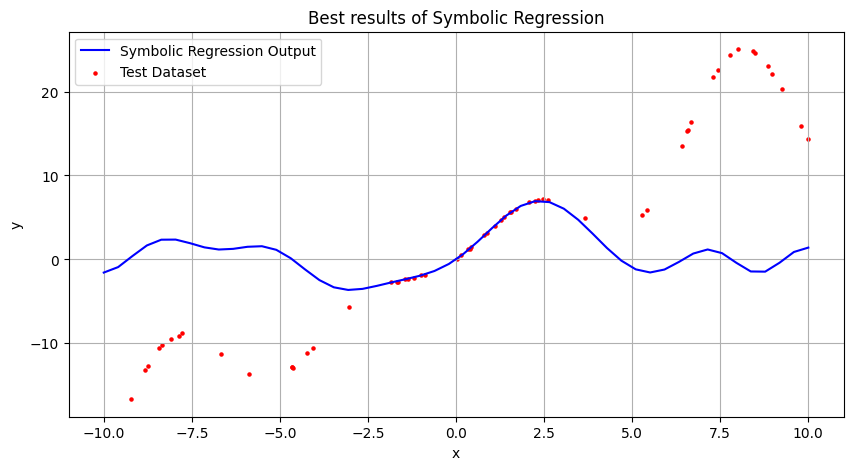

----------------------------------------------------

Number of layers: 4

Trial 1/5 started


Training...:   0%|          | 0/10000 [00:00<?, ?it/s]

Epoch 0, Loss: 13.117097854614258
Epoch 1000, Loss: 0.2451503425836563
Epoch 2000, Loss: 0.12524394690990448
Epoch 3000, Loss: 0.08205953985452652
Epoch 4000, Loss: 0.06729473173618317
Epoch 5000, Loss: 0.06251314282417297
Epoch 6000, Loss: 0.059856560081243515
Epoch 7000, Loss: 0.058339498937129974
Epoch 8000, Loss: 0.056557536125183105
Epoch 9000, Loss: 0.055094677954912186
Test Loss: 197.58021545410156
Expression: 16.3067479139324*(0.390979839605241*sin(0.553094449803903*x_1) + 0.513692375416435*sin(0.565540629128659*x_1))*(0.112671703100204*(0.390979839605241*sin(0.553094449803903*x_1) + 0.513692375416435*sin(0.565540629128659*x_1))*(0.0148177557578828*sin(0.553094449803903*x_1) + 0.0194684415475047*sin(0.565540629128659*x_1) + 0.969670223712997) - 0.0594897*sin(1.05251411714823*sin(0.553094449803903*x_1) + 1.38285513018549*sin(0.565540629128659*x_1) - 3.13850731463651) + 0.374833019176674)*(0.0148177557578828*sin(0.553094449803903*x_1) + 0.0194684415475047*sin(0.565540629128659*x_

Training...:   0%|          | 0/10000 [00:00<?, ?it/s]

Epoch 0, Loss: 12.892443656921387
Epoch 1000, Loss: 0.18899935483932495
Epoch 2000, Loss: 0.11584256589412689
Epoch 3000, Loss: 0.08988254517316818
Epoch 4000, Loss: 0.07773275673389435
Epoch 5000, Loss: 0.07377921044826508
Epoch 6000, Loss: 0.07102268189191818
Epoch 7000, Loss: 0.06889724731445312
Epoch 8000, Loss: 0.06598910689353943
Epoch 9000, Loss: 0.06537457555532455
Test Loss: 24462.609375
Expression: -4.21070098876953*(-2.91112303733826*(-0.261322156751501*(0.0346160538349638*x_1**2 + 0.335674)*sin(0.884821259374185*x_1) + 0.444371)*(0.549314536953927*(0.0346160538349638*x_1**2 + 0.335674)*sin(0.884821259374185*x_1) - 0.194431*sin(0.0460839045744192*x_1**2 + 2.20932893749828*sin(0.884821259374185*x_1) - 3.30375082627714) - 0.179285) - 2.28324130177498*(0.651402534351129*(0.0346160538349638*x_1**2 + 0.335674)*sin(0.884821259374185*x_1) + 0.457669636575836)*(0.612218292082289*(0.0346160538349638*x_1**2 + 0.335674)*sin(0.884821259374185*x_1) - 0.133603*sin(0.0460839045744192*x_1**

Training...:   0%|          | 0/10000 [00:00<?, ?it/s]

Epoch 0, Loss: 13.31899642944336
Epoch 1000, Loss: 0.2179306447505951
Epoch 2000, Loss: 0.12459857016801834
Epoch 3000, Loss: 0.09301137179136276
Epoch 4000, Loss: 0.07599040865898132
Epoch 5000, Loss: 0.06832006573677063
Epoch 6000, Loss: 0.06476934254169464
Epoch 7000, Loss: 0.060965076088905334
Epoch 8000, Loss: 0.057727277278900146
Epoch 9000, Loss: 0.056164707988500595
Test Loss: 170.2580108642578
Expression: -6.90006911754608*(3.34102988243103*(0.0158691047138115*sin(0.54003787083641*x_1) + 0.0498986333672569*sin(0.690751530059553*x_1) + 0.459118)*(0.0999581776854397*sin(0.54003787083641*x_1) + 0.314307363290873*sin(0.690751530059553*x_1) + 0.189522*sin(1.29593400901323*sin(0.690751530059553*x_1))) + 0.228452*sin(0.117037092283203*sin(0.54003787083641*x_1) + 0.368010109173114*sin(0.690751530059553*x_1) + 0.687116237149297*sin(1.29593400901323*sin(0.690751530059553*x_1))))*(-0.503246262669563*(0.0158691047138115*sin(0.54003787083641*x_1) + 0.0498986333672569*sin(0.690751530059553*

Training...:   0%|          | 0/10000 [00:00<?, ?it/s]

Epoch 0, Loss: 12.474919319152832
Epoch 1000, Loss: 0.2285720854997635
Epoch 2000, Loss: 0.13619960844516754
Epoch 3000, Loss: 0.09509441256523132
Epoch 4000, Loss: 0.07753420621156693
Epoch 5000, Loss: 0.06892547011375427
Epoch 6000, Loss: 0.061856046319007874
Epoch 7000, Loss: 0.055287912487983704
Epoch 8000, Loss: 0.05034259334206581
Epoch 9000, Loss: 0.05029093474149704
Test Loss: 176.43832397460938
Expression: -20.2042699303213*(-0.203484706580639*(-0.0368079942077348*sin(0.515297936547415*x_1) - 0.0112247937799501*sin(0.753760277781092*x_1) - 0.514741290469416)*(0.70784656160062*sin(0.515297936547415*x_1) + 0.215861577160975*sin(0.753760277781092*x_1) - 0.0856734*sin(2.23743494095757*sin(0.753760277781092*x_1) + 1.76580606875054) + 0.069634110742911) + 0.509751)*(-0.0368079942077348*sin(0.515297936547415*x_1) - 0.0112247937799501*sin(0.753760277781092*x_1) - 0.514741290469416)*(0.70784656160062*sin(0.515297936547415*x_1) + 0.215861577160975*sin(0.753760277781092*x_1) - 0.0856734*

Training...:   0%|          | 0/10000 [00:00<?, ?it/s]

Epoch 0, Loss: 13.357608795166016
Epoch 1000, Loss: 0.26535743474960327
Epoch 2000, Loss: 0.1521705836057663
Epoch 3000, Loss: 0.0965970829129219
Epoch 4000, Loss: 0.0781264454126358
Epoch 5000, Loss: 0.07000479847192764
Epoch 6000, Loss: 0.06591769307851791
Epoch 7000, Loss: 0.06392188370227814
Epoch 8000, Loss: 0.0632806196808815
Epoch 9000, Loss: 0.0630427747964859
Test Loss: 137.74969482421875
Expression: 3.48151981830597*(-0.314336318106373*(1 + 0.262886/(exp(0.662174*x_1) + 1))**2*(1 + 0.290823/(exp(0.662174*x_1) + 1))**2 + 1.7181584239006*(0.505084358155727*(0.548332 + 0.159468/(exp(0.662174*x_1) + 1))*(0.549726 + 0.144515/(exp(0.662174*x_1) + 1)) - 2.84796059131622*(0.0738573*sin(0.575472415078837*x_1) + 0.379995)*(-0.114483*sin(0.575472415078837*x_1) - 0.0619919*sin(0.834546406001886*x_1) - 0.379527))*(0.340128093957901*(0.548332 + 0.159468/(exp(0.662174*x_1) + 1))*(0.549726 + 0.144515/(exp(0.662174*x_1) + 1)) - 2.55836933851242*(0.0738573*sin(0.575472415078837*x_1) + 0.379995

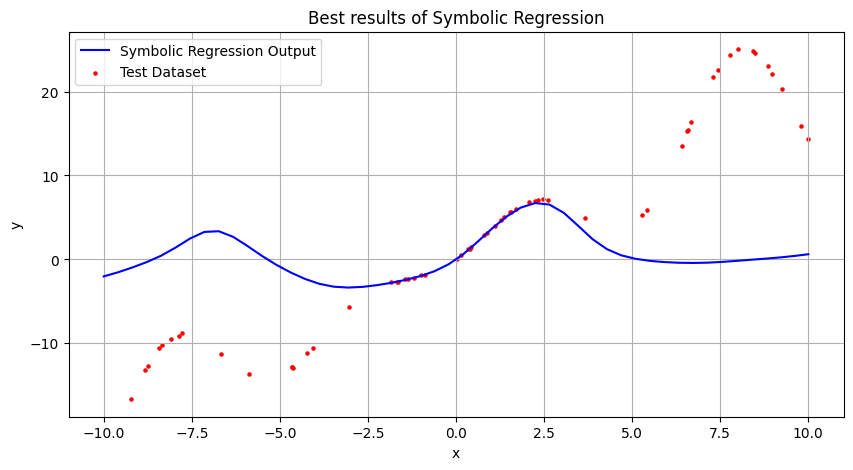

----------------------------------------------------


In [ ]:
# Now, change the activation functions and the number of layers (n_layers) to observe the effect on the outputs.

for n_layers in range(3, 5):
    print(f"\nNumber of layers: {n_layers}")

    best_expr = run(x_train, x_test, y_train, y_test, activation_funcs, n_layers, learning_rate, summary_step, epochs, trials)
    print(f"Best expression for Dataset 1 with n_layers={n_layers}: {best_expr}")
    plot_symbolic(x_test, y_test, best_expr.replace("exp", "np.exp").replace("sin", "np.sin"))

    print("----------------------------------------------------")

We were previously working with the first dataset. Now, evaluate the model on the second dataset and extract the corresponding expression.


Trial 1/5 started


Training...:   0%|          | 0/15000 [00:00<?, ?it/s]

Epoch 0, Loss: 67310.2578125
Epoch 1000, Loss: 79.4667739868164
Epoch 2000, Loss: 23.636516571044922
Epoch 3000, Loss: 5.956830024719238
Epoch 4000, Loss: 2.5176033973693848
Epoch 5000, Loss: 1.415568470954895
Epoch 6000, Loss: 1.0516343116760254
Epoch 7000, Loss: 0.9028464555740356
Epoch 8000, Loss: 0.8451794385910034
Epoch 9000, Loss: 8.552020072937012
Epoch 10000, Loss: 0.795759379863739
Epoch 11000, Loss: 0.7812917232513428
Epoch 12000, Loss: 0.7711016535758972
Epoch 13000, Loss: 0.759571373462677
Epoch 14000, Loss: 0.7506752610206604
Test Loss: 0.957165539264679
Expression: 0.00202656*(-0.463382*x_1 - x_2)**2 + 0.0694569503137291*(0.215637*x_1 + 0.108511*x_2)*(0.302562*x_1 + 0.258103*x_2) + 0.281874285411112*(0.000760448111206018*x_1 + 0.0240245573905831*x_2 + 0.0415555866692565*(-0.463382*x_1 - x_2)**2 + (0.165874*x_1 + 0.0593004*x_2)*(0.177281*x_1 + 0.0560143*x_2) + 0.905426467737781*(0.215637*x_1 + 0.108511*x_2)*(0.302562*x_1 + 0.258103*x_2) - 0.0833644351198657)**2 + 1.4591665

Training...:   0%|          | 0/15000 [00:00<?, ?it/s]

Epoch 0, Loss: 67323.0
Epoch 1000, Loss: 21.371505737304688
Epoch 2000, Loss: 7.425296783447266
Epoch 3000, Loss: 2.015960931777954
Epoch 4000, Loss: 1.4629607200622559
Epoch 5000, Loss: 1.2664612531661987
Epoch 6000, Loss: 1.5505235195159912
Epoch 7000, Loss: 1.0352139472961426
Epoch 8000, Loss: 2.2331485748291016
Epoch 9000, Loss: 0.8487102389335632
Epoch 10000, Loss: 0.7978772521018982
Epoch 11000, Loss: 0.7423378229141235
Epoch 12000, Loss: 1.669217586517334
Epoch 13000, Loss: 0.6645476818084717
Epoch 14000, Loss: 0.6418277621269226
Test Loss: 106.39189910888672
Expression: -0.0277348*(-x_1 + 0.977376*x_2)**2 - 1.60627497750501*(-0.275187*x_1 - 0.0804673*x_2)*(0.11694*x_1 + 0.260916*x_2) - 1.38215775055715*(-0.166327*x_1 - 0.146845*x_2)*(0.208147*x_1 + 0.320033*x_2) + 0.0119426*(x_1 + 0.641098*x_2)**2 + 1.63007891215214*(-0.00260072812136108*x_1 - 0.00608703075618509*x_2 + 0.0189895595488488*(-x_1 + 0.977376*x_2)**2 + (-0.275187*x_1 - 0.0804673*x_2)*(0.11694*x_1 + 0.260916*x_2) - 0

Training...:   0%|          | 0/15000 [00:00<?, ?it/s]

Epoch 0, Loss: 67367.53125
Epoch 1000, Loss: 31.892316818237305
Epoch 2000, Loss: 16.203258514404297
Epoch 3000, Loss: 7.500799655914307
Epoch 4000, Loss: 3.5330395698547363
Epoch 5000, Loss: 1.7909011840820312
Epoch 6000, Loss: 1.6102404594421387
Epoch 7000, Loss: 0.9704253673553467
Epoch 8000, Loss: 0.8583769798278809
Epoch 9000, Loss: 0.8824906349182129
Epoch 10000, Loss: 0.713293194770813
Epoch 11000, Loss: 0.6701177954673767
Epoch 12000, Loss: 0.641669511795044
Epoch 13000, Loss: 0.6225354075431824
Epoch 14000, Loss: 0.6072742938995361
Test Loss: 580.7545776367188
Expression: -0.0296404908659961*(-0.264267*x_1 - 0.1835*x_2)*(0.125326*x_1 + 0.172589*x_2) + 0.521509150848454*(0.136404*x_1 + 0.196146*x_2)*(0.429466*x_1 + 0.070449*x_2) - 0.985466782929557*(-0.0195877406697249*x_1 - 0.0112298518560785*x_2 - (-0.264267*x_1 - 0.1835*x_2)*(0.125326*x_1 + 0.172589*x_2) - 0.0035755574013286*(-0.2303*x_1 + x_2)**2 - 0.227679920704729*(0.136404*x_1 + 0.196146*x_2)*(0.429466*x_1 + 0.070449*x_2

Training...:   0%|          | 0/15000 [00:00<?, ?it/s]

Epoch 0, Loss: 67234.375
Epoch 1000, Loss: 37.75099563598633
Epoch 2000, Loss: 2.540759563446045
Epoch 3000, Loss: 1.6197022199630737
Epoch 4000, Loss: 35.78242874145508
Epoch 5000, Loss: 1.2145214080810547
Epoch 6000, Loss: 1.1355866193771362
Epoch 7000, Loss: 1.096024513244629
Epoch 8000, Loss: 0.9369125366210938
Epoch 9000, Loss: 0.8870271444320679
Epoch 10000, Loss: 0.8517791032791138
Epoch 11000, Loss: 0.8235004544258118
Epoch 12000, Loss: 1.033937931060791
Epoch 13000, Loss: 1.5971012115478516
Epoch 14000, Loss: 0.7751596570014954
Test Loss: 6233.12353515625
Expression: 0.00207574*(-x_1 - 0.702337*x_2)**2 + 0.544519601504623*(-0.484563*x_1 - 0.159476*x_2)*(-0.173088*x_1 - 0.25111*x_2) + 0.116894749161961*(-0.295416*x_1 - 0.133451*x_2)*(-0.244729*x_1 - 0.0932349*x_2) + 0.489924454174268*(-0.00660010723475496*x_1 - 0.0056313367331692*x_2 - 0.00138474677375872*(-x_1 - 0.702337*x_2)**2 - 0.00215585119753732*(-x_1 - 0.157423*x_2)**2 + 0.610042517701754*(-0.484563*x_1 - 0.159476*x_2)*(

Training...:   0%|          | 0/15000 [00:00<?, ?it/s]

Epoch 0, Loss: 67364.6328125
Epoch 1000, Loss: 58.70655059814453
Epoch 2000, Loss: 17.611339569091797
Epoch 3000, Loss: 5.626159191131592
Epoch 4000, Loss: 4.566108703613281
Epoch 5000, Loss: 3.866971969604492
Epoch 6000, Loss: 1.4913409948349
Epoch 7000, Loss: 41.52962875366211
Epoch 8000, Loss: 1.1185104846954346
Epoch 9000, Loss: 38.53596878051758
Epoch 10000, Loss: 0.9297101497650146
Epoch 11000, Loss: 14.385391235351562
Epoch 12000, Loss: 0.8525900840759277
Epoch 13000, Loss: 0.926021158695221
Epoch 14000, Loss: 0.7959752678871155
Test Loss: 6687.2421875
Expression: 0.018601*x_1 - 0.0211798*x_2 - 0.0800827963518262*(-0.425827*x_1 - 0.141116*x_2)*(0.173054*x_1 + 0.429376*x_2) + 0.000769082*(-0.379905*x_1 - x_2)**2 - 0.620607834880117*(-0.311418*x_1 - 0.107623*x_2)*(0.0638153*x_1 + 0.223616*x_2) - 2.43113532662392*(-0.00725071*x_1 + 0.109165*x_2 + 0.0168894*(-x_1 - 0.985583*x_2)**2 - 0.00164525*(-0.463943*x_1 + x_2)**2 - 3.54582250118256*(-0.425827*x_1 - 0.141116*x_2)*(0.173054*x_1 

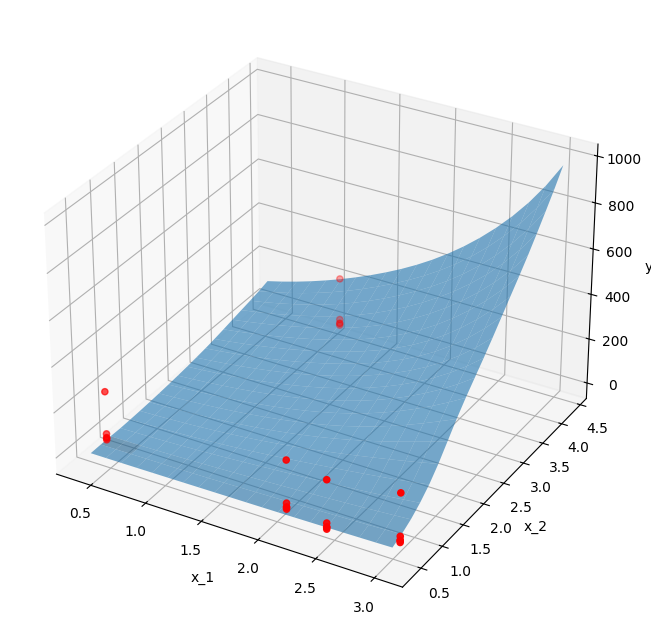

In [ ]:
# TODO: Find expression for second dataset.

# =================================== TODO ===================================
n_layers = 2
reg_weight = .01
learning_rate = .0009
summary_step = 1000
epochs = 15000 # or can use 10000 or 20000
trials = 5
var_names = ["x_1", "x_2"]

# Load and prepare Dataset 2
data = pd.read_csv('dataset.csv')
x_data = data[['x_1', 'x_2']].values
y_data = data['y'].values

# Split into train/test (90/10)
x_train2, x_test2, y_train2, y_test2 = train_test_split(
    x_data, y_data, test_size=0.1, random_state=42
)

# Convert to tensors
x_train2 = torch.tensor(x_train2, dtype=torch.float32)
y_train2 = torch.tensor(y_train2, dtype=torch.float32).view(-1, 1)
x_test2 = torch.tensor(x_test2, dtype=torch.float32)
y_test2 = torch.tensor(y_test2, dtype=torch.float32).view(-1, 1)

# Run and plot on second dataset
best_expr2 = run(x_train2, x_test2, y_train2, y_test2, activation_funcs,
                n_layers, learning_rate, summary_step, epochs, trials)

print(f"Best expression for Dataset 2: {best_expr2}")

# Create 3D plot for visualization
def plot_3d_symbolic(x_test, y_test, expr_str):
    fig = plt.figure(figsize=(12, 8))
    ax = fig.add_subplot(111, projection='3d')

    # Generate grid
    # x1_vals = np.linspace(-10, 10, 20)
    # x2_vals = np.linspace(-10, 10, 20)
    x1_vals = np.linspace(x_test[:,0].min(), x_test[:,0].max(), 20)
    x2_vals = np.linspace(x_test[:,1].min(), x_test[:,1].max(), 20)
    x1_grid, x2_grid = np.meshgrid(x1_vals, x2_vals)

    # Evaluate expression
    y_grid = eval(expr_str.replace("x_1", "x1_grid").replace("x_2", "x2_grid"),
                 {"x1_grid": x1_grid, "x2_grid": x2_grid, "np": np})

    ax.plot_surface(x1_grid, x2_grid, y_grid, alpha=0.6)
    ax.scatter(x_test[:,0], x_test[:,1], y_test, c='r', marker='o')
    ax.set_xlabel('x_1')
    ax.set_ylabel('x_2')
    ax.set_zlabel('y')
    plt.show()

plot_3d_symbolic(x_test2.numpy(), y_test2.numpy(),
                best_expr2.replace("exp", "np.exp").replace("sin", "np.sin"))
# ============================================================================


### Bonus

We know that in the first and second dataset, the expression is simple and contains only one or at most two terms. However, as you can see, the expressions here are quite long. Now, think about what adjustments you can make to simplify them and reduce their length.

Here we test different ideas and methods for simplifying expressions:

In [ ]:
# TODO
# Method 0. Post-process expressions using SymPy:

from sympy import simplify, trigsimp, factor, nsimplify

# Timeout handler for simplification
class TimeoutException(Exception):
    pass

def timeout_handler(signum, frame):
    raise TimeoutException("Simplification timed out")

print("First method:")
print("Original Expression for Dataset 1:", best_expr1)
# expr = simplify(best_expr1)
try:
    # Set up the timeout handler
    signal.signal(signal.SIGALRM, timeout_handler)
    signal.alarm(5)  # Set timeout to 5 seconds
    expr = sp.simplify(best_expr1)
    signal.alarm(0)  # Disable the alarm
except TimeoutException:
    print("Simplification timed out, using original expression")
    expr = best_expr1
except Exception as e:
    print(f"Simplification failed: {e}, using original expression")
    expr = best_expr1
finally:
    signal.alarm(0)  # Ensure alarm is disabled
expr = trigsimp(expr, deep=True)
simplified_expr = factor(expr)
print("Simplified Expression for Dataset 1:", simplified_expr)

print("---")

print("Original Expression for Dataset 2:", best_expr2)
# expr = simplify(best_expr2)
try:
    # Set up the timeout handler
    signal.signal(signal.SIGALRM, timeout_handler)
    signal.alarm(5)  # Set timeout to 5 seconds
    expr = sp.simplify(best_expr1)
    signal.alarm(0)  # Disable the alarm
except TimeoutException:
    print("Simplification timed out, using original expression")
    expr = best_expr1
except Exception as e:
    print(f"Simplification failed: {e}, using original expression")
    expr = best_expr1
finally:
    signal.alarm(0)  # Ensure alarm is disabled
expr = trigsimp(expr, deep=True)
simplified_expr = factor(expr)
print("Simplified Expression for Dataset 2:", simplified_expr)


# Symbolic Simplification Pipeline
def simplify_expression(expr_str, rounds=3):
    x = sp.symbols('x')
    expr = sp.sympify(expr_str.replace("np.", ""))

    # Iterative simplification
    for _ in range(rounds):
        # expr = simplify(expr)
        try:
            # Set up the timeout handler
            signal.signal(signal.SIGALRM, timeout_handler)
            signal.alarm(5)  # Set timeout to 5 seconds
            expr = sp.simplify(expr)
            signal.alarm(0)  # Disable the alarm
        except TimeoutException:
            print("Simplification timed out, using original expression")
            expr = expr
        except Exception as e:
            print(f"Simplification failed: {e}, using original expression")
            expr = expr
        finally:
            signal.alarm(0)  # Ensure alarm is disabled

        expr = nsimplify(expr, tolerance=0.01)

        # Constant folding
        for term in sp.preorder_traversal(expr):
            if term.is_Number:
                expr = expr.subs(term, round(float(term), 3))

    # Remove trivial terms (0*x, 1*x, etc.)
    expr = expr.replace(sp.Mul(0, x), 0)
    expr = expr.replace(sp.Mul(1, x), x)

    return str(expr)

simple_expr_with_pipeline = simplify_expression(best_expr1)
print("\n------------------------------\n")
print("Second method (with Pipeline):")
print("Original Expression for Dataset 1:", best_expr1)
print("Simplified Expression Dataset 1:", simple_expr_with_pipeline)

print("---")
simple_expr_with_pipeline = simplify_expression(best_expr2)
print("Original Expression for Dataset 2:", best_expr2)
print("Simplified Expression Dataset 2:", simple_expr_with_pipeline)

First method:
Original Expression for Dataset 1: -8.52455794811249*(0.395112*sin(0.677159171974709*x_1) + 0.540745*sin(0.764895588880067*x_1))*(-0.0265848898571275*x_1**2 - 0.22297*sin(0.764895588880067*x_1) - 0.51106)
Simplified Expression for Dataset 1: 2.35578835351548*(0.730680819979843*sin(0.677159171974709*x_1) + 1.0*sin(0.764895588880067*x_1))*(0.0520191168495431*x_1**2 + 0.436289281102023*sin(0.764895588880067*x_1) + 1.0)
---
Original Expression for Dataset 2: 0.00202656*(-0.463382*x_1 - x_2)**2 + 0.0694569503137291*(0.215637*x_1 + 0.108511*x_2)*(0.302562*x_1 + 0.258103*x_2) + 0.281874285411112*(0.000760448111206018*x_1 + 0.0240245573905831*x_2 + 0.0415555866692565*(-0.463382*x_1 - x_2)**2 + (0.165874*x_1 + 0.0593004*x_2)*(0.177281*x_1 + 0.0560143*x_2) + 0.905426467737781*(0.215637*x_1 + 0.108511*x_2)*(0.302562*x_1 + 0.258103*x_2) - 0.0833644351198657)**2 + 1.45916654721476*(0.00812457561329502*x_1 + 0.041756179919325*x_2 + 0.0282539982450634*(-0.463382*x_1 - x_2)**2 + 0.000867

Simplified expression for Dataset 1: x_1**2*sin(0.764895588880067*x_1) + sin(0.677159171974709*x_1)*sin(0.764895588880067*x_1) + sin(0.677159171974709*x_1) + sin(0.764895588880067*x_1)**2 + sin(0.764895588880067*x_1)


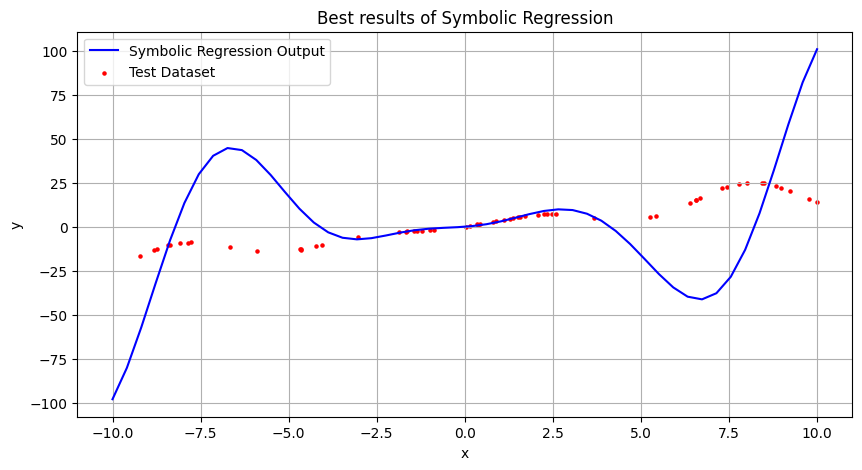

Simplified expression for Dataset 2: x_1 + x_2**2 - 8.51242056052506 + exp(-0.134373*x_1)*exp(-0.614996*x_2) + 1/(800617.0*exp(3.10016*x_1)*exp(-0.64451528813979*x_1**2)*exp(-11.2761*x_2)*exp(-5.95351930696704*x_2**2)*exp(-5.52687334516457*x_1*x_2)*exp(-6.10456*sin(0.582102500254212*x_1 - 0.256800194907461*x_2))*exp(-4.21054*sin(0.64720778513351*x_1 - 0.394550644446602*x_2)) + 1)


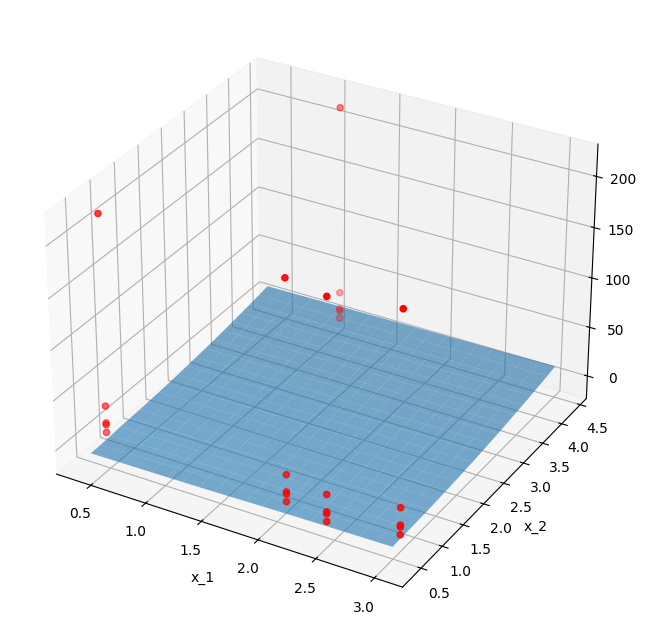

In [ ]:
# 1 Method: using simplify and thresholding

import sympy as sp
import signal

def simplify_expression(expr_str, threshold=0.1):
    expr = sp.sympify(expr_str)

    try:
        signal.signal(signal.SIGALRM, timeout_handler)
        signal.alarm(5)  # Set timeout to 5 seconds
        simplified = sp.expand(expr)
        signal.alarm(0)
    except TimeoutException:
        print("Expansion timed out, using original expression")
        simplified = expr
    except Exception as e:
        print(f"Expansion failed: {e}, using original expression")
        simplified = expr
    finally:
        signal.alarm(0)  # Ensure alarm is disabled

    # Get terms from the expanded expression
    terms = simplified.as_ordered_terms()

    # Extract and filter terms based on coefficient magnitude
    main_terms = []
    for term in terms:
        if term.is_Number:
            coeff = term
            base_term = term
        else:
            coeff, base_term = term.as_coeff_Mul() if term.is_Mul else (1, term)
        if isinstance(coeff, sp.Number):
            main_terms.append((abs(coeff), base_term))

    main_terms.sort(reverse=True, key=lambda x: x[0])

    # Select top terms above threshold, up to 5
    top_terms = [term for coeff, term in main_terms if coeff > threshold][:5]

    return str(sum(top_terms))

# Example usage (assuming best_expr1 and best_expr2 are defined)
simplified_expr_1 = simplify_expression(best_expr1)
print(f"Simplified expression for Dataset 1: {simplified_expr_1}")
plot_symbolic(x_test, y_test, simplified_expr_1.replace("exp", "np.exp").replace("sin", "np.sin"))

simplified_expr_2 = simplify_expression(best_expr2)
print(f"Simplified expression for Dataset 2: {simplified_expr_2}")
plot_3d_symbolic(x_test2.numpy(), y_test2.numpy(),
                simplified_expr_2.replace("exp", "np.exp").replace("sin", "np.sin"))


Trial 1/5 started


Training...:   0%|          | 0/10000 [00:00<?, ?it/s]

Epoch 0, Loss: 19.687450408935547
Epoch 1000, Loss: 1.5723282098770142
Epoch 2000, Loss: 0.9722321629524231
Epoch 3000, Loss: 0.8598828315734863
Epoch 4000, Loss: 0.8557777404785156
Epoch 5000, Loss: 0.8541851043701172
Epoch 6000, Loss: 0.85502028465271
Epoch 7000, Loss: 0.8541850447654724
Epoch 8000, Loss: 0.8540076017379761
Epoch 9000, Loss: 0.8389672040939331
Test Loss: 166.9986114501953
Expression: 7.41639871605017*(0.245001*sin(0.699597105187548*x_1) + 0.620617)*sin(0.699597105187548*x_1)

Trial 2/5 started


Training...:   0%|          | 0/10000 [00:00<?, ?it/s]

Epoch 0, Loss: 20.410785675048828
Epoch 1000, Loss: 1.1392066478729248
Epoch 2000, Loss: 0.9010937213897705
Epoch 3000, Loss: 0.8789286017417908
Epoch 4000, Loss: 0.855457603931427
Epoch 5000, Loss: 0.85432368516922
Epoch 6000, Loss: 0.8542007207870483
Epoch 7000, Loss: 0.8551832437515259
Epoch 8000, Loss: 0.8537442684173584
Epoch 9000, Loss: 0.8535515069961548
Test Loss: 170.55621337890625
Expression: -8.67679297924042*(-0.524354*sin(0.657148933759396*x_1) - 0.33535*sin(0.733351704527813*x_1))*(0.241381*sin(0.733351704527813*x_1) + 0.624691)

Trial 3/5 started


Training...:   0%|          | 0/10000 [00:00<?, ?it/s]

Epoch 0, Loss: 21.573564529418945
Epoch 1000, Loss: 1.1817071437835693
Epoch 2000, Loss: 0.9439566135406494
Epoch 3000, Loss: 0.9381428360939026
Epoch 4000, Loss: 0.9375901818275452
Epoch 5000, Loss: 0.9379618167877197
Epoch 6000, Loss: 0.9375975728034973
Epoch 7000, Loss: 0.9378723502159119
Epoch 8000, Loss: 0.9376633167266846
Epoch 9000, Loss: 0.9155869483947754
Test Loss: 9897.435546875
Expression: -8.01647305488586*(0.0425283876795007*x_1**2 + 0.722127*sin(0.968901270535568*x_1))*(-0.0852658704525283*x_1**2 - 0.151317*sin(0.968901270535568*x_1) - 0.4942)

Trial 4/5 started


Training...:   0%|          | 0/10000 [00:00<?, ?it/s]

Epoch 0, Loss: 21.22773551940918
Epoch 1000, Loss: 1.2747588157653809
Epoch 2000, Loss: 0.9273419976234436
Epoch 3000, Loss: 0.8782297968864441
Epoch 4000, Loss: 0.8562896251678467
Epoch 5000, Loss: 0.8546983003616333
Epoch 6000, Loss: 0.8549615740776062
Epoch 7000, Loss: 0.8547003865242004
Epoch 8000, Loss: 0.8546203970909119
Epoch 9000, Loss: 0.8541861176490784
Test Loss: 171.42514038085938
Expression: 8.68046760559082*(0.610412*sin(0.661690674118255*x_1) + 0.249659*sin(0.743203205533801*x_1))*(0.24178*sin(0.743203205533801*x_1) + 0.625597)

Trial 5/5 started


Training...:   0%|          | 0/10000 [00:00<?, ?it/s]

Epoch 0, Loss: 21.60135269165039
Epoch 1000, Loss: 1.1903841495513916
Epoch 2000, Loss: 1.0004661083221436
Epoch 3000, Loss: 0.9475904703140259
Epoch 4000, Loss: 0.9398334622383118
Epoch 5000, Loss: 0.9373619556427002
Epoch 6000, Loss: 0.9364346265792847
Epoch 7000, Loss: 0.9369087815284729
Epoch 8000, Loss: 0.9152072072029114
Epoch 9000, Loss: 0.9148126244544983
Test Loss: 10014.1083984375
Expression: 8.01683127880096*(0.0427302957453879*x_1**2 + 0.722127*sin(0.969045736621731*x_1))*(0.0853869952749253*x_1**2 + 0.15134*sin(0.969045736621731*x_1) + 0.494416)
Best expression for Dataset 1: 7.41639871605017*(0.245001*sin(0.699597105187548*x_1) + 0.620617)*sin(0.699597105187548*x_1)


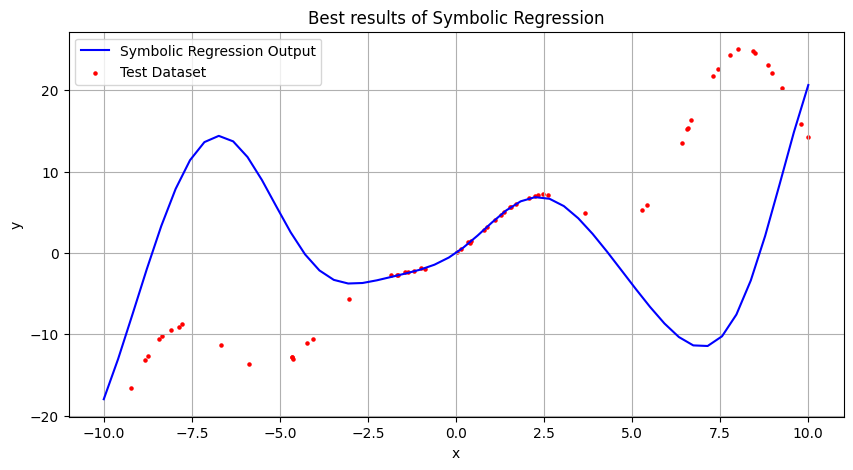


----------------------------------------------------


Trial 1/5 started


Training...:   0%|          | 0/15000 [00:00<?, ?it/s]

Epoch 0, Loss: 67324.0390625
Epoch 1000, Loss: 59.13768768310547
Epoch 2000, Loss: 31.99211883544922
Epoch 3000, Loss: 23.451744079589844
Epoch 4000, Loss: 18.9122257232666
Epoch 5000, Loss: 18.062795639038086
Epoch 6000, Loss: 18.91604232788086
Epoch 7000, Loss: 15.794549942016602
Epoch 8000, Loss: 13.06242561340332
Epoch 9000, Loss: 12.42354679107666
Epoch 10000, Loss: 11.976007461547852
Epoch 11000, Loss: 11.53874397277832
Epoch 12000, Loss: 11.341965675354004
Epoch 13000, Loss: 16.95693588256836
Epoch 14000, Loss: 10.38118839263916
Test Loss: 3639.48095703125
Expression: -0.0814520309859144*(-x_1 + 0.834114*x_2)**2*(0.527845*x_1 + x_2)**2 - 45.6370646645877*(0.00423214124860862*(-0.975688*x_1 + x_2)**2 - (-0.278514*x_1 + 0.232313*x_2)*(0.141154*x_1 + 0.267415*x_2) + 0.0449459596836978*sin(1.14481003052722*x_1 - 0.340060082490262*x_2) + 0.269692529752522)**2 + 3.52728545665741*(0.00467795*x_1 + 0.00778692*x_2 + 2.94731885194778*(-0.278514*x_1 + 0.232313*x_2)*(0.141154*x_1 + 0.267415

Training...:   0%|          | 0/15000 [00:00<?, ?it/s]

Epoch 0, Loss: 67318.2734375
Epoch 1000, Loss: 54.760013580322266
Epoch 2000, Loss: 28.08995819091797
Epoch 3000, Loss: 20.197179794311523
Epoch 4000, Loss: 16.21234130859375
Epoch 5000, Loss: 13.825861930847168
Epoch 6000, Loss: 13.120979309082031
Epoch 7000, Loss: 18.308837890625
Epoch 8000, Loss: 13.1104097366333
Epoch 9000, Loss: 11.353503227233887
Epoch 10000, Loss: 11.310723304748535
Epoch 11000, Loss: 10.580982208251953
Epoch 12000, Loss: 13.525611877441406
Epoch 13000, Loss: 9.734930038452148
Epoch 14000, Loss: 9.361034393310547
Test Loss: 7824.40966796875
Expression: 5.456923319122*(-(-0.429715*x_1 - 0.0301041*x_2)*(-0.013331*x_1 - 0.420889*x_2) - 0.625988597892681*(0.0329889*x_1 + 0.341637*x_2)*(0.369733*x_1 + 0.0780208*x_2))**2 + 5.14513692072942*(0.729793303491353*(-0.429715*x_1 - 0.0301041*x_2)*(-0.013331*x_1 - 0.420889*x_2) + (0.0329889*x_1 + 0.341637*x_2)*(0.369733*x_1 + 0.0780208*x_2))**2 + 4.13509964942932*(-0.0255894*x_1 - 0.0176644*x_2 - 0.00080041*(-0.946065*x_1 - x

Training...:   0%|          | 0/15000 [00:00<?, ?it/s]

Epoch 0, Loss: 67339.21875
Epoch 1000, Loss: 30.620330810546875
Epoch 2000, Loss: 23.280773162841797
Epoch 3000, Loss: 21.32291030883789
Epoch 4000, Loss: 19.828155517578125
Epoch 5000, Loss: 18.28374481201172
Epoch 6000, Loss: 16.917449951171875
Epoch 7000, Loss: 16.18431854248047
Epoch 8000, Loss: 15.079469680786133
Epoch 9000, Loss: 22.0477352142334
Epoch 10000, Loss: 14.263561248779297
Epoch 11000, Loss: 15.148470878601074
Epoch 12000, Loss: 13.693799018859863
Epoch 13000, Loss: 13.276400566101074
Epoch 14000, Loss: 12.9580078125
Test Loss: 625.8690795898438
Expression: 0.000989980976926363*(-x_1 - 0.519363*x_2)**2*(x_1 + 0.886916*x_2)**2 + 0.780076034108561*(0.412737006218211*(-0.314736*x_1 - 0.246284*x_2)*(0.338401*x_1 - 0.0264859*x_2) + (-0.300719*x_1 - 0.156182*x_2)*(0.281326*x_1 + 0.249512*x_2) - 0.00434477017918282*(x_1 + 0.871702*x_2)**2)**2 + 2.7500331401825*(-4.05758649110794*(-0.314736*x_1 - 0.246284*x_2)*(0.338401*x_1 - 0.0264859*x_2) - 3.50052744150162*(-0.300719*x_1 - 

Training...:   0%|          | 0/15000 [00:00<?, ?it/s]

Epoch 0, Loss: 67329.8359375
Epoch 1000, Loss: 251.2816162109375
Epoch 2000, Loss: 56.568111419677734
Epoch 3000, Loss: 28.12129783630371
Epoch 4000, Loss: 22.05706787109375
Epoch 5000, Loss: 18.961368560791016
Epoch 6000, Loss: 18.51639175415039
Epoch 7000, Loss: 43.950721740722656
Epoch 8000, Loss: 15.173116683959961
Epoch 9000, Loss: 35.05162811279297
Epoch 10000, Loss: 13.749894142150879
Epoch 11000, Loss: 13.092277526855469
Epoch 12000, Loss: 12.649209022521973
Epoch 13000, Loss: 11.95860481262207
Epoch 14000, Loss: 11.444425582885742
Test Loss: 2743.387939453125
Expression: 1.91101156149329*(0.707929875448926*(-0.303245*x_1 - 0.16737*x_2)*(-0.0471586*x_1 - 0.239216*x_2) + (0.315808*x_1 + 0.145195*x_2)*(0.359338*x_1 + 0.198653*x_2))**2 + 3.87776559289752*(-0.00128103593663183*(-x_1 - 0.687528*x_2)**2 - (-0.303245*x_1 - 0.16737*x_2)*(-0.0471586*x_1 - 0.239216*x_2) - 0.493620619487093*(0.315808*x_1 + 0.145195*x_2)*(0.359338*x_1 + 0.198653*x_2) - 0.000759673591378079*(x_1 + 0.710432*

Training...:   0%|          | 0/15000 [00:00<?, ?it/s]

Epoch 0, Loss: 67301.7578125
Epoch 1000, Loss: 148.70779418945312
Epoch 2000, Loss: 54.06571960449219
Epoch 3000, Loss: 28.760812759399414
Epoch 4000, Loss: 22.83167839050293
Epoch 5000, Loss: 19.959583282470703
Epoch 6000, Loss: 20.223371505737305
Epoch 7000, Loss: 26.736177444458008
Epoch 8000, Loss: 24.66091537475586
Epoch 9000, Loss: 17.11783218383789
Epoch 10000, Loss: 16.093233108520508
Epoch 11000, Loss: 15.543599128723145
Epoch 12000, Loss: 21.682207107543945
Epoch 13000, Loss: 14.826306343078613
Epoch 14000, Loss: 13.56209659576416
Test Loss: 19103.978515625
Expression: 1.74641229993868*(-0.00174103036472734*(-x_1 - 0.986728*x_2)**2 - 0.00540301512641442*(-x_1 - 0.771972*x_2)**2 + 0.613971401801395*(-0.21442*x_1 - 0.140015*x_2)*(0.266405*x_1 + 0.399279*x_2) + (0.0471499*x_1 - 0.344071*x_2)*(0.51432*x_1 + 0.0924917*x_2) - 0.0196440982568054*exp(0.351335*x_1 + 0.259647*x_2) + 0.0196440982568054)**2 + 2.23567009585698*(0.00150022638032751*(-x_1 - 0.902487*x_2)**2 + 0.004492078786

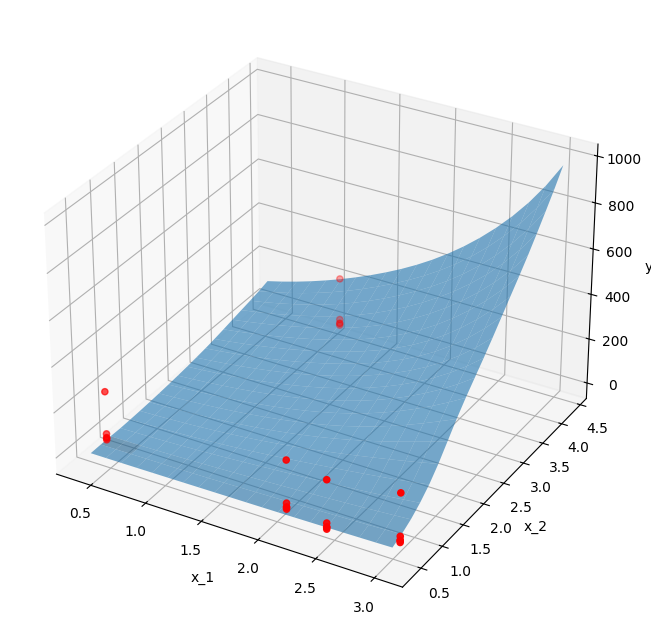

In [ ]:
# 2. Increase L1 Regularization weight : Use higher reg_weight to encourage sparsity.
reg_weight = .3 # .3 instead of .01

epochs = 10000
best_expr_1 = run(x_train, x_test, y_train, y_test, activation_funcs, n_layers, learning_rate, summary_step, epochs, trials)
print(f"Best expression for Dataset 1: {best_expr_1}")
plot_symbolic(x_test, y_test, best_expr.replace("exp", "np.exp").replace("sin", "np.sin"))

print("\n----------------------------------------------------\n")

epochs = 15000
best_expr_2 = run(x_train2, x_test2, y_train2, y_test2, activation_funcs, n_layers, learning_rate, summary_step, epochs, trials)
print(f"Best expression for Dataset 2: {best_expr_2}")
plot_3d_symbolic(x_test2.numpy(), y_test2.numpy(),
                best_expr2.replace("exp", "np.exp").replace("sin", "np.sin"))


Trial 1/5 started


Training...:   0%|          | 0/5000 [00:00<?, ?it/s]

Epoch 0, Loss: 16.453710556030273
Epoch 1000, Loss: 0.5541492104530334
Epoch 2000, Loss: 0.3697822391986847
Epoch 3000, Loss: 0.3419968783855438
Epoch 4000, Loss: 0.3301040530204773
Test Loss: 379.2778625488281
Expression: 7.72117912769318*(0.0375002417781937*x_1**2 + 0.283642959934247 - 0.0659619990406159*exp(-0.0650478*x_1) + 0.0457089/(1 + exp(-1.2615*x_1)))*(0.0138721117626592*x_1**2 + 0.194750833902346 - 0.113457157141499*exp(-0.0650478*x_1) - 0.0812936767608465*exp(-0.0594896*x_1) + 0.328339/(1 + exp(-1.2615*x_1)))

Trial 2/5 started


Training...:   0%|          | 0/5000 [00:00<?, ?it/s]

Epoch 0, Loss: 14.917089462280273
Epoch 1000, Loss: 0.5065072774887085
Epoch 2000, Loss: 0.3617723882198334
Epoch 3000, Loss: 0.33530861139297485
Epoch 4000, Loss: 0.33038529753685
Test Loss: 209.9185333251953
Expression: 7.83617317676544*(-0.0237464482200497*x_1**2 - 0.0368069282455706*exp(0.0586299*x_1) - 0.129451004536603 - 0.150593/(1 + exp(-1.20276*x_1)))*(-0.120479908719696*exp(0.0552064*x_1) - 0.102708142004775*exp(0.0586299*x_1) + 0.223188050724471 - 0.319372/(1 + exp(-1.20276*x_1)))

Trial 3/5 started


Training...:   0%|          | 0/5000 [00:00<?, ?it/s]

Epoch 0, Loss: 14.714984893798828
Epoch 1000, Loss: 0.5478699803352356
Epoch 2000, Loss: 0.36202535033226013
Epoch 3000, Loss: 0.332494854927063
Epoch 4000, Loss: 0.32852306962013245
Test Loss: 208.61351013183594
Expression: -8.23357880115509*(-0.0602598917786596 + 0.0602598917786596*exp(-0.0503661*x_1) + 0.414895/(exp(1.17357*x_1) + 1) - 0.342276/(1 + exp(-1.19278*x_1)))*(0.02220718266366*x_1**2 + 0.352112 - 0.105001/(exp(1.17357*x_1) + 1) + 0.136604/(1 + exp(-1.19278*x_1)))

Trial 4/5 started


Training...:   0%|          | 0/5000 [00:00<?, ?it/s]

Epoch 0, Loss: 13.916234016418457
Epoch 1000, Loss: 0.5871049165725708
Epoch 2000, Loss: 0.383799284696579
Epoch 3000, Loss: 0.34775182604789734
Epoch 4000, Loss: 0.32873061299324036
Test Loss: 210.0532684326172
Expression: -8.30387651920319*(-0.113193974442257*exp(0.0562079*x_1) + 0.113193974442257 + 0.325414/(exp(1.20812*x_1) + 1) - 0.285339/(1 + exp(-1.14216*x_1)))*(0.0227090960817122*x_1**2 + 0.0124887084193027*exp(0.0562079*x_1) + 0.326505049543878 - 0.148968/(exp(1.20812*x_1) + 1) + 0.0587309/(1 + exp(-1.14216*x_1)))

Trial 5/5 started


Training...:   0%|          | 0/5000 [00:00<?, ?it/s]

Epoch 0, Loss: 15.941946983337402
Epoch 1000, Loss: 0.5722684860229492
Epoch 2000, Loss: 0.36380064487457275
Epoch 3000, Loss: 0.3379683196544647
Epoch 4000, Loss: 0.33038201928138733
Test Loss: 878.9922485351562
Expression: -7.63856053352356*(-0.0442863147529723*x_1**2 - 0.0480205148424924*exp(0.0668171*x_1) - 0.296295133236426 + 0.0809985/(exp(1.33792*x_1) + 1))*(0.0216523688791545*x_1**2 + 0.105502571063959*exp(0.0668171*x_1) - 0.0481867184721184 - 0.0573158525918409*exp(-0.0574545*x_1) - 0.39062/(exp(1.33792*x_1) + 1))
Best expression for Dataset 1: -8.23357880115509*(-0.0602598917786596 + 0.0602598917786596*exp(-0.0503661*x_1) + 0.414895/(exp(1.17357*x_1) + 1) - 0.342276/(1 + exp(-1.19278*x_1)))*(0.02220718266366*x_1**2 + 0.352112 - 0.105001/(exp(1.17357*x_1) + 1) + 0.136604/(1 + exp(-1.19278*x_1)))


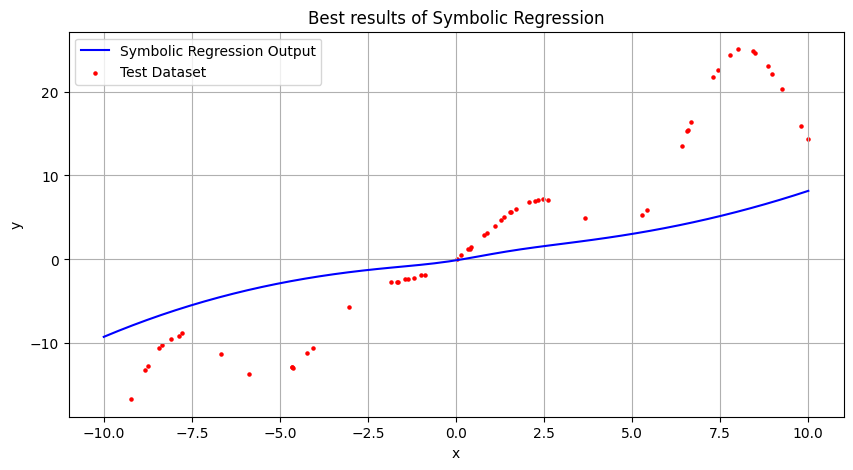


----------------------------------------------------


Trial 1/5 started


Training...:   0%|          | 0/5000 [00:00<?, ?it/s]

Epoch 0, Loss: 67268.625
Epoch 1000, Loss: 28.868013381958008
Epoch 2000, Loss: 15.960380554199219
Epoch 3000, Loss: 9.94989013671875
Epoch 4000, Loss: 7.393660545349121
Test Loss: 3025.211181640625
Expression: -0.257660054351743*(-0.267879*x_1 - 0.135406*x_2)*(-0.106221*x_1 - 0.197614*x_2) - 0.044255912187986*(-0.124271*x_1 - 0.333668*x_2)*(0.296702*x_1 + 0.0521517*x_2) + 0.423608878120111*((-0.267879*x_1 - 0.135406*x_2)*(-0.106221*x_1 - 0.197614*x_2) - 0.0767238098209203*exp(0.0152948*x_1 - 0.0518215*x_2) - 0.0287984006989303*exp(0.0223752*x_1 - 0.0640966*x_2) + 0.105522210519851 - 0.29096952233699/(exp(-0.237685*x_1 - 1.75854*x_2) + 1))**2 + 3.25786477295079*(-0.00141426068136417*x_1 + 0.0174418887943359*x_2 + 0.00297164087134676*(-x_1 - 0.875938*x_2)**2 + 0.778477492854294*(-0.267879*x_1 - 0.135406*x_2)*(-0.106221*x_1 - 0.197614*x_2) - (-0.124271*x_1 - 0.333668*x_2)*(0.296702*x_1 + 0.0521517*x_2) + 0.00163314799804922*(0.822307*x_1 + x_2)**2 - 0.0904065294054869*exp(0.0152948*x_1 -

Training...:   0%|          | 0/5000 [00:00<?, ?it/s]

Epoch 0, Loss: 67263.078125
Epoch 1000, Loss: 27.24593734741211
Epoch 2000, Loss: 7.65346622467041
Epoch 3000, Loss: 5.903721332550049
Epoch 4000, Loss: 4.952116012573242
Test Loss: 178.0725555419922
Expression: 0.0550372087052367*(-0.518237*x_1 + 0.0481665*x_2)*(0.0214967*x_1 - 0.381434*x_2) - 0.334063888639969*(-0.229201*x_1 - 0.212944*x_2)*(0.220456*x_1 + 0.216107*x_2) - 0.148913501951028*((-0.518237*x_1 + 0.0481665*x_2)*(0.0214967*x_1 - 0.381434*x_2) + 0.679319471950584*(-0.229201*x_1 - 0.212944*x_2)*(0.220456*x_1 + 0.216107*x_2))**2 + 0.38720304541218*(-0.0125886919432802*x_1 - 0.00339652508790308*x_2 + 0.304054631950998*(-0.518237*x_1 + 0.0481665*x_2)*(0.0214967*x_1 - 0.381434*x_2) + 0.000934396534995645*(-0.269161*x_1 - x_2)**2 + (-0.229201*x_1 - 0.212944*x_2)*(0.220456*x_1 + 0.216107*x_2) - 0.087580137079406*exp(0.0656871*x_1 - 0.0280618*x_2) - 0.0595972522764416*sin(5.42645703714546*x_1 - 1.44096812871219*x_2) - 0.00486007848772684 - 0.0458634501473314*exp(-0.0857708*x_1))**2 

Training...:   0%|          | 0/5000 [00:00<?, ?it/s]

Epoch 0, Loss: 67335.9140625
Epoch 1000, Loss: 30.453411102294922
Epoch 2000, Loss: 8.45161247253418
Epoch 3000, Loss: 5.496084690093994
Epoch 4000, Loss: 4.77407169342041
Test Loss: 386.7390441894531
Expression: -0.0369253927130919*(-x_1 + 0.0546308*x_2)**2*(0.072708*x_1 - x_2)**2 + 0.747825979620695*(-0.585196*x_1 + 0.0319697*x_2)*(0.0336024*x_1 - 0.462155*x_2) - 0.404008769328461*(-(-0.585196*x_1 + 0.0319697*x_2)*(0.0336024*x_1 - 0.462155*x_2) + 0.653256609829354*(-0.0645457*x_1 - 0.19793*x_2)*(0.282937*x_1 + 0.15829*x_2) - 0.0139758456417819*exp(-0.187546*x_1 - 0.149548*x_2) - 0.000897729698201079 - 0.0248522925603181*exp(-0.145743*x_1) - 0.0198600648927605/(exp(-2.75261*x_1 - 0.303861*x_2) + 1))**2 + 3.55296107551585*(0.000970398040254504*x_1 + 0.00528943971114924*x_2 + 0.000320900545608337*(-x_1 - 0.891221*x_2)**2 + (-0.585196*x_1 + 0.0319697*x_2)*(0.0336024*x_1 - 0.462155*x_2) - 0.00405685620488492*(-0.526894*x_1 - x_2)**2 - 0.282376469983425*(-0.0645457*x_1 - 0.19793*x_2)*(0.28

Training...:   0%|          | 0/5000 [00:00<?, ?it/s]

Epoch 0, Loss: 67365.15625
Epoch 1000, Loss: 152.65115356445312
Epoch 2000, Loss: 9.593862533569336
Epoch 3000, Loss: 7.558213233947754
Epoch 4000, Loss: 6.494541168212891
Test Loss: 11549.53125
Expression: 2.2912127463253e-5*(-x_1 - 0.412309*x_2)**2*(-0.723449*x_1 - x_2)**2 + 0.5875665617355*(-0.388865*x_1 - 0.160333*x_2)*(-0.195535*x_1 - 0.270281*x_2) + 0.00058363*(x_1 + 0.97395*x_2)**2 - 0.8956591773203*(-(-0.388865*x_1 - 0.160333*x_2)*(-0.195535*x_1 - 0.270281*x_2) + 0.544875963860286*(0.243451*x_1 + 0.233633*x_2)*(0.335221*x_1 + 0.110456*x_2) - 0.00527201794529714*(x_1 + 0.97395*x_2)**2 - 0.0319570579847111*sin(3.61375238950943*x_1 + 2.83862358333479*x_2) - 0.0608410573783424)**2 + 0.0910859539577207*(0.00211294628242954*x_1 + 0.0121492223065187*x_2 + (-0.388865*x_1 - 0.160333*x_2)*(-0.195535*x_1 - 0.270281*x_2) + 0.416316761705976*(0.243451*x_1 + 0.233633*x_2)*(0.335221*x_1 + 0.110456*x_2) + 0.0211395329244811*(x_1 + 0.629872*x_2)**2 + 0.0460231614795157*(x_1 + 0.97395*x_2)**2 - 

Training...:   0%|          | 0/5000 [00:00<?, ?it/s]

Epoch 0, Loss: 67234.1875
Epoch 1000, Loss: 85.86190795898438
Epoch 2000, Loss: 25.65558433532715
Epoch 3000, Loss: 14.048585891723633
Epoch 4000, Loss: 10.195653915405273
Test Loss: 17281.8984375
Expression: -0.0015197*x_1 + 0.0454306*x_2 - 0.917863442309774*(-0.483324*x_1 - 0.198317*x_2)*(0.191812*x_1 + 0.418022*x_2) - 0.520442159308963*(-0.089241*x_1 - 0.131764*x_2)*(0.256465*x_1 + 0.391659*x_2) + 0.156318385031612*(-(-0.089241*x_1 - 0.131764*x_2)*(0.256465*x_1 + 0.391659*x_2) + 0.0777384773854939*exp(-0.0415939*x_1 - 0.0838099*x_2) - 0.0777384773854939 - 0.0394664968122872/(exp(1.52848*x_1 - 0.483716*x_2) + 1))**2 - 0.344305739187037*(0.00470859029057052*x_1 - 0.1407608484171*x_2 + (-0.483324*x_1 - 0.198317*x_2)*(0.191812*x_1 + 0.418022*x_2) + 0.148843463047683*(-0.089241*x_1 - 0.131764*x_2)*(0.256465*x_1 + 0.391659*x_2) - 0.00733284501297743*exp(-0.0415939*x_1 - 0.0838099*x_2) + 0.00733284501297743)**2 - 3.84828716516495*(0.0061687*x_1 - 0.2705*x_2 + 0.0132896*(-x_1 - 0.959949*x_2

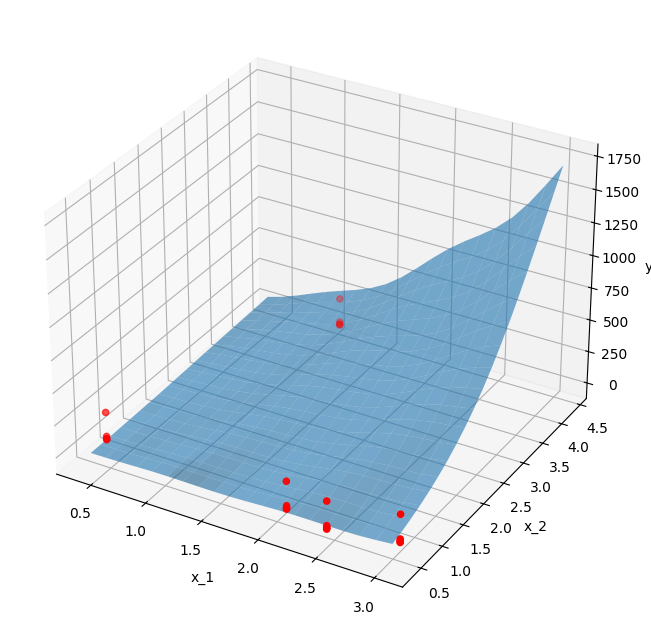

In [ ]:
# 3. Limit the number of activation functions (reduce activation functions): Use only essential functions (e.g., remove sigmoid if not needed).
# we can also use a threshold to prune small weights before extracting the expression

reg_weight = .1  # Increased regularization from .01 to .1

simple_activation_funcs = [
    *[Constant()] * 4,
    *[Square()] * 4,
    *[Sin()] * 4,
    *[Exp()] * 2,
    *[Sigmoid()] * 2,
    *[Product()] * 2,
]

best_expr_simple_1 = run(x_train, x_test, y_train, y_test, simple_activation_funcs,
                      n_layers=2, learning_rate=0.001, summary_step=1000, epochs=5000, trials=5)
print(f"Best expression for Dataset 1: {best_expr_simple_1}")
plot_symbolic(x_test, y_test, best_expr_simple_1.replace("exp", "np.exp").replace("sin", "np.sin"))

print("\n----------------------------------------------------\n")
best_expr_simple_2 = run(x_train2, x_test2, y_train2, y_test2, simple_activation_funcs,
                      n_layers=2, learning_rate=0.001, summary_step=1000, epochs=5000, trials=5)
print(f"Best expression for Dataset 2: {best_expr_simple_2}")
plot_3d_symbolic(x_test2.numpy(), y_test2.numpy(),
                 best_expr_simple_2.replace("exp", "np.exp").replace("sin", "np.sin"))

Epoch 0, Loss: 24.772632598876953
Epoch 500, Loss: 6.109258651733398
Epoch 1000, Loss: 5.713894844055176
Epoch 1500, Loss: 5.527871608734131
Epoch 2000, Loss: 5.462358474731445
Epoch 2500, Loss: 5.416058540344238
Epoch 3000, Loss: 5.408188343048096
Epoch 3500, Loss: 5.410158157348633
Epoch 4000, Loss: 5.4127960205078125
Epoch 4500, Loss: 5.4105706214904785
Test Loss: 135.00169372558594
Pruned Expression for Dataset 1: -7.35599517822266*(-0.034711*x_1 - 0.359241 - 0.410209/(1 + exp(-0.872438*x_1)))*(0.614258*x_1 + 0.0342413 + 0.0102423/(1 + exp(-0.872438*x_1)))


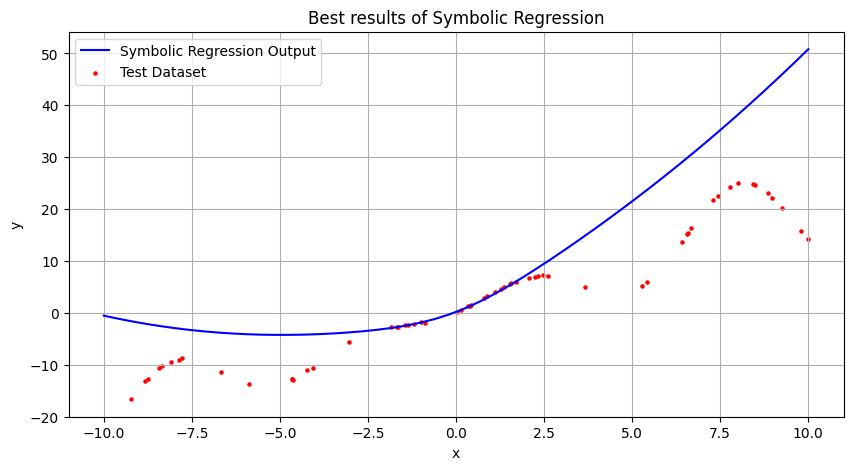

In [ ]:
# 4. Pruning and Regularization Techniques
# Enhanced L1/L0 Regularization

device = 'cuda' if torch.cuda.is_available() else 'cpu'

def train_with_sparsity(x_train, y_train, activation_funcs, n_layers, l1_weight=0.1, l0_approx_weight=0.05):
    net = SymbolicNet(n_layers, funcs=activation_funcs).to(device)
    x_train, y_train = x_train.to(device), y_train.to(device)
    optimizer = optim.Adam(net.parameters(), lr=0.001)

    for epoch in range(5000):
        optimizer.zero_grad()
        outputs = net(x_train)

        # Base MSE loss
        loss = F.mse_loss(outputs, y_train)

        # L1 regularization
        l1_reg = sum(p.abs().sum() for p in net.parameters())
        loss += l1_weight * l1_reg

        # L0 approximation (using hard concrete)
        l0_reg = sum((torch.sigmoid(p - 2.5)).sum() for p in net.parameters())
        loss += l0_approx_weight * l0_reg

        loss.backward()
        optimizer.step()

        # Post-training thresholding
        if epoch % 100 == 0:
            with torch.no_grad():
                for p in net.parameters():
                    p[p.abs() < 0.1] = 0  # Prune small weights

        if epoch % 500 == 0:
            print(f"Epoch {epoch}, Loss: {loss.item()}")

    test_loss = test(net, x_test, y_test)
    print(f"Test Loss: {test_loss}")

    return net

pruned_net = train_with_sparsity(x_train, y_train, activation_funcs, n_layers=2, l1_weight=0.25, l0_approx_weight=0.15)
pruned_expr = find_expression(pruned_net, x_train.shape[1])
print("Pruned Expression for Dataset 1:", pruned_expr)
plot_symbolic(x_test, y_test, str(pruned_expr).replace("exp", "np.exp").replace("sin", "np.sin"))

# print("\n------------------------------------\n")
# pruned_net = train_with_sparsity(x_train2, y_train2, activation_funcs, n_layers=2, l1_weight=0.25, l0_approx_weight=0.15)
# pruned_expr = find_expression(pruned_net, x_train2.shape[1])
# print("Pruned Expression for Dataset 2:", pruned_expr)
# plot_3d_symbolic(x_test2.numpy(), y_test2.numpy(),
#                  str(pruned_expr).replace("exp", "np.exp").replace("sin", "np.sin"))

In [ ]:
!pip install deap -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.4/135.4 kB 10.4 MB/s eta 0:00:00


In [ ]:
# 5. Genetic Algorithm for Expression Simplification
from deap import algorithms, base, creator, tools

def genetic_simplification(expr_str, x_data, y_data, population_size=50, generations=20):
    x = sp.symbols('x')
    original_expr = sp.sympify(expr_str.replace("np.", ""))

    # Fitness function
    def evaluate(individual):
        try:
            expr = sp.sympify("".join(individual))
            y_pred = [float(expr.subs(x, val)) for val in x_data]
            mse = np.mean((y_pred - y_data)**2)
            complexity = len(str(expr))  # Simpler expressions favored
            return mse + 0.1*complexity,
        except:
            return float('inf'),

    # Genetic algorithm setup
    creator.create("FitnessMin", base.Fitness, weights=(-1.0,))
    creator.create("Individual", list, fitness=creator.FitnessMin)

    toolbox = base.Toolbox()
    toolbox.register("expr", lambda: random.choice(['x', 'sin(x)', 'cos(x)', '+', '-', '*']))
    toolbox.register("individual", tools.initRepeat, creator.Individual, toolbox.expr, n=10)
    toolbox.register("population", tools.initRepeat, list, toolbox.individual)

    toolbox.register("mate", tools.cxOnePoint)
    toolbox.register("mutate", tools.mutShuffleIndexes, indpb=0.1)
    toolbox.register("select", tools.selTournament, tournsize=3)
    toolbox.register("evaluate", evaluate)

    # Evolution
    pop = toolbox.population(n=population_size)
    algorithms.eaSimple(pop, toolbox, cxpb=0.5, mutpb=0.2, ngen=generations, verbose=False)

    return "".join(tools.selBest(pop, k=1)[0])

net = train(x_train, y_train, activation_funcs, x_train.shape[1], n_layers, learning_rate, summary_step, 10000)
x_dim = x_train.shape[1]
# expr = find_expression(net, x_dim)
raw_expr = str(find_expression(net, x_dim))

simplified = simplify_expression(raw_expr)

# raw_expr = simplify(raw_expr)
# raw_expr = trigsimp(raw_expr, deep=True)
# simplified = factor(raw_expr)

simplified = raw_expr

optimized = genetic_simplification(simplified, x_test.numpy(), y_test.numpy())
print("Original Expression for Dataset 1:", raw_expr)
print("Optimized Expression for Dataset 1:", optimized)

print("\n------------------------------------\n")

net = train(x_train2, y_train2, activation_funcs, x_train2.shape[1], n_layers, learning_rate, summary_step, 15000)
x_dim = x_train2.shape[1]
raw_expr = str(find_expression(net, x_dim))

simplified = simplify_expression(raw_expr)

simplified = raw_expr

optimized = genetic_simplification(simplified, x_test2.numpy(), y_test2.numpy())
print("Original Expression for Dataset 2:", raw_expr)
print("Optimized Expression for Dataset 2:", optimized)

Training...:   0%|          | 0/10000 [00:00<?, ?it/s]

Epoch 0, Loss: 14.840954780578613
Epoch 1000, Loss: 0.6830316781997681
Epoch 2000, Loss: 0.39674708247184753
Epoch 3000, Loss: 0.3483005464076996
Epoch 4000, Loss: 0.31628769636154175
Epoch 5000, Loss: 0.3145012855529785
Epoch 6000, Loss: 0.3137478828430176
Epoch 7000, Loss: 0.3140111267566681
Epoch 8000, Loss: 0.31382909417152405
Epoch 9000, Loss: 0.31378334760665894
Original Expression for Dataset 1: 8.35493803024292*(0.0284253058903444*x_1**2 + 0.765709*sin(0.874750109996103*x_1))*(0.054236466585933*x_1**2 + 0.186173*sin(0.874750109996103*x_1) + 0.516397)
Optimized Expression for Dataset 1: -sin(x)xx*sin(x)+-cos(x)-

------------------------------------



Training...:   0%|          | 0/15000 [00:00<?, ?it/s]

Epoch 0, Loss: 67244.9453125
Epoch 1000, Loss: 32.15316390991211
Epoch 2000, Loss: 12.779044151306152
Epoch 3000, Loss: 9.438982009887695
Epoch 4000, Loss: 7.750495433807373
Epoch 5000, Loss: 6.767453670501709
Epoch 6000, Loss: 6.178714275360107
Epoch 7000, Loss: 5.788794994354248
Epoch 8000, Loss: 5.616510391235352
Epoch 9000, Loss: 5.365776062011719
Epoch 10000, Loss: 6.428094387054443
Epoch 11000, Loss: 8.504741668701172
Epoch 12000, Loss: 5.213229179382324
Epoch 13000, Loss: 5.584607124328613
Epoch 14000, Loss: 4.86465311050415
Original Expression for Dataset 2: 1.3518353434116*(-0.0168899669697881*x_1 + 0.000377721281794762*x_2 + (-0.316296*x_1 - 0.166129*x_2)*(-0.233406*x_1 - 0.154884*x_2) + 0.819851524419177*(-0.314378*x_1 - 0.114199*x_2)*(-0.246053*x_1 - 0.281744*x_2) - 0.0058641906205834*exp(0.477528*x_1 - 0.0472605*x_2) + 0.0058641906205834)**2 + 3.20849014159907*(0.034104287689574*x_1 - 0.000762696247137874*x_2 - 0.00146636934185616*(-x_1 - 0.813897*x_2)**2 - (-0.316296*x_1 

In [ ]:
# # 6. using Beam Search and BFGS for Expression Simplification and fitting constants

# from collections import deque
# import heapq
# from scipy.optimize import minimize

# class BeamSearch:
#     def __init__(self, beam_width=5):
#         self.beam_width = beam_width
#         self.beam = []

#     def add_candidate(self, candidate, score):
#         heapq.heappush(self.beam, (-score, candidate))  # Using max heap via negative scores
#         if len(self.beam) > self.beam_width:
#             heapq.heappop(self.beam)

#     def get_best_candidates(self):
#         return [candidate for (score, candidate) in sorted(self.beam, reverse=True)]

# def optimize_constants(expr_str, x_data, y_data):
#     """Optimize constants in the expression using BFGS"""
#     # Parse expression and identify constants
#     symbols = sp.symbols(' '.join(['x_1', 'x_2'] + [f'c{i}' for i in range(10)]))
#     expr = sp.sympify(expr_str)

#     # Find all constants in the expression
#     constants = [s for s in expr.free_symbols if s.name.startswith('c')]
#     if not constants:
#         return expr_str  # No constants to optimize

#     # Create numerical function for optimization
#     f = sp.lambdify(symbols, expr, 'numpy')

#     # Initial guess for constants
#     x0 = np.ones(len(constants))

#     def objective(params):
#         # Replace constants with current parameters
#         subs = dict(zip(constants, params))
#         y_pred = f(x_data[:, 0], x_data[:, 1], *params)
#         return np.mean((y_pred - y_data)**2)

#     # Optimize using BFGS
#     result = minimize(objective, x0, method='BFGS')

#     # Substitute optimized constants back into expression
#     optimized_expr = expr.subs(dict(zip(constants, result.x)))
#     return str(optimized_expr)

# def train_with_beam_search(x_train, y_train, activation_funcs, in_dim, n_layers,
#                          learning_rate, summary_step, epochs, beam_width=5, device="cuda"):
#     beam = BeamSearch(beam_width=beam_width)

#     for _ in range(beam_width):
#         net = SymbolicNet(n_layers, in_dim=in_dim, funcs=activation_funcs)
#         net.to(device)

#         optimizer = optim.Adam(net.parameters(), lr=learning_rate)
#         criterion = nn.MSELoss()

#         x_train, y_train = x_train.to(device), y_train.to(device)

#         for epoch in range(epochs):
#             optimizer.zero_grad()
#             outputs = net(x_train)
#             loss = criterion(outputs, y_train)
#             loss.backward()
#             optimizer.step()

#             if epoch % summary_step == 0:
#                 print(f'Epoch {epoch}, Loss: {loss.item()}')

#         # Evaluate and add to beam
#         test_loss = test(net, x_train, y_train)  # Using train for simplicity here
#         weights = net.get_weights()
#         expr = get_expression(weights, activation_funcs, var_names[:in_dim])
#         beam.add_candidate((net, expr), -test_loss)  # Negative for max heap

#     return beam.get_best_candidates()

# def simplified_run(x_train, x_test, y_train, y_test, activation_funcs, n_layers,
#                   learning_rate, summary_step, epochs, trials=5, beam_width=3):
#     best_expr = None
#     best_loss = float('inf')

#     x_dim = x_train.shape[1]
#     x_train_np = x_train.cpu().numpy()
#     y_train_np = y_train.cpu().numpy().flatten()

#     for trial in range(trials):
#         print(f"Trial {trial+1}/{trials}")

#         # Step 1: Beam search to get multiple candidates
#         candidates = train_with_beam_search(
#             x_train, y_train, activation_funcs, x_dim, n_layers,
#             learning_rate, summary_step, epochs, beam_width
#         )

#         for net, expr in candidates:
#             # Step 2: Optimize constants with BFGS
#             optimized_expr = optimize_constants(expr, x_train_np, y_train_np)

#             # Evaluate
#             current_loss = evaluate_expression(optimized_expr, x_test, y_test)

#             if current_loss < best_loss:
#                 best_loss = current_loss
#                 best_expr = optimized_expr

#             print(f"Expression: {optimized_expr}")
#             print(f"Test Loss: {current_loss}")
#             print("------------------")

#     return best_expr

# def evaluate_expression(expr_str, x_test, y_test):
#     """Evaluate how well the expression fits the test data"""
#     try:
#         f = lambda x1, x2: eval(expr_str, {"x_1": x1, "x_2": x2, "np": np,
#                                           "sin": np.sin, "cos": np.cos, "exp": np.exp})
#         y_pred = np.array([f(x[0], x[1]) for x in x_test.numpy()])
#         return np.mean((y_pred - y_test.numpy().flatten())**2)
#     except:
#         return float('inf')

# # For first dataset
# best_expr = simplified_run(
#     x_train, x_test, y_train, y_test,
#     activation_funcs=activation_funcs,
#     n_layers=2,
#     learning_rate=0.001,
#     summary_step=100,
#     epochs=200,
#     trials=5,
#     beam_width=3
# )

# print("Best simplified expression:", best_expr)
# plot_symbolic(x_test, y_test, best_expr.replace("exp", "np.exp").replace("sin", "np.sin"))

# # For second dataset
# best_expr = simplified_run(
#     x_train2, x_test2, y_train2, y_test2,
#     activation_funcs=activation_funcs,
#     n_layers=2,
#     learning_rate=0.001,
#     summary_step=100,
#     epochs=200,
#     trials=5,
#     beam_width=3
# )

# print("Best simplified expression for dataset 2:", best_expr)
# plot_3d_symbolic(x_test2.numpy(), y_test2.numpy(),
#                 best_expr.replace("exp", "np.exp").replace("sin", "np.sin"))

In [ ]:
# more methods can be explored too ...

# Seq2Seq-Based Symbolic Regression with Transformers

<p align="center">
  <img style="margin-top: 30px" src="https://cdn.botpenguin.com/assets/website/Sequence_to_Sequence_Models_0b5fb158a1.webp" width="500">
</p>

Symbolic regression is a method that aims to find a mathematical expression that best fits a given dataset. Unlike traditional regression techniques, symbolic regression does not assume a predefined function structure; instead, it searches for an optimal mathematical expression that relates input features to target variables. One effective approach to symbolic regression is using sequence-to-sequence (Seq2Seq) models based on transformers.

### Overview of Seq2Seq Models in Symbolic Regression:
A Seq2Seq model consists of an encoder and a decoder, both of which are typically built using transformer architectures. The main idea is to treat symbolic regression as a sequence translation problem, where:
- The input is a set of numerical data points (features).
- The output is a mathematical expression represented as a sequence of tokens.
- This approach allows the model to learn a mapping from numerical inputs to symbolic expressions, making it a powerful tool for symbolic regression.

### Encoder: Processing the Input Data

The encoder in a Seq2Seq transformer is responsible for encoding the full dataset into a latent representation. Here’s how it works:

1. Tokenization: The input dataset (typically a set of feature-value pairs) is transformed into a sequence of tokens. Each token can represent a numerical value or a special marker that indicates structural information.

2. Embedding Layer: The numerical tokens are converted into dense vector representations using an embedding layer.

3. Positional Encoding: Since transformers do not have built-in recurrence mechanisms, positional encodings are added to the embeddings to retain the order of the input sequence.

4. Self-Attention Mechanism: The encoder consists of multiple self-attention layers that allow the model to weigh the importance of different parts of the input sequence dynamically.

5. Output Representation: The encoder outputs a context-aware representation of the input sequence, which is then passed to the decoder.

### Decoder: Generating the Mathematical Expression
The decoder takes the encoder’s output and generates the target sequence, which is a symbolic mathematical expression. This process follows these steps:

1. Input Token Embedding: The decoder receives an initial input token (typically a start-of-sequence token <SOS>).

2. Self-Attention Layers: The decoder generates tokens one by one, attending to previously generated tokens using masked self-attention.

3. Cross-Attention with Encoder Outputs: The decoder also attends to the encoder’s output using cross-attention layers, ensuring that the generated expression is conditioned on the input data.

4. Token Generation via Softmax: The final layer applies a softmax function over the vocabulary (consisting of mathematical symbols, operators, and variables) to predict the next token.


In this section, we will implement symbolic regression using transformers. First, we generate the dataset and save it in the `data` folder. Do not modify the cell below. We suggest reading and understanding it first.

In [4]:
# Don't change this cell.

C, x1, x2, x3, x4, x5, x6 = sympy.symbols('C, x1, x2, x3, x4, x5, x6', real=True, positive=True)

MY_VOCAB = np.array([
    ['add', 4, 2],  # binary operators
    ['sub', 3, 2],
    ['mul', 6, 2],
    ['sin', 1, 1],  # unary operators
    ['cos', 1, 1],
    ['log', 2, 1],
    ['exp', 2, 1],
    ['neg', 0, 1],
    ['inv', 3, 1],
    ['sq', 2, 1],
    ['cb', 0, 1],
    ['sqrt', 2, 1],
    ['cbrt', 0, 1],
    ['C', 8, 0],  # leaves
    ['x1', 8, 0],
    ['x2', 8, 0],
    ['x3', 4, 0],
    ['x4', 4, 0],
    ['x5', 2, 0],
    ['x6', 2, 0],
])

def generate_expression(vocab):
    """
    Recursive function!
    Generate one expression using the tokens and their
    respective probabiities provided by 'vocab'.
    """
    weights = vocab[:, 1].astype('float32')
    probs = weights / np.sum(weights)
    N = len(vocab)
    expr = []
    rand_idx = np.random.choice(N, p=probs)
    cur_token = vocab[rand_idx, 0]
    cur_arity = int(vocab[rand_idx, 2])
    expr.append(cur_token)
    if cur_arity==0:
        return expr
    else:
        if cur_token in ['sin', 'cos']:
            idx1 = np.where(vocab[:, 0]=='sin')[0][0]
            idx2 = np.where(vocab[:, 0]=='cos')[0][0]
            new_vocab = np.delete(vocab, [idx1, idx2], axis=0)
        elif cur_token in ['log', 'exp']:
            idx1 = np.where(vocab[:, 0]=='log')[0][0]
            idx2 = np.where(vocab[:, 0]=='exp')[0][0]
            new_vocab = np.delete(vocab, [idx1, idx2], axis=0)
        else:
            new_vocab = vocab
        if cur_arity==1:
            child = generate_expression(new_vocab)
            return expr + child
        elif cur_arity==2:
            child1 = generate_expression(new_vocab)
            child2 = generate_expression(new_vocab)
            return expr + child1 + child2

def translate_integers_into_tokens(seq_int):
    seq_tokens = []
    for n in range(len(seq_int)):
        if seq_int[n]>=2:
            seq_tokens.append(MY_VOCAB[seq_int[n]-2])
    return seq_tokens

def from_sequence_to_sympy(expr):
    """
    Recursive function!
    Convert the initial sequence of tokens into SymPy expression.
    """


    MY_VOCAB = np.array([
        ['add', 4, 2],  # binary operators
        ['sub', 3, 2],
        ['mul', 6, 2],
        ['sin', 1, 1],  # unary operators
        ['cos', 1, 1],
        ['log', 2, 1],
        ['exp', 2, 1],
        ['neg', 0, 1],
        ['inv', 3, 1],
        ['sq', 2, 1],
        ['cb', 0, 1],
        ['sqrt', 2, 1],
        ['cbrt', 0, 1],
        ['C', 8, 0],  # leaves
        ['x1', 8, 0],
        ['x2', 8, 0],
        ['x3', 4, 0],
        ['x4', 4, 0],
        ['x5', 2, 0],
        ['x6', 2, 0],
    ])


    cur_token = expr[0]
    try:
        return float(cur_token)  # for cases when constants are evaluated
    except ValueError:
        cur_idx = np.where(MY_VOCAB[:, 0]==cur_token)[0][0]
        cur_arity = int(MY_VOCAB[cur_idx, 2])
    if cur_arity==0:
        if cur_token=='C':
            return C
        elif cur_token=='x1':
            return x1
        elif cur_token=='x2':
            return x2
        elif cur_token=='x3':
            return x3
        elif cur_token=='x4':
            return x4
        elif cur_token=='x5':
            return x5
        elif cur_token=='x6':
            return x6
    elif cur_arity==1:
        if cur_token=='sin':
            return sympy.sin(from_sequence_to_sympy(expr[1:]))
        elif cur_token=='cos':
            return sympy.cos(from_sequence_to_sympy(expr[1:]))
        elif cur_token=='log':
            return sympy.log(from_sequence_to_sympy(expr[1:]))
        elif cur_token=='exp':
            return sympy.exp(from_sequence_to_sympy(expr[1:]))
        elif cur_token=='neg':
            return - from_sequence_to_sympy(expr[1:])
        elif cur_token=='inv':
            return 1 / from_sequence_to_sympy(expr[1:])
        elif cur_token=='sq':
            return (from_sequence_to_sympy(expr[1:]))**2
        elif cur_token=='cb':
            return (from_sequence_to_sympy(expr[1:]))**3
        elif cur_token=='sqrt':
            return sympy.sqrt(from_sequence_to_sympy(expr[1:]))
        elif cur_token=='cbrt':
            return sympy.cbrt(from_sequence_to_sympy(expr[1:]))
    elif cur_arity==2:
        arity_count = 1
        idx_split = 1
        for temp_token in expr[1:]:
            try:
                float(temp_token)  # for cases when constants are evaluated
                arity_count += -1
            except ValueError:
                temp_idx = np.where(MY_VOCAB[:, 0]==temp_token)[0][0]
                arity_count += int(MY_VOCAB[temp_idx, 2]) - 1
            idx_split += 1
            if arity_count==0:
                break
        left_list = expr[1:idx_split]
        right_list = expr[idx_split:]
        if cur_token=='add':
            return from_sequence_to_sympy(left_list) + from_sequence_to_sympy(right_list)
        elif cur_token=='sub':
            return from_sequence_to_sympy(left_list) - from_sequence_to_sympy(right_list)
        elif cur_token=='mul':
            return from_sequence_to_sympy(left_list) * from_sequence_to_sympy(right_list)

def from_sequence_to_string(expr):
    """
    OBSOLETE
    Recursive function!
    Convert the initial sequence of tokens into a string
    which can be read by SymPy.
    """


    MY_VOCAB = np.array([
        ['add', 4, 2],  # binary operators
        ['sub', 3, 2],
        ['mul', 6, 2],
        ['sin', 1, 1],  # unary operators
        ['cos', 1, 1],
        ['log', 2, 1],
        ['exp', 2, 1],
        ['neg', 0, 1],
        ['inv', 3, 1],
        ['sq', 2, 1],
        ['cb', 0, 1],
        ['sqrt', 2, 1],
        ['cbrt', 0, 1],
        ['C', 8, 0],  # leaves
        ['x1', 8, 0],
        ['x2', 8, 0],
        ['x3', 4, 0],
        ['x4', 4, 0],
        ['x5', 2, 0],
        ['x6', 2, 0],
    ])

    cur_token = expr[0]
    try:
        float(cur_token)  # for cases when constants are evaluated
        cur_arity = 0
    except ValueError:
        cur_idx = np.where(MY_VOCAB[:, 0]==cur_token)[0][0]
        cur_arity = int(MY_VOCAB[cur_idx, 2])
    if cur_arity==0:
        return cur_token
    elif cur_arity==1:
        if cur_token=='inv':
            return '1/(' + from_sequence_to_string(expr[1:]) + ')'
        elif cur_token=='sq':
            return '(' + from_sequence_to_string(expr[1:]) + ')**2'
        elif cur_token=='cb':
            return '(' + from_sequence_to_string(expr[1:]) + ')**3'
        elif cur_token=='neg':
            return '-(' + from_sequence_to_string(expr[1:]) + ')'
        else:
            return cur_token + '(' + from_sequence_to_string(expr[1:]) + ')'
    elif cur_arity==2:
        arity_count = 1
        idx_split = 1
        for temp_token in expr[1:]:
            try:
                float(temp_token)  # for cases when constants are evaluated
                arity_count += -1
            except ValueError:
                temp_idx = np.where(MY_VOCAB[:, 0]==temp_token)[0][0]
                arity_count += int(MY_VOCAB[temp_idx, 2]) - 1
            idx_split += 1
            if arity_count==0:
                break
        left_list = expr[1:idx_split]
        right_list = expr[idx_split:]
        if cur_token=='add':
            return '(' + from_sequence_to_string(left_list) + ')+(' + from_sequence_to_string(right_list) + ')'
        elif cur_token=='sub':
            return '(' + from_sequence_to_string(left_list) + ')-(' + from_sequence_to_string(right_list) + ')'
        elif cur_token=='mul':
            return '(' + from_sequence_to_string(left_list) + ')*(' + from_sequence_to_string(right_list) + ')'

def expression_tree_depth(sympy_expr):
    """
    Recursive function!
    Count the maximum depth for a given SymPy expression.
    """
    if len(sympy_expr.args)==0:
        return 1
    elif len(sympy_expr.args)==1:
        return 1 + expression_tree_depth(sympy_expr.args[0])
    else:
        max_depth = 0
        for a in sympy_expr.args:
            temp_depth = expression_tree_depth(a)
            if temp_depth > max_depth:
                max_depth = temp_depth
        return 1 + max_depth

def first_variables_first(sympy_expr):
    """
    Counts the number of variables in the SymPy expression,
    and assign firte variables first.
    Example: log(x3)+x5 becomes log(x1)+x2
    """
    tokens = ['x1', 'x2', 'x3', 'x4', 'x5', 'x6']
    sympy_str = str(sympy_expr)
    exist = []
    for t in tokens:
        exist.append(t in sympy_str)
    for idx_new, idx_old in enumerate(np.where(exist)[0]):
        sympy_str = sympy_str.replace(f'x{idx_old+1}', f'x{idx_new+1}')
    sympy_expr = sympy.sympify(sympy_str)
    return sympy_expr

def from_sympy_to_sequence(sympy_expr):
    """
    Recursive function!
    Convert a SymPy expression into a standardized sequence of tokens,
    which will be used as the ground truth to train the ST.
    This function calls from_sympy_power_to_sequence,
    from_sympy_multiplication_to_sequence, and
    from_sympy_addition_to sequence.
    """
    if len(sympy_expr.args)==0:  # leaf
        return [str(sympy_expr)]
    elif len(sympy_expr.args)==1:  # unary operator
        return [str(sympy_expr.func)] + from_sympy_to_sequence(sympy_expr.args[0])
    elif len(sympy_expr.args)>=2:  # binary operator
        if sympy_expr.func==sympy.core.power.Pow:
            power_seq = from_sympy_power_to_sequence(sympy_expr.args[1])
            return power_seq + from_sympy_to_sequence(sympy_expr.args[0])
        elif sympy_expr.func==sympy.core.mul.Mul:
            return from_sympy_multiplication_to_sequence(sympy_expr)
        elif sympy_expr.func==sympy.core.add.Add:
            return from_sympy_addition_to_sequence(sympy_expr)

def from_sympy_power_to_sequence(exponent):
    """
    C.f. from_sympy_to_sequence function.
    Standardize the sequence of tokens for power functions.
    """
    if exponent==(-4):
        return ['inv', 'sq', 'sq']
    elif exponent==(-3):
        return ['inv', 'cb']
    elif exponent==(-2):
        return ['inv', 'sq']
    elif exponent==(-3/2):
        return ['inv', 'cb', 'sqrt']
    elif exponent==(-1):
        return ['inv']
    elif exponent==(-1/2):
        return ['inv', 'sqrt']
    elif exponent==(-1/3):
        return ['inv', 'cbrt']
    elif exponent==(-1/4):
        return ['inv', 'sqrt', 'sqrt']
    elif exponent==(1/4):
        return ['sqrt', 'sqrt']
    elif exponent==(1/3):
        return ['cbrt']
    elif exponent==(1/2):
        return ['sqrt']
    elif exponent==(3/2):
        return ['cb', 'sqrt']
    elif exponent==(2):
        return ['sq']
    elif exponent==(3):
        return ['cb']
    elif exponent==(4):
        return ['sq', 'sq']
    else:
        return ['abort']

def from_sympy_multiplication_to_sequence(sympy_mul_expr):
    """
    C.f. from_sympy_to_sequence function.
    Standardize the sequence of tokens for multiplications.
    """
    tokens = ['x1', 'x2', 'x3', 'x4', 'x5', 'x6']
    nb_factors = 0
    nb_constants = 0
    is_neg = False
    for n in range(len(sympy_mul_expr.args)):
        cur_fact = sympy_mul_expr.args[n]
        if cur_fact==(-1):
            is_neg = True
        if any(t in str(cur_fact) for t in tokens):
            nb_factors += 1
        else:
            nb_constants += 1
    seq = []
    if is_neg:
        seq.append('neg')
    for _ in range(nb_factors-1):
        seq.append('mul')
    if nb_constants>0:
        seq.append('mul')
        seq.append('C')
    for n in range(len(sympy_mul_expr.args)):
        cur_fact = sympy_mul_expr.args[n]
        if any(t in str(cur_fact) for t in tokens):
            seq = seq + from_sympy_to_sequence(cur_fact)
    return seq

def from_sympy_addition_to_sequence(sympy_add_expr):
    """
    C.f. from_sympy_to_sequence function.
    Standardize the sequence of tokens for additions.
    """
    tokens = ['x1', 'x2', 'x3', 'x4', 'x5', 'x6']
    nb_terms = 0
    nb_constants = 0
    for n in range(len(sympy_add_expr.args)):
        cur_term = sympy_add_expr.args[n]
        if any(t in str(cur_term) for t in tokens):
            nb_terms += 1
        else:
            nb_constants += 1
    seq = []
    for _ in range(nb_terms-1):
        seq.append('add')
    if nb_constants>0:
        seq.append('add')
        seq.append('C')
    for n in range(len(sympy_add_expr.args)):
        cur_term = sympy_add_expr.args[n]
        if any(t in str(cur_term) for t in tokens):
            seq = seq + from_sympy_to_sequence(cur_term)
    return seq

def sample_from_sympy_expression(sympy_expr, nb_samples=200):
    """
    Sample from SymPy expression.
    Variables are first sampled using log-uniform distributions.
    """
    np_x = np.power(10.0, np.random.uniform(low=-1.0, high=1.0, size=(nb_samples, 6)))
    f = sympy.lambdify([x1, x2, x3, x4, x5, x6], sympy_expr)
    np_y = f(np_x[:, 0], np_x[:, 1], np_x[:, 2], np_x[:, 3], np_x[:, 4], np_x[:, 5])
    return np_y, np_x

def count_nb_variables_sympy_expr(sympy_expr):
    """
    Assumes that the variables are properly numbered, i.e.
    first_variables_first has been applied.
    Returns the number of variables in the SymPy expression.
    """
    nb_variables = 0
    while f'x{nb_variables+1}' in str(sympy_expr):
        nb_variables += 1
    return nb_variables

def is_tree_complete(seq_indices):
    """
    Check whether a given sequence of tokens defines
    a complete symbolic expression.
    """
    arity = 1
    for n in seq_indices:
        if n in [0, 1]:
            continue
            print('Predict padding or <SOS>, which is bad...')
        cur_token = MY_VOCAB[n-2]  # vocabulary is hard-coded, token 0 for padding, token 1 is <SOS>
        if cur_token in ['add', 'mul']:
            arity = arity + 2 - 1
        elif cur_token in ['sin', 'cos', 'log', 'exp', 'neg', 'inv', 'sqrt', 'sq', 'cb']:
            arity = arity + 1 - 1
        elif cur_token in ['C', 'x1', 'x2', 'x3', 'x4', 'x5', 'x6']:
            arity = arity + 0 - 1
    if arity==0:
        return True
    else:
        return False

In [5]:
# Don't change this cell.

# Number of initial trials
NB_TRAILS = 10000
# Minimum number of nodes (for the first crude filtering)
NB_NODES_MIN = 2
# Maximum number of nodes (for the first crude filtering)
NB_NODES_MAX = 15
# Maximum number of seconds to wait when SymPy tries to simplify
MAX_SEC_WAIT_SIMPLIFY = 5
# Minimum number of nodes (for the first crude filtering)
NB_NESTED_MAX = 6
# Minimum number of constants in the final sequences
NB_CONSTANTS_MIN = 1
# Maximum number of constants in the final sequences
NB_CONSTANTS_MAX = 1
# Maximum number of variables
NB_VARIABLES_MAX = 6
# Maximum sequence length possible (otherwise discard)
SEQ_LENGTH_MAX = 30
# Number of times we evaluate constants for each unique equation  -- BEFORE 100
NB_SAMPLING_PER_EQ = 25
# When sampling, if at least one point is above this magnitude, abort  -- BEFORE 1.0e12
ORDER_OF_MAG_LIMIT = 1.0e+9
# Number of sample points for the datasets  -- BEFORE 200
NB_SAMPLE_PTS = 50
# Variable representation: 'normal' is (y, x1, x2, ...), 'log' is log(abs(y, x1, x2, ...)), or 'both'
VARIABLE_TYPE = 'normal'
# Path output
PATH_OUT = 'data'
# Number zfill zeros
NB_ZFILL = 8

In [6]:
print('Generate a lot of expression trees...')
all_my_expr = []
percent = 0
for n in range(NB_TRAILS):
    if int((n+1)/NB_TRAILS*100.0) > percent:
        percent = int((n+1)/NB_TRAILS*100.0)
        print(f'{percent}% ', end='', flush=True)
        if percent%10==0:
            print('[' + time.strftime('%Y-%m-%d %H:%M:%S') + ']', flush=True)
    cur_expr = generate_expression(MY_VOCAB)
    all_my_expr.append(cur_expr)
print(f'Nb of expression trees generated = {NB_TRAILS}')

print('\n' + '[' + time.strftime('%Y-%m-%d %H:%M:%S') + ']')
print(f'Select expressions with more than {NB_NODES_MIN} and less than {NB_NODES_MAX} nodes...')
my_expr_filter = []  # Remove too simple and very long expressions
for n in range(len(all_my_expr)):
    if len(all_my_expr[n])>=NB_NODES_MIN and len(all_my_expr[n])<=NB_NODES_MAX:
        my_expr_filter.append(all_my_expr[n])
print(f'Nb of remaining expressions = {len(my_expr_filter)}')

def handler(signum, frame):
    raise Exception('too long')

print('\n' + '[' + time.strftime('%Y-%m-%d %H:%M:%S') + ']')
print(f'Remove invalid or very nested (>{NB_NESTED_MAX}) expressions...')
C, x1, x2, x3, x4, x5, x6 = sympy.symbols('C, x1, x2, x3, x4, x5, x6', real=True, positive=True)
nb_timeout_abort = 0
list_pb = []
my_expr_sympy = []
percent = 0
for n in range(len(my_expr_filter)):
    if int((n+1)/len(my_expr_filter)*100.0) > percent:
        percent = int((n+1)/len(my_expr_filter)*100.0)
        print(f'{percent}% ', end='', flush=True)
        if percent%10==0:
            print('[' + time.strftime('%Y-%m-%d %H:%M:%S') + ']', flush=True)
    try:
        sympy_expr = from_sequence_to_sympy(my_expr_filter[n])
        signal.signal(signal.SIGALRM, handler)
        signal.alarm(MAX_SEC_WAIT_SIMPLIFY)
        try:
            sympy_expr = sympy.factor(sympy_expr)
            sympy_expr = sympy.simplify(sympy_expr)  # so that all expressions are represented in the same way
        except Exception as e:
            nb_timeout_abort += 1
            list_pb.append(my_expr_filter[n])
            continue
        signal.alarm(0)
        if not 'zoo' in str(sympy_expr):  # only if valid expression
            if expression_tree_depth(sympy_expr) <= NB_NESTED_MAX:  # and max tree depth is not more than NB_NESTED_MAX
                sympy_expr = first_variables_first(sympy_expr)  # log(x3)+x5 becomes log(x1)+x2
                sympy_expr = sympy.factor(sympy_expr)
                sympy_expr = sympy.simplify(sympy_expr)  # so that all expressions are represented in the same way
                if 'x1' in str(sympy_expr):  # do not include if there is no variable anymore
                    my_expr_sympy.append(sympy_expr)
    except Exception as e:
        print(n, e)
        print(my_expr_filter[n])
print(f'Remaining SymPy expressions = {len(my_expr_sympy)}')
print(f'Nb aborts because timeout: {nb_timeout_abort}')

print('\n' + '[' + time.strftime('%Y-%m-%d %H:%M:%S') + ']')
print('Clean the SymPy expression trees...')  # combine constants and rewrite powers/inverse/subtractions
print(f'Abort if Nb. const. < {NB_CONSTANTS_MIN} or Nb. const. > {NB_CONSTANTS_MAX}')
print(f'Abort is Nb. variables > {NB_VARIABLES_MAX}')
nb_pow_abort = 0
nb_const_min_abort = 0
nb_const_max_abort = 0
nb_var_max_abort = 0
nb_seqlen_abort = 0
my_expr_seq = []

for n in range(len(my_expr_sympy)):
    expr_seq = from_sympy_to_sequence(my_expr_sympy[n])
    if 'abort' in expr_seq:
        nb_pow_abort += 1
    else:
        if expr_seq.count('C') > NB_CONSTANTS_MAX:
            nb_const_max_abort += 1
        elif expr_seq.count('C') < NB_CONSTANTS_MIN:
            nb_const_min_abort += 1
        elif f'x{NB_VARIABLES_MAX+1}' in expr_seq:
            nb_var_max_abort += 1
        else:
            if len(expr_seq) > SEQ_LENGTH_MAX:
                nb_seqlen_abort += 1
            else:
                my_expr_seq.append(expr_seq)

print(f'Nb aborts because power exponent: {nb_pow_abort}')
print(f'Nb aborts because nb of constants: {nb_const_min_abort} and {nb_const_max_abort}')
print(f'Nb aborts because nb of variables: {nb_var_max_abort}')
print(f'Nb aborts because sequence length: {nb_seqlen_abort}')
print(f'=> Final number of expressions = {len(my_expr_seq)}')

temp = []
for n in range(len(my_expr_seq)):
    temp.append(str(my_expr_seq[n]))
temp = np.array(temp)
uniq, idx = np.unique(temp, return_index=True)

my_expr_uniq_seq = []
for n in idx:
    my_expr_uniq_seq.append(my_expr_seq[n])

print(f'\n** Number of unique expressions = {len(my_expr_uniq_seq)} **')


print('\n' + '[' + time.strftime('%Y-%m-%d %H:%M:%S') + ']')
print(f'Create {NB_SAMPLING_PER_EQ} datasets per equation.')
print(f'Datasets have {NB_SAMPLE_PTS} rows.')
print(f'Abort if generated value above {ORDER_OF_MAG_LIMIT:.1e}')
if not os.path.exists(f'{PATH_OUT}/ground_truth'):
    os.makedirs(f'{PATH_OUT}/ground_truth')
if not os.path.exists(f'{PATH_OUT}/values'):
    os.makedirs(f'{PATH_OUT}/values')

count_datasets = 0
nb_order_mag_abort = 0
nb_sample_pts_abort = 0
other_pbs_list = []
percent = 0

for n1 in range(len(my_expr_uniq_seq)):
    if int((n1+1)/len(my_expr_uniq_seq)*100.0) > percent:
        percent = int((n1+1)/len(my_expr_uniq_seq)*100.0)
        print(f'{percent}% ', end='', flush=True)
        if percent%10==0:
            print('[' + time.strftime('%Y-%m-%d %H:%M:%S') + ']', flush=True)
    cur_seq = my_expr_uniq_seq[n1]
    try:
        for n2 in range(NB_SAMPLING_PER_EQ):
            temp = []
            cur_gt = []  # ground truth
            for n3 in range(len(cur_seq)):
                if cur_seq[n3]=='C':
                    const_val = np.round(np.random.uniform(low=-100.0, high=100.0), decimals=2)
                    temp.append(str(const_val))
                    cur_gt.append('C=' + str(const_val))
                else:
                    temp.append(cur_seq[n3])
                    cur_gt.append(cur_seq[n3])

            try:
                cur_sympy_expr = from_sequence_to_sympy(temp)
                np_y, np_x = sample_from_sympy_expression(cur_sympy_expr, nb_samples=1000)
            except Exception as e:
                other_pbs_list.append([temp, e])
                continue

            if np.nanmax(np.abs(np_y)) > ORDER_OF_MAG_LIMIT:  # if magnitude above ORDER_OF_MAG_LIMIT, abort...
                nb_order_mag_abort += 1
            else:
                if np.sum(np.logical_not(np.isnan(np_y))) < NB_SAMPLE_PTS:  # if less than 200 pts available, abort...
                    nb_sample_pts_abort += 1
                else:
                    mask = np.logical_not(np.isnan(np_y))
                    nb_temp_obs = np.sum(mask)
                    temp_np_x = np_x[mask]
                    temp_np_y = np_y[mask]
                    my_idx = np.random.choice(nb_temp_obs, size=NB_SAMPLE_PTS, replace=False)
                    nb_var = count_nb_variables_sympy_expr(cur_sympy_expr)

                    dataset = np.zeros((NB_SAMPLE_PTS, 7))
                    dataset[:, 0] = temp_np_y[my_idx]
                    dataset[:, 1:(nb_var+1)] = temp_np_x[my_idx, :nb_var]

                    np.save(f'{PATH_OUT}/values/data_{str(count_datasets).zfill(NB_ZFILL)}.npy', dataset)
                    with open(f'{PATH_OUT}/ground_truth/equation_{str(count_datasets).zfill(NB_ZFILL)}.txt', 'w') as f:
                        for token in cur_gt:
                            f.write(f'{token}\n')
                    count_datasets += 1
    except Exception as e:
        print(n1, e)
        print(cur_seq)

print(f'=> NUMBER OF DATASETS CREATED = {count_datasets}')
print('Finish!')

Generate a lot of expression trees...
1% 2% 3% 4% 5% 6% 7% 8% 9% 10% [2025-04-18 23:31:30]
11% 12% 13% 14% 15% 16% 17% 18% 19% 20% [2025-04-18 23:31:30]
21% 22% 23% 24% 25% 26% 27% 28% 29% 30% [2025-04-18 23:31:30]
31% 32% 33% 34% 35% 36% 37% 38% 39% 40% [2025-04-18 23:31:30]
41% 42% 43% 44% 45% 46% 47% 48% 49% 50% [2025-04-18 23:31:31]
51% 52% 53% 54% 55% 56% 57% 58% 59% 60% [2025-04-18 23:31:31]
61% 62% 63% 64% 65% 66% 67% 68% 69% 70% [2025-04-18 23:31:31]
71% 72% 73% 74% 75% 76% 77% 78% 79% 80% [2025-04-18 23:31:31]
81% 82% 83% 84% 85% 86% 87% 88% 89% 90% [2025-04-18 23:31:32]
91% 92% 93% 94% 95% 96% 97% 98% 99% 100% [2025-04-18 23:31:32]
Nb of expression trees generated = 10000

[2025-04-18 23:31:32]
Select expressions with more than 2 and less than 15 nodes...
Nb of remaining expressions = 4043

[2025-04-18 23:31:32]
Remove invalid or very nested (>6) expressions...
1% 2% 3% 4% 5% 6% 7% 8% 9% 10% [2025-04-18 23:31:44]
11% 12% 13% 14% 15% 16% 17% 18% 19% 20% [2025-04-18 23:31:56]
2

### Transformer Architecture

In this section, we will implement the Transformer architecture.

In [89]:
import torch
import math

class TokenEmbeddings(torch.nn.Module):
    def __init__(self, vocab_size, d_model):
        """
        Initializes the TokenEmbeddings module.

        Args:
            vocab_size (int): The size of the vocabulary, representing the number of unique tokens.
            d_model (int): The dimensionality of the embedding space.

        This module creates an embedding layer that maps token indices to dense vectors
        and scales the embeddings by the square root of `d_model` to maintain stable gradients.
        """

        super().__init__()

        # ============================ TODO ============================
        self.embedding = nn.Embedding(vocab_size, d_model)
        self.d_model = d_model
        # ==============================================================

    def forward(self, x):
        """
        Computes the token embeddings.

        Args:
            x (Tensor): A tensor of token indices with shape (batch_size, sequence_length).

        Returns:
            Tensor: The embedded representation of input tokens, scaled by sqrt(d_model).

        The scaling factor sqrt(d_model) helps in stabilizing gradients when used in
        Transformer models, ensuring that the variance of the input remains consistent.
        """

        # ============================ TODO ============================
        return self.embedding(x) * math.sqrt(self.d_model)
        # ==============================================================

class PositionalEncodings(torch.nn.Module):
    def __init__(self, seq_length, d_model, dropout):

        """
        Initializes the PositionalEncodings module.

        Args:
            seq_length (int): The maximum sequence length for positional encoding.
            d_model (int): The dimensionality of the embeddings (must match the token embeddings).
            dropout (float): The dropout rate applied to the final positional encodings.

        This module implements sinusoidal positional encodings, which are added to token embeddings
        in Transformer models. These encodings inject information about token positions into
        the model, allowing it to capture order relationships.
        """

        # ============================ TODO ============================
        super().__init__()
        self.dropout = nn.Dropout(dropout)
        self.seq_length = seq_length

        # position = torch.arange(seq_length).unsqueeze(1)
        position = torch.arange(0, seq_length, dtype=torch.float).unsqueeze(1)

        div_term = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))

        pe = torch.zeros(seq_length, d_model)
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)
        self.register_buffer('pe', pe)
        # ==============================================================

    def forward(self, x):
        """
        Computes the sinusoidal positional encodings and adds them to the input embeddings.

        Args:
            x (Tensor): A tensor of shape (batch_size, seq_length, d_model) representing token embeddings.

        Returns:
            Tensor: The input embeddings with added positional encodings, followed by dropout.

        The positional encodings use sine functions for even indices and cosine functions for odd indices,
        ensuring that each dimension has a different frequency to uniquely represent positions.
        """

        # ============================ TODO ============================
        x = x + self.pe[:, :x.size(1)]
        return self.dropout(x)
        # ==============================================================

class MultiHeadAttention(torch.nn.Module):
    def __init__(self, h, d_model):

        """
        Initializes the MultiHeadAttention module.

        Args:
            h (int): The number of attention heads.
            d_model (int): The dimensionality of the model (must be divisible by h).

        This module implements multi-head self-attention, allowing the model to focus
        on different parts of the input sequence simultaneously. Each head independently
        computes scaled dot-product attention, and the outputs are concatenated and
        linearly transformed.
        """

        # ============================ TODO ============================
        super().__init__()
        assert d_model % h == 0

        self.d_model = d_model
        self.h = h
        self.d_k = d_model // h

        self.W_Q = nn.Linear(d_model, d_model)
        self.W_K = nn.Linear(d_model, d_model)
        self.W_V = nn.Linear(d_model, d_model)
        self.W_O = nn.Linear(d_model, d_model)
        # ==============================================================

    def forward(self, Q, K, V, mask=None):
        """
        Computes multi-head self-attention.

        Args:
            Q (Tensor): Query tensor of shape (batch_size, seq_length, d_model).
            K (Tensor): Key tensor of shape (batch_size, seq_length, d_model).
            V (Tensor): Value tensor of shape (batch_size, seq_length, d_model).
            mask (Tensor, optional): Mask tensor of shape (batch_size, 1, 1, seq_length) for attention masking.

        Returns:
            Tensor: The output of multi-head attention with shape (batch_size, seq_length, d_model).

        This function:
        1. Projects Q, K, and V using learned weight matrices.
        2. Splits the projections into multiple attention heads.
        3. Computes scaled dot-product attention for each head.
        4. Concatenates the outputs and applies a final linear transformation.
        """

        # ============================ TODO ============================
        batch_size = Q.size(0)

        # Linear projections
        Q = self.W_Q(Q).view(batch_size, -1, self.h, self.d_k).transpose(1, 2)
        K = self.W_K(K).view(batch_size, -1, self.h, self.d_k).transpose(1, 2)
        V = self.W_V(V).view(batch_size, -1, self.h, self.d_k).transpose(1, 2)

        # Scaled Dot-Product Attention
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.d_k)
        if mask is not None:
            scores = scores.masked_fill(mask == 0, -1e9)
        attention = torch.softmax(scores, dim=-1)
        output = torch.matmul(attention, V)

        # Concatenate heads
        output = output.transpose(1, 2).contiguous().view(batch_size, -1, self.d_model)
        # output = output.transpose(1, 2).contiguous().view(batch_size, -1, self.h * self.d_k)

        return self.W_O(output)
        # ==============================================================

class MLP(torch.nn.Module):
    def __init__(self, list_dims, dropout):
        """
        Initializes the Multi-Layer Perceptron (MLP) module.

        Args:
            list_dims (list of int): A list where each element represents the number of neurons
                                     in each layer, including input and output dimensions.
            dropout (float): Dropout probability applied after each layer.

        This module constructs a simple feedforward neural network with ReLU activations
        and dropout applied between layers to prevent overfitting. The last layer does
        not include an activation function.
        """

        # ============================ TODO ============================
        super().__init__()
        layers = []
        for i in range(len(list_dims)-1):
            layers.append(nn.Linear(list_dims[i], list_dims[i+1]))
            if i < len(list_dims)-2:
                layers.append(nn.ReLU())
                layers.append(nn.Dropout(dropout))
        self.net = nn.Sequential(*layers)
        # ==============================================================

    def forward(self, x):

        """
        Computes the forward pass of the MLP.

        Args:
            x (Tensor): Input tensor of shape (batch_size, input_dim).

        Returns:
            Tensor: The output of the MLP after passing through all layers.

        The input is sequentially passed through linear layers, ReLU activations,
        and dropout layers (if applicable). The last layer does not apply ReLU or dropout.
        """

        # ============================ TODO ============================
        return self.net(x)
        # ==============================================================

class EncoderLayerMix(torch.nn.Module):
    def __init__(self, nb_samples, max_nb_var, d_model, h, dropout):

        """
        Initializes the EncoderLayerMix module.

        Args:
            nb_samples (int): The number of samples in the input batch.
            max_nb_var (int): The maximum number of variables in the input sequence.
            d_model (int): The dimensionality of the model.
            h (int): The number of attention heads in multi-head attention.
            dropout (float): Dropout probability applied to regularize the model.

        This module represents an encoder layer that combines an MLP-based transformation
        with multi-head attention and a residual connection followed by layer normalization.
        The MLP compresses the input before applying attention, making it suitable for
        structured data.

        """

        # ============================ TODO ============================
        super().__init__()
        # self.mlp = MLP([nb_samples * max_nb_var, d_model], dropout)  # ? or  MLP([max_nb_var, d_model], dropout)
        # self.self_attn = MultiHeadAttention(h, d_model)
        # self.dropout = nn.Dropout(dropout)
        # self.norm = nn.LayerNorm(d_model)


        # $$$$$
        # self.mlp = MLP([max_nb_var, d_model], dropout)
        # self.self_attn = MultiHeadAttention(h, d_model)
        # self.dropout = nn.Dropout(dropout)
        # self.norm = AddAndNorm(d_model)
        # $$$$$
        # self.mlp = MLP([max_nb_var * d_model, 4 * d_model, d_model], dropout)
        # self.self_attn = MultiHeadAttention(h, d_model)
        # self.norm = nn.LayerNorm(d_model)
        # self.dropout = nn.Dropout(dropout)
        # $$$$$
        self.self_attn = MultiHeadAttention(h, d_model)
        self.mlp = MLP([d_model, 4 * d_model, d_model], dropout)
        self.norm1 = torch.nn.LayerNorm(d_model)
        self.norm2 = torch.nn.LayerNorm(d_model)
        self.dropout1 = torch.nn.Dropout(dropout)
        self.dropout2 = torch.nn.Dropout(dropout)
        # ==============================================================

    def forward(self, x):

        """
        Computes the forward pass of the EncoderLayerMix.

        Args:
            x (Tensor): Input tensor of shape (batch_size, nb_samples, max_nb_var, d_model).

        Returns:
            Tensor: Output tensor of shape (batch_size, nb_samples, max_nb_var, d_model).

        The forward pass consists of:
        1. Flattening the input over the variable dimension.
        2. Applying an MLP to reduce dimensionality.
        3. Using multi-head self-attention to refine representations.
        4. Applying dropout to the attention output.
        5. Using an Add & Norm layer for residual learning.
        """

        # ============================ TODO ============================
        # batch_size = x.size(0)
        # x_flat = x.view(batch_size, -1)
        # x_mlp = self.mlp(x_flat).unsqueeze(1) # according to explanations wee did not perform add and norm (norm(x_mlp + x_flat))

        # attn_output = self.self_attn(x_mlp, x_mlp, x_mlp)
        # attn_output = self.dropout(attn_output)

        # return self.norm(x_mlp + attn_output)


        # $$$$$$$
        # batch_size = x.size(0)

        # # x_flat = x.view(batch_size, -1, x.size(-1))
        # # Reshape to (batch_size*nb_samples, max_nb_var, d_model)
        # x_flat = x.view(-1, x.size(2), x.size(3))

        # x_mlp = self.mlp(x_flat)
        # x_attn = self.self_attn(x_mlp, x_mlp, x_mlp)
        # x_attn = self.dropout(x_attn)
        # x_out = self.norm(x_mlp, x_attn)
        # return x_out.view(x.size())
        # x shape: (batch_size, seq_len, d_model)
        # x_attn = self.self_attn(x, x, x)
        # x_attn = self.dropout(x_attn)
        # return self.norm(x, x_attn)
        # $$$$$$$

        # batch_size = x.size(0)
        # x_flat = x.view(batch_size, -1)
        # x_mlp = self.mlp(x_flat).view(batch_size, -1, x.size(-1))
        # attn_output = self.self_attn(x_mlp, x_mlp, x_mlp)
        # x = self.norm(x + self.dropout(attn_output))
        # return x
        # $$$$$$$

        batch_size, nb_samples, max_nb_var, d_model = x.shape
        x_reshaped = x.view(batch_size * nb_samples, max_nb_var, d_model)
        attn_output = self.self_attn(x_reshaped, x_reshaped, x_reshaped)
        attn_output = self.dropout1(attn_output)
        x_reshaped = self.norm1(x_reshaped + attn_output)
        ff_output = self.mlp(x_reshaped)
        ff_output = self.dropout2(ff_output)
        x_reshaped = self.norm2(x_reshaped + ff_output)
        x = x_reshaped.view(batch_size, nb_samples, max_nb_var, d_model)
        return x
        # ==============================================================

class Encoder(torch.nn.Module):
        def __init__(self, nb_samples, max_nb_var, d_model, h, N, dropout):
            """
            Initializes the Encoder module.

            Args:
                nb_samples (int): The number of samples in the input batch.
                max_nb_var (int): The maximum number of variables in the input sequence.
                d_model (int): The dimensionality of the model.
                h (int): The number of attention heads in multi-head attention.
                N (int): The number of stacked encoder layers.
                dropout (float): Dropout probability applied throughout the model.

            This module represents a Transformer-style encoder composed of `N` stacked `EncoderLayerMix` layers.
            After the encoding process, an additional MLP is applied, followed by max pooling
            to make the representation permutation-invariant with respect to sample points.


            The `Encoder` module is a Transformer-style encoder designed to process an input sequence while ensuring
            permutation invariance at the sample level. It consists of three key components:

            1. First MLP (`first_mlp`)
            2. Stacked Encoder Layers (`layers`)
            3. Final MLP (`last_mlp`)

            """

            # ============================ TODO ============================
            super().__init__()
            # self.first_mlp = MLP([max_nb_var, d_model], dropout) # ? or  MLP([nb_samples * max_nb_var, d_model], dropout) # problem here
            # self.layers = nn.ModuleList([EncoderLayerMix(nb_samples, max_nb_var, d_model, h, dropout) for _ in range(N)])
            # self.last_mlp = MLP([d_model, d_model], dropout)
            # First MLP processes each variable independently
            # self.first_mlp = MLP([1, d_model], dropout)  # Changed from [max_nb_var, d_model]
            # self.layers = nn.ModuleList([EncoderLayerMix(nb_samples, max_nb_var, d_model, h, dropout) for _ in range(N)])
            # self.last_mlp = MLP([d_model, d_model], dropout)
            # $$$$$$$$
            self.first_mlp = torch.nn.Linear(1, d_model)
            self.layers = torch.nn.ModuleList([EncoderLayerMix(nb_samples, max_nb_var, d_model, h, dropout) for _ in range(N)])
            self.last_mlp = MLP([d_model, d_model], dropout)
            # ==============================================================

        def forward(self, x):

            """
            Performs a forward pass through the Encoder.

            Args:
                x (Tensor): Input tensor of shape (batch_size, nb_samples, max_nb_var, d_model).

            Returns:
                Tensor: Encoded representation of shape (batch_size, d_model).

            The forward pass consists of:
            1. Passing the input through `N` encoder layers.
            2. Applying a final MLP transformation.
            3. Performing max pooling along the sample dimension to make the output
            permutation-invariant with respect to sample points.
            """

            # ============================ TODO ============================
            # # # First apply MLP to each variable independently
            # # x = self.first_mlp(x) # problem here
            # # x shape: (batch_size, nb_samples=50, max_nb_var=7, 1)
            # batch_size = x.size(0)

            # # Apply MLP to each variable independently
            # x = x.view(-1, 1)  # Flatten to (batch_size*50*7, 1)
            # x = self.first_mlp(x)  # Now (batch_size*50*7, d_model)
            # x = x.view(batch_size, 50, 7, -1)  # Reshape back

            # # Pass through encoder layers
            # for layer in self.layers:
            #     x = layer(x)

            # # Final MLP and max pooling
            # x = self.last_mlp(x)

            # # return x.max(dim=1)[0]  # Max pooling over samples
            # return torch.max(x, dim=1)[0]  # Max pooling over samples
            # $$$$$$$$
            x = self.first_mlp(x)
            for layer in self.layers:
                x = layer(x)
            batch_size, nb_samples, max_nb_var, d_model = x.shape
            x = x.view(batch_size * nb_samples * max_nb_var, d_model)
            x = self.last_mlp(x)
            x = x.view(batch_size, nb_samples, max_nb_var, d_model)
            x = torch.max(x, dim=2)[0]
            x = torch.max(x, dim=1)[0]
            return x
            # ==============================================================

class AddAndNorm(torch.nn.Module):
    def __init__(self, d_model):
        """
        Initializes the AddAndNorm module.

        Parameters:
        d_model (int): The number of expected features in the input tensor.

        Components:
        - LayerNorm: Applies layer normalization to stabilize training and improve convergence.
        """

        # ============================ TODO ============================
        super().__init__()
        self.norm = nn.LayerNorm(d_model)
        # ==============================================================

    def forward(self, x_input, x_output):
        """
        Forward pass of the AddAndNorm module.

        Parameters:
        x_input (torch.Tensor): The original input tensor (residual connection).
        x_output (torch.Tensor): The output tensor from a sublayer (e.g., feed-forward or attention).

        Returns:
        torch.Tensor: The normalized tensor after applying residual connection and layer normalization.

        Process:
        - Adds the input tensor (`x_input`) and output tensor (`x_output`).
        - Applies layer normalization to the sum.
        """

        # ============================ TODO ============================
        return self.norm(x_input + x_output)
        # ==============================================================

class DecoderLayer(torch.nn.Module):
    def __init__(self, h, d_model, dropout):

        """
        Initializes the DecoderLayer.

        Parameters:
        h (int): The number of attention heads in multi-head attention.
        d_model (int): The dimension of model embeddings.
        dropout (float): Dropout probability to prevent overfitting.

        Components:
        - MultiHeadAttention (self-attention for decoder input).
        - Dropout layer after self-attention.
        - AddAndNorm layer for residual connection and normalization.
        - MultiHeadAttention (encoder-decoder attention).
        - Dropout layer after encoder-decoder attention.
        - AddAndNorm layer for second residual connection.
        - MLP (Feedforward neural network).
        - AddAndNorm layer for the final residual connection.
        """

        # ============================ TODO ============================
        super().__init__()
        self.self_attn = MultiHeadAttention(h, d_model)
        self.dropout1 = nn.Dropout(dropout)
        self.norm1 = AddAndNorm(d_model)
        self.enc_attn = MultiHeadAttention(h, d_model)
        self.dropout2 = nn.Dropout(dropout)
        self.norm2 = AddAndNorm(d_model)
        self.mlp = MLP([d_model, d_model], dropout)
        self.norm3 = AddAndNorm(d_model)
        # $$$$$$$$$$$$$
        # self.self_attn = MultiHeadAttention(h, d_model)
        # self.enc_dec_attn = MultiHeadAttention(h, d_model)
        # self.mlp = MLP([d_model, 4 * d_model, d_model], dropout)
        # self.norm1 = torch.nn.LayerNorm(d_model)
        # self.norm2 = torch.nn.LayerNorm(d_model)
        # self.norm3 = torch.nn.LayerNorm(d_model)
        # self.dropout1 = torch.nn.Dropout(dropout)
        # self.dropout2 = torch.nn.Dropout(dropout)
        # self.dropout3 = torch.nn.Dropout(dropout)
        # ==============================================================

    def forward(self, input_dec, mask_dec, output_enc):
        """
        Forward pass of the Transformer Decoder Layer.

        Parameters:
        input_dec (torch.Tensor): Decoder input tensor (sequence embedding).
        mask_dec (torch.Tensor): Mask tensor to prevent attending to future tokens.
        output_enc (torch.Tensor): Encoder output tensor (used in encoder-decoder attention).

        Returns:
        torch.Tensor: Output tensor after applying self-attention, encoder-decoder attention,
                      and feedforward network with residual connections.

        Process:
        1. **Self-Attention:** Applies self-attention on `input_dec` with a causal mask.
        2. **Dropout & Residual Connection:** Applies dropout and adds the residual connection.
        3. **Layer Normalization:** Normalizes the output of the residual connection.
        4. **Encoder-Decoder Attention:** Allows decoder to attend to encoder outputs.
        5. **Dropout & Residual Connection:** Applies dropout and adds the residual connection.
        6. **Layer Normalization:** Normalizes the output of encoder-decoder attention.
        7. **Feedforward Network (MLP):** Applies a position-wise feedforward network.
        8. **Final Residual Connection & Normalization:** Normalizes the final output.

        """

        # ============================ TODO ============================
        x = input_dec
        x_attn1 = self.self_attn(x, x, x, mask_dec)
        x = self.norm1(x, self.dropout1(x_attn1))
        x_attn2 = self.enc_attn(x, output_enc, output_enc)
        x = self.norm2(x, self.dropout2(x_attn2))
        x_mlp = self.mlp(x)
        return self.norm3(x, x_mlp)
        # $$$$$$$$$$
        # attn1 = self.self_attn(input_dec, input_dec, input_dec, mask=mask_dec)
        # attn1 = self.dropout1(attn1)
        # input_dec = self.norm1(input_dec + attn1)
        # output_enc = output_enc.unsqueeze(1)
        # attn2 = self.enc_dec_attn(input_dec, output_enc, output_enc)
        # attn2 = self.dropout2(attn2)
        # input_dec = self.norm2(input_dec + attn2)
        # ff = self.mlp(input_dec)
        # ff = self.dropout3(ff)
        # input_dec = self.norm3(input_dec + ff)
        # return input_dec
        # ==============================================================

class Decoder(torch.nn.Module):
    def __init__(self, vocab_size, seq_length, d_model, h, N, dropout):

        """
        Initializes the Transformer Decoder.

        Parameters:
        vocab_size (int): Number of unique tokens in the vocabulary.
        seq_length (int): Maximum length of input sequences.
        d_model (int): Dimensionality of embedding vectors.
        h (int): Number of attention heads in multi-head attention.
        N (int): Number of decoder layers.
        dropout (float): Dropout probability to prevent overfitting.

        Components:
        - TokenEmbeddings: Converts token indices to dense embedding vectors.
        - PositionalEncodings: Adds positional information to embeddings.
        - Dropout: Applies dropout for regularization.
        - DecoderLayer(s): A stack of `N` Transformer decoder layers.
        """

        # ============================ TODO ============================
        super().__init__()
        self.token_embedding = TokenEmbeddings(vocab_size, d_model)
        self.positional_encoding = PositionalEncodings(seq_length, d_model, dropout)
        self.dropout = nn.Dropout(dropout)
        self.layers = nn.ModuleList([DecoderLayer(h, d_model, dropout) for _ in range(N)])
        # ==============================================================

    def forward(self, target_seq, mask_dec, output_enc):

        """
        Forward pass of the Transformer Decoder.

        Parameters:
        target_seq (torch.Tensor): The input target sequence (batch_size, seq_length).
        mask_dec (torch.Tensor): Decoder mask to prevent attending to future tokens.
        output_enc (torch.Tensor): The encoded output from the encoder.

        Returns:
        torch.Tensor: The final decoder output tensor after passing through all layers.

        Process:
        1. **Token Embedding:** Convert input tokens to dense vectors.
        2. **Positional Encoding:** Inject sequence position information.
        3. **Dropout:** Apply dropout for regularization.
        4. **Pass Through Decoder Layers:** Each layer applies self-attention, encoder-decoder attention, and feedforward processing.
        """

        # ============================ TODO ============================
        x = self.token_embedding(target_seq)
        x = self.positional_encoding(x)
        x = self.dropout(x)
        for layer in self.layers:
            x = layer(x, mask_dec, output_enc)
        return x
        # ==============================================================

class TransformerModel(torch.nn.Module):
    def __init__(self, nb_samples, max_nb_var, d_model, vocab_size, seq_length, h, N_enc, N_dec, dropout):

        """
        A full Transformer model composed of an Encoder and a Decoder.
        This model is used for sequence-to-sequence tasks, such as symbolic regression or machine translation.

        Args:
            nb_samples (int): Number of input samples.
            max_nb_var (int): Maximum number of variables in input samples.
            d_model (int): Dimensionality of model embeddings.
            vocab_size (int): Size of the vocabulary.
            seq_length (int): Maximum length of target sequences.
            h (int): Number of attention heads.
            N_enc (int): Number of encoder layers.
            N_dec (int): Number of decoder layers.
            dropout (float): Dropout rate for regularization.
        """


        # ============================ TODO ============================
        super().__init__()
        self.encoder = Encoder(nb_samples, max_nb_var, d_model, h, N_enc, dropout)
        self.decoder = Decoder(vocab_size, seq_length, d_model, h, N_dec, dropout)
        self.last_layer = nn.Linear(d_model, vocab_size)
        # self.seq_length = seq_length
        # ==============================================================


    def forward(self, input_enc, target_seq):
        """
        Forward pass of the TransformerModel.

        Parameters:
        input_enc (torch.Tensor): The input tensor to the encoder (batch_size, nb_samples, max_nb_var).
        target_seq (torch.Tensor): The target sequence tensor for decoding (batch_size, seq_length).

        Returns:
        torch.Tensor: Final output logits (batch_size, seq_length, vocab_size), ready for softmax activation.

        Process:
        1. **Masking:**
           - Creates a padding mask to ignore padding tokens.
           - Generates a future mask to prevent attending to future tokens during decoding.
           - Combines both masks for masked self-attention in the decoder.
        2. **Encoder Processing:**
           - Encodes the input sequence into a high-level representation.
        3. **Decoder Processing:**
           - Uses the encoded representation and the masked target sequence to generate predictions.
        4. **Final Projection:**
           - Passes the decoder output through a linear layer to obtain vocabulary logits.
        """

        # ============================ TODO ============================
        # # Create masks
        # padding_mask = torch.eq(target_seq, 0).unsqueeze(1).unsqueeze(1)
        # future_mask = torch.triu(torch.ones(target_seq.size(1), target_seq.size(1)), diagonal=1).bool().to(target_seq.device)
        # future_mask = future_mask.unsqueeze(0).unsqueeze(0)
        # mask_dec = torch.logical_or(padding_mask, future_mask).to(input_enc.device)

        # # Forward pass
        # output_enc = self.encoder(input_enc)
        # output_dec = self.decoder(target_seq, mask_dec, output_enc)
        # return self.last_layer(output_dec)

        # Create masks
        padding_mask = (target_seq == 0).unsqueeze(1).unsqueeze(2)
        seq_len = target_seq.size(1)
        future_mask = torch.triu(torch.ones(seq_len, seq_len), diagonal=1).bool().to(target_seq.device)
        mask_dec = torch.logical_or(padding_mask, future_mask)

        # enc_mask = (input_enc.sum(-1) == 0).unsqueeze(1).unsqueeze(2)
        # dec_padding_mask = (target_seq == 0).unsqueeze(1).unsqueeze(2)
        # seq_len = target_seq.size(1)
        # dec_future_mask = torch.triu(torch.ones(seq_len, seq_len), diagonal=1).bool().to(input_enc.device)
        # combined_mask = torch.logical_or(dec_padding_mask, dec_future_mask)

        # Encoder processing
        output_enc = self.encoder(input_enc)

        # Decoder processing
        decoder_output = self.decoder(target_seq, mask_dec, output_enc)
        output = self.last_layer(decoder_output)

        return output

        # $$$$$$
        # encoder_output = self.encoder(input_enc)
        # future_mask = torch.tril(torch.ones((self.seq_length, self.seq_length), device=input_enc.device)).unsqueeze(0).unsqueeze(0)
        # padding_mask = (target_seq != 0).unsqueeze(1).unsqueeze(2).float()
        # mask_dec = future_mask * padding_mask
        # decoder_output = self.decoder(target_seq, mask_dec, encoder_output)
        # logits = self.last_layer(decoder_output)
        # return logits
        # ==============================================================


In [90]:
def compute_transformer_loss(prediction, target, label_smooth=0.0):
    """
    **TASK: Implement the loss function for a Transformer model.**

    Hints:
    - Use `torch.nn.CrossEntropyLoss` for computing loss.
    - **Ignore padding tokens (index `0`)** in loss computation to avoid penalizing padding.
    - Apply **label smoothing** (if `label_smooth > 0.0`) to regularize training and prevent overfitting.

    Parameters:
    - `prediction`: A tensor of shape (batch_size, seq_length, vocab_size) representing the model's output logits.
    - `target`: A tensor of shape (batch_size, seq_length) containing the ground truth token indices.
    - `label_smooth`: A floating-point value for label smoothing (default is `0.0`, meaning no smoothing).

    Steps to Implement:
    1. Create a `CrossEntropyLoss` instance.
       - Set `ignore_index=0` to **exclude padding tokens** from loss computation.
       - Use `label_smoothing=label_smooth` for better generalization.
    2. Compute the loss by passing `prediction` and `target` to the loss function.
    3. Return the computed loss.
    """

    # ============================= TODO =============================
    criterion = nn.CrossEntropyLoss(ignore_index=0, label_smoothing=label_smooth)
    loss = criterion(prediction.view(-1, prediction.size(-1)), target.view(-1))
    return loss
    # ================================================================

def compute_transformer_accuracy(prediction, target):

    """
    **TASK: Implement the accuracy computation for a Transformer model.**

    Hints:
    - Accuracy is measured by comparing the model's predicted token indices with the actual target token indices.
    - **Ignore padding tokens (index `0`)** when computing accuracy, as they do not contribute to meaningful evaluation.
    - Use `torch.argmax(prediction, dim=-1)` to get the most likely token for each position.

    Parameters:
    - `prediction`: A tensor of shape (batch_size, seq_length, vocab_size) representing the model's output logits.
    - `target`: A tensor of shape (batch_size, seq_length) containing the ground truth token indices.

    Steps to Implement:
    1. **Create a mask for padding tokens**:
       - Identify positions where `target == 0` (padding).
    2. **Compute accuracy for non-padding tokens**:
       - Get the predicted tokens using `torch.argmax(prediction, dim=-1)`.
       - Compare them with `target` using `torch.eq()`.
       - Ensure padding positions are ignored using `torch.logical_and()`.
    3. **Compute the final accuracy**:
       - Count the number of correct predictions (`torch.sum(correct_bool)`).
       - Normalize by the total number of non-padding tokens.

    """

    # ============================= TODO =============================
    # mask = target != 0
    # pred_tokens = torch.argmax(prediction, dim=-1)
    # correct = torch.eq(pred_tokens, target) & mask
    # accuracy = torch.sum(correct.float()) / torch.sum(mask.float())
    # return accuracy

    # pred_tokens = torch.argmax(prediction, dim=-1)
    # correct = torch.eq(pred_tokens, target)
    # mask = target != 0  # Ignore padding
    # correct_masked = correct * mask
    # # correct_masked = torch.logical_and(correct, mask)
    # accuracy = correct_masked.sum().float() / mask.sum().float()
    # return accuracy

    # $$$$$$$$
    mask = target != 0
    pred_tokens = torch.argmax(prediction, dim=-1)
    correct = (pred_tokens[mask] == target[mask]).float().sum()
    return correct / mask.sum()
    # ================================================================

In [91]:
MY_VOCAB = [
    'add',  # 2
    'mul',  # 3
    'sin',  # 4
    'cos',  # 5
    'log',  # 6
    'exp',  # 7
    'neg',  # 8
    'inv',  # 9
    'sqrt',  # 10
    'sq',  # 11
    'cb',  # 12
    'C',  # 13
    'x1',  # 14
    'x2',  # 15
    'x3',  # 16
    'x4',  # 17
    'x5',  # 18
    'x6',  # 19
]

"""
Fill Hyper-Parameters here.
"""

PATH_DATA = './data'
NB_ZFILL = 8

# NB_EPOCHS = 100        #TODO # or 50
# BATCH_SIZE = 128       #TODO # or 32, 64
# TRAIN_PROP = 0.7       #TODO
# VAL_PROP = 0.15        #TODO

# D_MODEL = 256          #TODO # or 512 can be used
# H = 4                  #TODO # or 2 for lower complexity
# N_ENC = 3              #TODO # or 2 for lower complexity
# N_DEC = 3              #TODO
# DROPOUT = 0.1          #TODO

NB_EPOCHS = 8          #TODO
BATCH_SIZE = 64        #TODO
TRAIN_PROP = 0.7       #TODO
VAL_PROP = 0.15        #TODO

D_MODEL = 512          #TODO
H = 8                  #TODO
N_ENC = 6              #TODO
N_DEC = 6              #TODO
DROPOUT = 0.25          #TODO

### Load Data:
This cell is responsible for loading the data. torch_inputs represents the model inputs and the dataset, which has the shape `(total_dataset_size, number_of_samples, max_number_of_variables)`, specifically `(8239, 50, 7)`. torch_targets contains the correct expressions, with a shape of `(total_dataset_size, max_length_expression)`, which is `(8239, 20)`.

You only need to split the dataset into training, validation, and test sets in the correct order. Remember to shuffle the data before splitting.

In [92]:
nb_data = len(glob.glob(f'{PATH_DATA}/values/data_*.npy'))
print(f'\nNb datasets = {nb_data}')

data_values = []
data_tokens = []
percent = 0
for n in range(nb_data):
    if int((n + 1) / nb_data * 100.0) > percent:
        percent = int((n+1)/nb_data*100.0)
        print(f'{percent}% ', end='', flush=True)
        if percent%10==0:
            print('[' + time.strftime('%Y-%m-%d %H:%M:%S') + ']', flush=True)
    cur_path = f'{PATH_DATA}/values/data_{str(n).zfill(NB_ZFILL)}.npy'
    data_values.append(np.load(cur_path))
    cur_path = f'{PATH_DATA}/ground_truth/equation_{str(n).zfill(NB_ZFILL)}.txt'
    with open(cur_path) as f:
        lines = []
        for token in f.readlines():
            assert token[-1]=='\n'
            if token[0]=='C':
                lines.append('C')
            else:
                lines.append(token[:-1])
    data_tokens.append(lines)

data_values = np.array(data_values)
print(f'Shape of all datasets = {data_values.shape}')
print(f'Lenght of ground truth = {len(data_tokens)}')

max_seq_length = 0
for n in range(nb_data):
    if len(data_tokens[n])>max_seq_length:
        max_seq_length = len(data_tokens[n])
print(f'\nMax sequence length = {max_seq_length}')

vocab_size = len(MY_VOCAB)
print('Vocabulary:')
print(MY_VOCAB)
print(f'Vocab size = {vocab_size}')

data_targets = np.zeros((nb_data, max_seq_length + 1))  # <SOS> until max_seq_length
for n1 in range(nb_data):
    data_targets[n1, 0] = 1  # 1 is <SOS>
    for n2 in range(len(data_tokens[n1])):
        data_targets[n1, n2 + 1] = MY_VOCAB.index(data_tokens[n1][n2]) + 2  # from 2 to vocab_size + 2

# Transform data into Torch tensors
torch_inputs = torch.from_numpy(data_values).unsqueeze(-1).type(torch.float32)
nb_samples = torch_inputs.shape[1]
torch_targets = torch.from_numpy(data_targets).type(torch.FloatTensor).type(torch.int64)
print(f'Dataset input shape = {torch_inputs.shape}')
print(f'Dataset target shape = {torch_targets.shape}')
print(f'Nb samples = {nb_samples}')

# Split into {train, validation, test} sets with correct proportions
# ============================= TODO =============================
nb_obs = torch_inputs.shape[0]
# train_idx =  # TODO
# val_idx =  # TODO
# test_idx =  # TODO
indices = torch.randperm(nb_obs)
train_idx = indices[:int(nb_obs * TRAIN_PROP)]
val_idx = indices[int(nb_obs * TRAIN_PROP):int(nb_obs * (TRAIN_PROP + VAL_PROP))]
test_idx = indices[int(nb_obs * (TRAIN_PROP + VAL_PROP)):]
# ================================================================

nb_train_obs = len(train_idx)
nb_val_obs = len(val_idx)
nb_test_obs = len(test_idx)
nb_train_step_per_epoch = math.ceil(nb_train_obs / BATCH_SIZE)
nb_val_step_per_epoch = math.ceil(nb_val_obs / BATCH_SIZE)
nb_test_step = math.ceil(nb_test_obs / BATCH_SIZE)
print(f'Batch size = {BATCH_SIZE}')
print(f'Nb training steps per epoch = {nb_train_step_per_epoch}')
print(f'Nb val steps per epoch = {nb_val_step_per_epoch}')
print(f'Nb final test steps = {nb_test_step}')


Nb datasets = 7716
1% 2% 3% 4% 5% 6% 7% 8% 9% 10% [2025-04-18 22:55:38]
11% 12% 13% 14% 15% 16% 17% 18% 19% 20% [2025-04-18 22:55:38]
21% 22% 23% 24% 25% 26% 27% 28% 29% 30% [2025-04-18 22:55:38]
31% 32% 33% 34% 35% 36% 37% 38% 39% 40% [2025-04-18 22:55:38]
41% 42% 43% 44% 45% 46% 47% 48% 49% 50% [2025-04-18 22:55:38]
51% 52% 53% 54% 55% 56% 57% 58% 59% 60% [2025-04-18 22:55:38]
61% 62% 63% 64% 65% 66% 67% 68% 69% 70% [2025-04-18 22:55:38]
71% 72% 73% 74% 75% 76% 77% 78% 79% 80% [2025-04-18 22:55:39]
81% 82% 83% 84% 85% 86% 87% 88% 89% 90% [2025-04-18 22:55:39]
91% 92% 93% 94% 95% 96% 97% 98% 99% 100% [2025-04-18 22:55:39]
Shape of all datasets = (7716, 50, 7)
Lenght of ground truth = 7716

Max sequence length = 22
Vocabulary:
['add', 'mul', 'sin', 'cos', 'log', 'exp', 'neg', 'inv', 'sqrt', 'sq', 'cb', 'C', 'x1', 'x2', 'x3', 'x4', 'x5', 'x6']
Vocab size = 18
Dataset input shape = torch.Size([7716, 50, 7, 1])
Dataset target shape = torch.Size([7716, 23])
Nb samples = 50
Batch size = 64

In [93]:
import gc
# transformer.cpu()
del transformer
gc.collect()
torch.cuda.empty_cache()

In [94]:
# Init Model and Optimizer for training

# ========================== TODO ==========================
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
transformer = TransformerModel(
    nb_samples=nb_samples, # NB_SAMPLE_PTS=50

    # max_nb_var=7,
    max_nb_var=NB_VARIABLES_MAX + 1, # NB_VARIABLES_MAX = 6

    d_model=D_MODEL,
    # vocab_size=vocab_size, # 18
    vocab_size=len(MY_VOCAB)+2,  # +2 for padding and SOS

    # # seq_length=20,
    # seq_length=21, # data_targets.shape[1] - 1
    # # seq_length=22,
    seq_length=max_seq_length,

    h=H,
    N_enc=N_ENC,
    N_dec=N_DEC,
    dropout=DROPOUT
).to(device)

optimizer = optim.Adam(transformer.parameters(), lr=0.00001)
# optimizer = optim.Adam(transformer.parameters(), lr=0.0001, betas=(0.9, 0.98), eps=1e-9)
# ==========================================================

In [95]:
def training_step(trainX, trainY, target):

    """
    **TASK: Implement a single training step for the Transformer model.**

    Parameters:
    - `trainX` (torch.Tensor): Input tensor for the encoder.
    - `trainY` (torch.Tensor): Input tensor for the decoder (teacher forcing).
    - `target` (torch.Tensor): Ground truth target tensor.

    Returns:
    - `loss` (torch.Tensor): Computed loss value.
    - `acc` (torch.Tensor): Computed accuracy.

    """

    # ==================================== TODO ====================================
    transformer.train()
    optimizer.zero_grad()

    # trainX shape should be (batch_size, 50, 7, 1)
    if trainX.dim() == 3:
        trainX = trainX.unsqueeze(-1)

    prediction = transformer(trainX, trainY)
    loss = compute_transformer_loss(prediction, target)
    acc = compute_transformer_accuracy(prediction, target)

    loss.backward()
    optimizer.step()

    return loss.item(), acc.item()
    # ==============================================================================

def validation_step(valX, valY, target):
    """
    **TASK: Implement a single validation step for the Transformer model.**

    Parameters:
    - `valX` (torch.Tensor): Input tensor for the encoder.
    - `valY` (torch.Tensor): Input tensor for the decoder (teacher forcing).
    - `target` (torch.Tensor): Ground truth target tensor.

    Returns:
    - `loss` (torch.Tensor): Computed loss value.
    - `acc` (torch.Tensor): Computed accuracy.

    """

    # ==================================== TODO ====================================
    transformer.eval()
    with torch.no_grad():
        prediction = transformer(valX, valY)
        loss = compute_transformer_loss(prediction, target)
        acc = compute_transformer_accuracy(prediction, target)
    return loss.item(), acc.item()
    # ==============================================================================

In [96]:
"""
    **TASK: Implement the full training and validation loop for the Transformer model.**

    Hints:
    - Each epoch consists of a **training phase** and a **validation phase**.
    - **Training Phase:**
      1. Shuffle the training indices (`train_idx`) to ensure randomness.
      2. Iterate through mini-batches of training data.
      3. Extract batch data using the following method:
         ```
         trainX = torch_inputs[batch_idx]
         trainY = torch_targets[batch_idx, :-1]  # Decoder input (shifted left)
         target = torch_targets[batch_idx, 1:]  # Target output (shifted right)
         ```

    - **Validation Phase:**
      1. Shuffle validation indices (`val_idx`) for randomness.

    **NOTE:** The decoder output is **shifted by one position** for proper training.
"""

# ======================================== TODO ========================================
# Training loop
for epoch in range(NB_EPOCHS):
    # Training Phase
    np.random.shuffle(train_idx)
    train_loss, train_acc = 0, 0
    for step in tqdm(range(nb_train_step_per_epoch), desc='Training'):
        start = step * BATCH_SIZE
        end = min(start + BATCH_SIZE, nb_train_obs)
        batch_idx = train_idx[start:end]
        trainX = torch_inputs[batch_idx].to(device)
        trainY = torch_targets[batch_idx, :-1].to(device)
        target = torch_targets[batch_idx, 1:].to(device)
        loss, acc = training_step(trainX, trainY, target)
        train_loss += loss
        train_acc += acc
    train_loss /= nb_train_step_per_epoch
    train_acc /= nb_train_step_per_epoch
    print(f'Epoch {epoch+1}/{NB_EPOCHS}')
    print(f'Train Loss: {train_loss:.4f} | Train Accuracy: {train_acc:.4f}')

    # Validation Phase
    np.random.shuffle(val_idx)
    val_loss, val_acc = 0, 0
    for step in tqdm(range(nb_val_step_per_epoch), desc='Validation'):
        start = step * BATCH_SIZE
        end = min(start + BATCH_SIZE, nb_val_obs)
        batch_idx = val_idx[start:end]
        valX = torch_inputs[batch_idx].to(device)
        valY = torch_targets[batch_idx, :-1].to(device)
        target = torch_targets[batch_idx, 1:].to(device)
        loss, acc = validation_step(valX, valY, target)
        val_loss += loss
        val_acc += acc
    val_loss /= nb_val_step_per_epoch
    val_acc /= nb_val_step_per_epoch
    print(f'Val Loss: {val_loss:.4f} | Val Accuracy: {val_acc:.4f}')

# final testing
print("== Testing ==")
test_loss, test_acc = 0, 0
test_idx_shuffled = test_idx[torch.randperm(len(test_idx))]

np.random.shuffle(test_idx)
test_loss, test_acc = 0, 0
for step in tqdm(range(nb_test_step), desc='Test'):
    start = step * BATCH_SIZE
    end = min(start + BATCH_SIZE, nb_val_obs)
    batch_idx = test_idx[start:end]
    valX = torch_inputs[batch_idx].to(device)
    valY = torch_targets[batch_idx, :-1].to(device)
    # print("valY", valY)
    target = torch_targets[batch_idx, 1:].to(device)
    # print("target", target)
    loss, acc = validation_step(valX, valY, target)
    test_loss += loss
    test_acc += acc
test_loss /= nb_test_step
test_acc /= nb_test_step
print(f'Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.4f}')
# ======================================================================================

Training:   0%|          | 0/85 [00:00<?, ?it/s]

Epoch 1/8
Train Loss: 2.2096 | Train Accuracy: 0.2899


Validation:   0%|          | 0/19 [00:00<?, ?it/s]

Val Loss: 1.9442 | Val Accuracy: 0.3696


Training:   0%|          | 0/85 [00:00<?, ?it/s]

Epoch 2/8
Train Loss: 1.6226 | Train Accuracy: 0.4828


... (24 outputs left out)

Validation:   0%|          | 0/19 [00:00<?, ?it/s]

Val Loss: 0.2492 | Val Accuracy: 0.9244
== Testing ==


Test:   0%|          | 0/19 [00:00<?, ?it/s]

Test Loss: 0.0977 | Test Accuracy: 0.9740


In [97]:
i = 0
for step in range(nb_test_step):
    start = step * BATCH_SIZE
    end = min(start + BATCH_SIZE, nb_val_obs)
    batch_idx = test_idx[start:end]
    valX = torch_inputs[batch_idx].to(device)
    valY = torch_targets[batch_idx, :-1].to(device)

    print("valY", valY[0])
    target = torch_targets[batch_idx, 1:].to(device)
    print("target", target[0])

    prediction = transformer(valX, valY)
    pred_tokens = torch.argmax(prediction, dim=-1)
    print("pred_tokens", pred_tokens[0])

    print("\n---\n")

    i += 1
    if i == 4:
        break

valY tensor([ 1,  6,  2, 13,  3, 14, 15,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0], device='cuda:0')
target tensor([ 6,  2, 13,  3, 14, 15,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0], device='cuda:0')
pred_tokens tensor([ 6,  2, 13,  3, 14, 15, 16, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14,
        14, 14, 14, 14], device='cuda:0')

---

valY tensor([ 1,  2,  8,  3, 13, 15,  3,  9, 14,  9, 16,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0], device='cuda:0')
target tensor([ 2,  8,  3, 13, 15,  3,  9, 14,  9, 16,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0], device='cuda:0')
pred_tokens tensor([ 2,  8,  3, 13, 15,  3,  9, 14,  9, 16, 14, 14, 14, 14, 14, 14, 14, 14,
        14, 14, 14, 14], device='cuda:0')

---

valY tensor([ 1,  2, 14,  8,  3,  3, 13, 15,  7, 16,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0], device='cuda:0')
target tensor([ 2, 14,  8,  3,  3, 13, 15,  7, 16,  0,  0,  0,  0,  0,  0,  0,  0

## Test
After training, we need to evaluate the model on our datasets. First, create a dataset using the first given equation and compare it with the model's results. Then, repeat this process for the second dataset. Make sure to plot both the true dataset and the expression predicted by the model for visualization.
To test the model, simply input the dataset into the `evaluate` function. For example, if your dataset consists of two variables, `x_1` and `x_2`, along with the output `y`, you can structure it as follows:

```
dataset[:, 0] = y_values
dataset[:, 1] = x1_values
dataset[:, 2] = x2_values
```

Then, pass this dataset to the model. The evaluate function returns two outputs:
    1. sympy_pred: The predicted equation in SymPy format.
    2. string_pred: A string representation of the equation that you can use for plotting the results.

You can use string_pred as a function like this:

```
result = eval(string_pred, {"C": 5, "x1": 2, "x2": 5, "log": np.log})
```

Additionally, optimize parameters to find the best values for each variable. Once optimized, plot the best results for a clearer comparison.

In [109]:
# Don't change this cell

# Define the function that evaluates the expression
def symbolic_function(expr_str, x):
    return eval(expr_str, {"x_1": x, "x1": x, "np": np, "sin": np.sin, "cos": np.cos, "exp": np.exp})

# Function to plot the symbolic regression output and test dataset
def plot_symbolic(x_test, y_test, expr_str):
    x_values = np.linspace(-10, 10, 50)
    y_values = np.array([symbolic_function(expr_str, x) for x in x_values])

    plt.figure(figsize=(10, 5))
    plt.plot(x_values, y_values, label="Symbolic Regression Output", color='b')
    plt.scatter(x_test, y_test, label="Test Dataset", color='r', s=5)
    plt.xlabel("x")
    plt.ylabel("y")
    plt.title("Best results of Symbolic Regression")
    plt.legend()
    plt.grid(True)
    plt.show()

In [110]:
def evaluate(dataset):

    encoder_input = torch.Tensor(dataset).unsqueeze(0).unsqueeze(-1)
    encoder_input = encoder_input.to(device)
    dataset = encoder_input
    encoder_output = transformer.encoder(dataset)  # Encoder output is fixed for the batch

    seq_length = transformer.decoder.positional_encoding.seq_length
    decoder_output = torch.zeros((dataset.shape[0], seq_length + 1), dtype=torch.int64)  # initialize Decoder output
    decoder_output[:, 0] = 1
    is_complete = torch.zeros(dataset.shape[0], dtype=torch.bool).to(device)  # check when decoding is finished
    decoder_output = decoder_output.to(device)
    for n1 in range(seq_length):
        padding_mask = torch.eq(decoder_output[:, :-1], 0).unsqueeze(1).unsqueeze(1).to(device)
        future_mask = torch.triu(torch.ones(seq_length, seq_length), diagonal=1).bool().to(device)
        mask_dec = torch.logical_or(padding_mask, future_mask)
        temp = transformer.decoder(
            target_seq=decoder_output[:, :-1],
            mask_dec=mask_dec,
            output_enc=encoder_output,
        )
        temp = transformer.last_layer(temp)

        decoder_output[:, n1+1] = torch.where(is_complete, 0, torch.argmax(temp[:, n1], axis=-1))
        for n2 in range(dataset.shape[0]):
            if is_tree_complete(decoder_output[n2, 1:]):
                is_complete[n2] = True
    decoder_tokens = translate_integers_into_tokens(decoder_output[0])
    sympy_pred = from_sequence_to_sympy(decoder_tokens)
    string_pred = from_sequence_to_string(decoder_tokens)
    return sympy_pred, string_pred

Predicted expression: (x1)+(((C)*(sin(x1)))) 




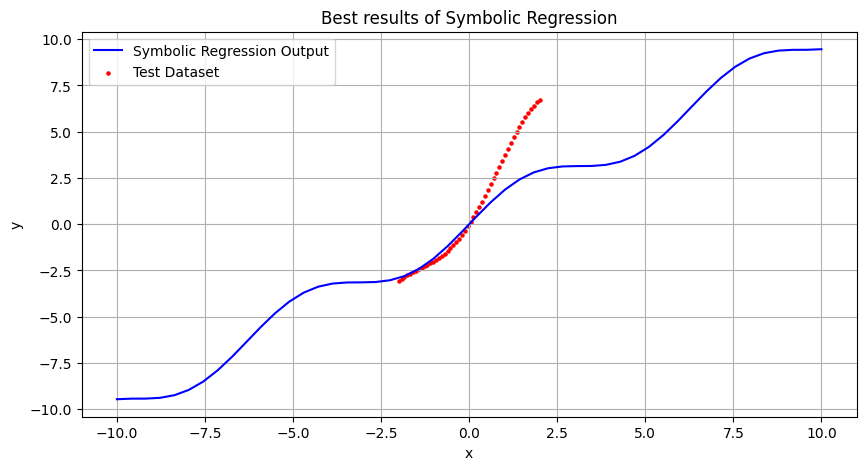

In [123]:
# First Dataset

C, y, x1, x2, x3, x4, x5, x6 = sympy.symbols('C, y, x1, x2, x3, x4, x5, x6', real=True, positive=True)


dataset = np.zeros((50, 7))

#TODO
# First Dataset is 2*x + sin(x) + x*sin(x)
x_values = np.linspace(-2, 2, 50)
y_values = 2*x_values + np.sin(x_values) + x_values*np.sin(x_values)
dataset[:, 0] = y_values #TODO
dataset[:, 1] = x_values #TODO

## for optimization
x1_values = x_values
y1_values = y_values
##

# use evaluate function to find the expression
sympy_pred, string_pred = evaluate(dataset)
string_pred_dataset1 = string_pred
# print(string_pred)
print("Predicted expression:", string_pred, "\n\n")
expr1 = string_pred
if 'C' in string_pred:
    plot_symbolic(x1_values, y_values, string_pred.replace("C", "1"))
else:
    plot_symbolic(x1_values, y_values, string_pred)

In [32]:
# Parameter optimization using mse loss & Plot the results on two datasets.

Optimal constant C: 2.4853339295481374




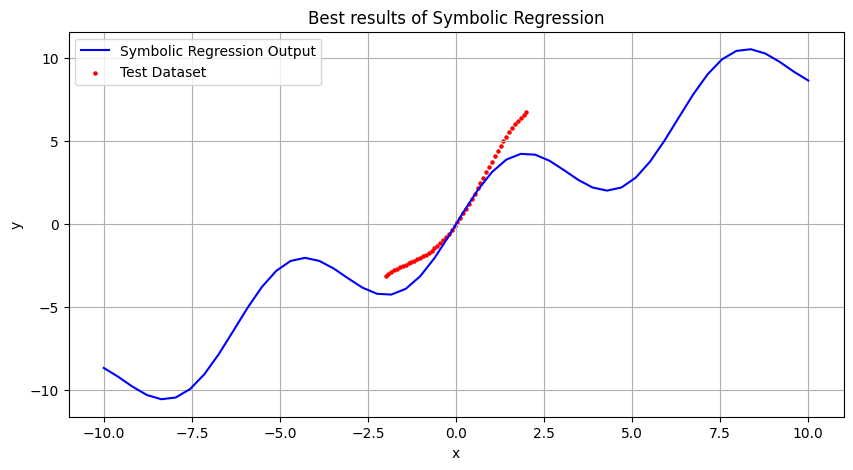

In [124]:
# Parameter optimization (example using scipy)
from scipy.optimize import minimize
def objective(params, x1, y_true, expr_str):
    y_pred = eval(expr_str, {"x1": x1, "C": params[0], "np": np, "sin": np.sin, "cos": np.cos, "exp": np.exp})
    return np.mean((y_pred - y_true)**2)

initial_guess = [1.0]
result = minimize(objective, initial_guess,
                 args=(dataset[:, 1], dataset[:, 0], string_pred),
                 method='BFGS')
optimal_C = result.x[0]

print(f"Optimal constant C: {optimal_C}\n\n")
plot_symbolic(x1_values, y_values, string_pred.replace("C", f"{optimal_C}"))

In [138]:
# Second Dataset

C, y, x1, x2, x3, x4, x5, x6 = sympy.symbols('C, y, x1, x2, x3, x4, x5, x6', real=True, positive=True)

# Make tabular dataset

# TODO
# Load Dataset 2
data = pd.read_csv('dataset.csv')
dataset = np.zeros((50, 7))  # Using 7 columns to match model expectations

dataset[:, 0] = data['y'].values   #TODO
dataset[:, 1] = data['x_1'].values #TODO
dataset[:, 2] = data['x_2'].values #TODO

# use evaluate function to find the expression
sympy_pred, string_pred = evaluate(dataset)
string_pred_dataset2 = string_pred
# print(string_pred)
print("Predicted expression:", string_pred)

Predicted expression: (-(x1))+((C)*(x1))*((x2)**2)


Optimal constant C: 18.35310597960242




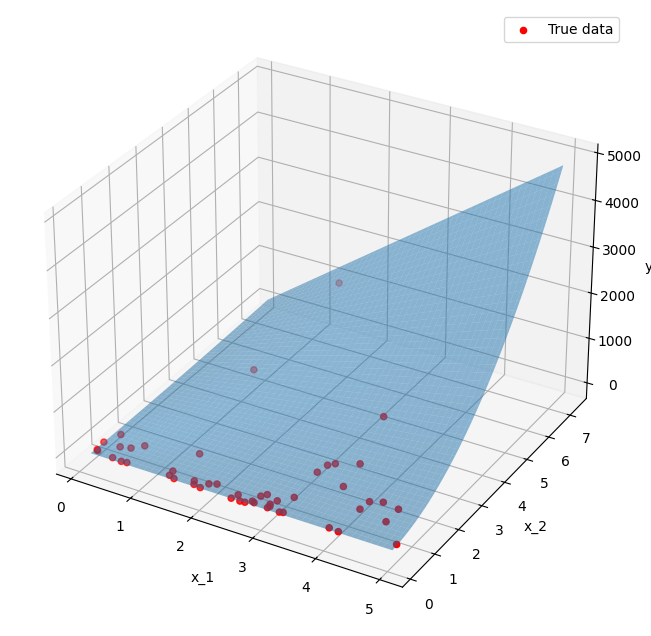

In [139]:
# Parameter optimization using mse loss (using scipy)
from scipy.optimize import minimize
df = data
def objective(params, x1, x2, y_true, expr_str):
    y_pred = eval(expr_str, {"x1": x1, "x2": x2, "C": params[0], "np": np, "sin": np.sin, "cos": np.cos, "exp": np.exp})
    return np.mean((y_pred - y_true)**2)

initial_guess = [1.0]
result = minimize(objective, initial_guess,
                 args=(df['x_1'].values, df['x_2'].values, df['y'].values, string_pred),
                 method='BFGS')
optimal_C = result.x[0]

print(f"Optimal constant C: {optimal_C}\n\n")

# Plotting
x1_vals = np.linspace(df['x_1'].min(), df['x_1'].max(), 100)
x2_vals = np.linspace(df['x_2'].min(), df['x_2'].max(), 100)
X1, X2 = np.meshgrid(x1_vals, x2_vals)
Y = eval(string_pred, {"x1": X1, "x2": X2, "C": optimal_C, "np": np, "sin": np.sin, "cos": np.cos, "exp": np.exp})

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(df['x_1'], df['x_2'], df['y'], c='r', marker='o', label='True data')
ax.plot_surface(X1, X2, Y, alpha=0.5)
ax.set_xlabel('x_1')
ax.set_ylabel('x_2')
ax.set_zlabel('y')
plt.legend()
plt.show()

In [140]:
# Parameter optimization using mse loss

## Optimize constant for first dataset
from scipy.optimize import minimize

def optimize_constant(expr_str, x_data, y_data):
    def loss(C):
        y_pred = eval(expr_str, {"x1": x_data, "C": C[0], "np": np, "sin": np.sin, "cos": np.cos, "exp": np.exp})
        return np.mean((y_pred - y_data)**2)

    result = minimize(loss, x0=[0.0], method='L-BFGS-B')
    return result.x[0]

# Optimize constants (if expression has placeholders)
if 'C' in string_pred_dataset1:
    optimal_C1 = optimize_constant(string_pred_dataset1, x_values, y_values)
    final_expr1 = str(string_pred_dataset1).replace("C", str(optimal_C1))
else:
    final_expr1 = string_pred_dataset1

# optimal_C1 = optimize_constant(string_pred_dataset1, x_values, y_values)
# final_expr1 = str(string_pred_dataset1).replace("C", str(optimal_C1))

print(f"Optimal constant for first dataset: {optimal_C1:.6f}")
print(f"Final expression for first dataset: {final_expr1}")
print("---------------------")

## Optimize constant for second dataset
def optimize_constants(expr_str, x1_data, x2_data, y_data):
    def loss(params):
        # C, a, b = params
        # y_pred = eval(expr_str, {"x1": x1_data, "x2": x2_data, "C": C, "a": a, "b": b, "np": np})
        C = params
        y_pred = eval(expr_str, {"x1": x1_data, "x2": x2_data, "C": C, "np": np, "sin": np.sin, "cos": np.cos, "exp": np.exp})
        return np.mean((y_pred - y_data)**2)

    # result = minimize(loss, x0=[1.0, 1.0, 1.0], method='L-BFGS-B')
    result = minimize(loss, x0=[1.0], method='L-BFGS-B')
    return result.x[0]

if 'C' in string_pred_dataset2:
    opt_C = optimize_constants(
        string_pred, data['x_1'].values, data['x_2'].values, data['y'].values
    )
    final_expr2 = str(string_pred_dataset2).replace("C", str(opt_C))
else:
    final_expr2 = string_pred_dataset2

print(f"Optimal constant for second dataset: {opt_C:.6f}")
print(f"Final expression for first dataset: {final_expr2}")

Optimal constant for first dataset: 2.485334
Final expression for first dataset: (x1)+(((2.485333938297505)*(sin(x1))))
---------------------
Optimal constant for second dataset: 18.353106
Final expression for first dataset: (-(x1))+((18.353105654115886)*(x1))*((x2)**2)
